# CSEN903 Milestone 1 — Formula 1 Podium Prediction
## Step 1 · Dataset setup and initial audit

**Question:** What does this fixed 1950–2024 dataset contain, and what quality issues must we resolve before cleaning or modeling?

This notebook uses the 14 CSV tables in the Kaggle Formula 1 dataset. In Step 1, we inspect the raw tables without altering them. We document table grain, keys, relationships, missingness, coverage, and duplicate driver–race records. All findings below are generated by code, not manual row inspection.

**Prediction context:** One eligible driver entering one race; target is a podium finish (`positionOrder <= 3`). The intended prediction time is after qualifying and before the race. Post-race columns are audited here but must not become model features.

**Sources:** [Milestone description](https://cms.guc.edu.eg/Uploads/70/573/72385/GUC_573_70_72385_2026-09-30T15_57_46.pdf) · [F1 beginner guide](https://cms.guc.edu.eg/Uploads/70/573/72385/GUC_573_70_72385_2026-09-30T15_52_20.pdf) · [Kaggle dataset](https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 150)

EXPECTED_TABLES = {
    "circuits", "constructors", "constructor_results", "constructor_standings",
    "drivers", "driver_standings", "races", "results", "qualifying",
    "lap_times", "pit_stops", "sprint_results", "seasons", "status"
}
INPUT_ROOT = Path("/kaggle/input")
PREFERRED_DATA_DIR = INPUT_ROOT / "datasets" / "rohanrao" / "formula-1-world-championship-1950-2020"
if (PREFERRED_DATA_DIR / "results.csv").exists():
    DATA_DIR = PREFERRED_DATA_DIR
else:
    results_files = sorted(INPUT_ROOT.rglob("results.csv"))
    print("results.csv candidates:", results_files)
    assert len(results_files) == 1, (
        "Attach the Rohan Rao Formula 1 dataset in Kaggle Add Data, then rerun. "
        f"Expected one results.csv; found {len(results_files)}."
    )
    DATA_DIR = results_files[0].parent
print("Using dataset directory:", DATA_DIR)
print("Available CSV files:", sorted(p.name for p in DATA_DIR.glob("*.csv")))
assert EXPECTED_TABLES == {p.stem for p in DATA_DIR.glob("*.csv")}, "Expected exactly the 14 project tables."

Using dataset directory: /kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020
Available CSV files: ['circuits.csv', 'constructor_results.csv', 'constructor_standings.csv', 'constructors.csv', 'driver_standings.csv', 'drivers.csv', 'lap_times.csv', 'pit_stops.csv', 'qualifying.csv', 'races.csv', 'results.csv', 'seasons.csv', 'sprint_results.csv', 'status.csv']


### 1. Raw table inventory and schema

**Why:** The dataset is relational. We first verify that all expected source tables are present, learn their row counts and columns, and record the types pandas initially infers. We deliberately preserve blank strings and the literal `\N` in this raw read so the later cleaning step can measure exactly what changes. A row count here describes source volume, not the number of valid race starts.

**Output:** A compact inventory plus a complete column-level schema for the 14 tables.

,table,rows,columns,memory_mb
0,circuits,77,9,0.03
1,constructor_results,12625,5,1.05
2,constructor_standings,13391,7,1.32
3,constructors,212,5,0.06
4,driver_standings,34863,7,3.44
5,drivers,861,9,0.42
6,lap_times,589081,6,57.14
7,pit_stops,11371,7,1.73
8,qualifying,10494,9,2.23
9,races,1125,18,0.93


Total source columns listed: 120


,table,column,raw_pandas_dtype
0,circuits,circuitId,int64
1,circuits,circuitRef,object
2,circuits,name,object
3,circuits,location,object
4,circuits,country,object
5,circuits,lat,float64
6,circuits,lng,float64
7,circuits,alt,int64
8,circuits,url,object
9,constructor_results,constructorResultsId,int64


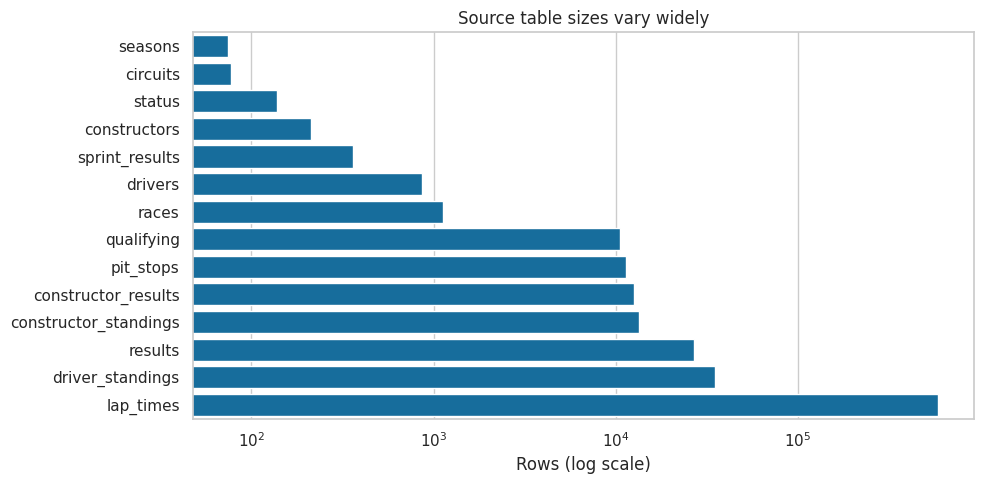

In [2]:
tables = {
    name: pd.read_csv(DATA_DIR / f"{name}.csv", keep_default_na=False, low_memory=False)
    for name in sorted(EXPECTED_TABLES)
}
inventory = pd.DataFrame([
    {"table": name, "rows": len(df), "columns": df.shape[1],
     "memory_mb": round(df.memory_usage(deep=True).sum() / 1e6, 2)}
    for name, df in tables.items()
]).sort_values("table").reset_index(drop=True)
assert len(tables) == 14
display(inventory)

schema = pd.concat([
    pd.DataFrame({"table": name, "column": df.columns,
                  "raw_pandas_dtype": df.dtypes.astype(str).values})
    for name, df in tables.items()
], ignore_index=True)
print(f"Total source columns listed: {len(schema)}")
display(schema)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=inventory.sort_values("rows"), x="rows", y="table", ax=ax)
ax.set_xscale("log")
ax.set_xlabel("Rows (log scale)")
ax.set_ylabel("")
ax.set_title("Source table sizes vary widely")
plt.tight_layout()
plt.show()

### 2. Candidate keys and table relationships

**Why:** The milestone depends on reliable multi-table joins. We check whether each candidate source key is present and unique, and whether foreign-key values point to existing parent rows. These are audit results, not automatic deletion rules: any exception needs investigation before cleaning.

**Join map:** `results` connects a race, driver, constructor, and finishing status. `races` connects to `circuits`; `qualifying` and standings connect by race and driver/constructor IDs. Lap and pit-stop tables have finer grains than driver–race and must not be joined directly into a modeling table without aggregation.

In [3]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"], "driver_standings": ["driverStandingsId"],
    "races": ["raceId"], "results": ["resultId"],
    "qualifying": ["qualifyId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "sprint_results": ["resultId"], "seasons": ["year"],
    "status": ["statusId"]
}
missing_token = chr(92) + "N"
key_audit = []
for name, key in PRIMARY_KEYS.items():
    df = tables[name]
    null_key_rows = df[key].isna().any(axis=1)
    null_key_rows |= df[key].astype(str).isin(["", missing_token]).any(axis=1)
    key_audit.append({"table": name, "candidate_key": ", ".join(key),
                      "rows": len(df), "null_key_rows": int(null_key_rows.sum()),
                      "duplicate_key_rows": int(df.duplicated(key, keep=False).sum())})
key_audit = pd.DataFrame(key_audit).sort_values("table")
display(key_audit)

FOREIGN_KEYS = [
    ("races", "circuitId", "circuits", "circuitId"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId"),
    ("races", "year", "seasons", "year")
]
fk_audit = []
for child, column, parent, parent_key in FOREIGN_KEYS:
    values = tables[child][column]
    missing = values.isna() | values.astype(str).isin(["", missing_token])
    orphan = ~missing & ~values.isin(tables[parent][parent_key])
    fk_audit.append({"child_column": f"{child}.{column}",
                     "parent_column": f"{parent}.{parent_key}",
                     "missing_rows": int(missing.sum()),
                     "orphan_rows": int(orphan.sum()),
                     "orphan_distinct_values": int(values[orphan].nunique())})
fk_audit = pd.DataFrame(fk_audit)
display(fk_audit)
print("Key failures:", int(key_audit[["null_key_rows", "duplicate_key_rows"]].sum().sum()))
print("Foreign-key orphan rows across checked links:", int(fk_audit["orphan_rows"].sum()))

,table,candidate_key,rows,null_key_rows,duplicate_key_rows
0,circuits,circuitId,77,0,0
2,constructor_results,constructorResultsId,12625,0,0
3,constructor_standings,constructorStandingsId,13391,0,0
1,constructors,constructorId,212,0,0
5,driver_standings,driverStandingsId,34863,0,0
4,drivers,driverId,861,0,0
9,lap_times,"raceId, driverId, lap",589081,0,0
10,pit_stops,"raceId, driverId, stop",11371,0,0
8,qualifying,qualifyId,10494,0,0
6,races,raceId,1125,0,0


,child_column,parent_column,missing_rows,orphan_rows,orphan_distinct_values
0,races.circuitId,circuits.circuitId,0,0,0
1,results.raceId,races.raceId,0,0,0
2,results.driverId,drivers.driverId,0,0,0
3,results.constructorId,constructors.constructorId,0,0,0
4,results.statusId,status.statusId,0,0,0
5,qualifying.raceId,races.raceId,0,0,0
6,qualifying.driverId,drivers.driverId,0,0,0
7,qualifying.constructorId,constructors.constructorId,0,0,0
8,driver_standings.raceId,races.raceId,0,0,0
9,driver_standings.driverId,drivers.driverId,0,0,0


Key failures: 0
Foreign-key orphan rows across checked links: 0


### 3. Raw missingness and sentinel values

**Why:** These CSVs use both blank fields and the literal `\N`. They mean unavailable data, but some absences are structural: a driver eliminated in Q1 cannot have Q2 or Q3 times. We count each marker before replacing anything. Step 2 will decide how to type and handle fields based on their meaning.

**Output:** Per-column counts, missingness rates, and a plot of the most affected columns. A high rate alone is not a reason to drop a column.

Columns audited: 120
Literal sentinel cells: 160076
Blank cells: 68


,table,column,rows,sentinel_N,blank,parsed_null,missing_n,missing_pct
0,constructor_results,status,12625,12608,0,0,12608,99.865347
1,races,sprint_time,1125,1110,0,0,1110,98.666667
2,races,sprint_date,1125,1107,0,0,1107,98.400000
3,races,fp3_time,1125,1072,0,0,1072,95.288889
4,races,fp1_time,1125,1057,0,0,1057,93.955556
5,races,fp2_time,1125,1057,0,0,1057,93.955556
6,races,quali_time,1125,1057,0,0,1057,93.955556
7,races,fp3_date,1125,1053,0,0,1053,93.600000
8,drivers,number,861,802,0,0,802,93.147503
9,races,fp1_date,1125,1035,0,0,1035,92.000000


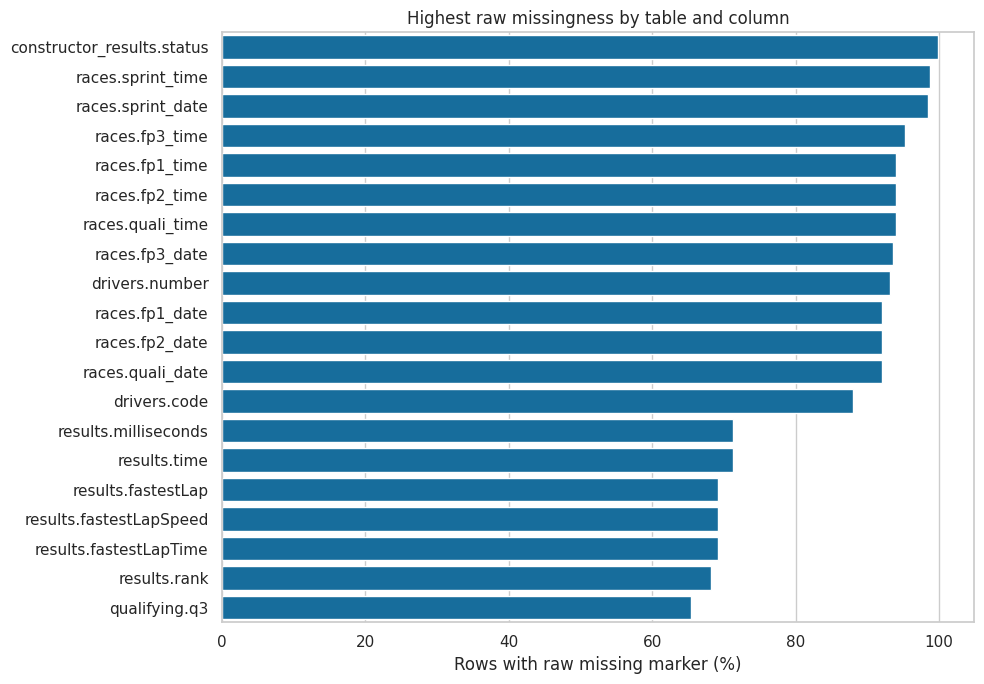

In [4]:
missing_rows = []
for name, df in tables.items():
    for column in df.columns:
        s = df[column]
        sentinel_n = int((s == missing_token).sum())
        blank_n = int((s == "").sum())
        true_null_n = int(s.isna().sum())
        missing_rows.append({
            "table": name, "column": column, "rows": len(df),
            "sentinel_N": sentinel_n, "blank": blank_n, "parsed_null": true_null_n,
            "missing_n": sentinel_n + blank_n + true_null_n,
            "missing_pct": 100 * (sentinel_n + blank_n + true_null_n) / len(df)
        })
missing_audit = pd.DataFrame(missing_rows).sort_values(
    ["missing_pct", "table", "column"], ascending=[False, True, True]
).reset_index(drop=True)
print("Columns audited:", len(missing_audit))
print("Literal sentinel cells:", int(missing_audit["sentinel_N"].sum()))
print("Blank cells:", int(missing_audit["blank"].sum()))
display(missing_audit)

plot_missing = missing_audit[missing_audit["missing_n"] > 0].head(20).copy()
plot_missing["field"] = plot_missing["table"] + "." + plot_missing["column"]
fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=plot_missing, x="missing_pct", y="field", ax=ax)
ax.set(xlabel="Rows with raw missing marker (%)", ylabel="",
       title="Highest raw missingness by table and column")
plt.tight_layout()
plt.show()

### 4. Time coverage and qualifying availability

**Why:** A model trained across F1 history must account for uneven coverage and rule changes. `qualifying.csv` does not span the whole championship. We measure its driver–race match rate by season instead of assuming modern qualifying detail exists in older years. We also validate race dates and inspect how many races and entries appear per year.

**Denominator for the qualifying plot:** Distinct `(raceId, driverId)` pairs in raw `results.csv` for each year. This is a coverage diagnostic, not yet the final eligible-start population.

Race years: 1950 to 2024
Race dates: 1950-05-13 to 2024-12-08
Unparseable race dates: 0


,table,rows,first_year,last_year,distinct_races,unknown_race_rows
2,driver_standings,34863,1950,2024,1125,0
7,results,26759,1950,2024,1125,0
6,races,1125,1950,2024,1125,0
0,constructor_results,12625,1958,2024,1060,0
1,constructor_standings,13391,1958,2024,1061,0
5,qualifying,10494,1994,2024,494,0
3,lap_times,589081,1996,2024,544,0
4,pit_stops,11371,2011,2024,285,0
8,sprint_results,360,2021,2024,18,0


,year,races,driver_race_pairs,pairs_with_qualifying,qualifying_match_pct
0,1950,7,156,0,0.000000
1,1951,8,175,0,0.000000
2,1952,8,212,0,0.000000
3,1953,9,230,0,0.000000
4,1954,9,213,0,0.000000
5,1955,7,162,0,0.000000
6,1956,8,178,0,0.000000
7,1957,8,163,0,0.000000
8,1958,11,238,0,0.000000
9,1959,9,195,0,0.000000


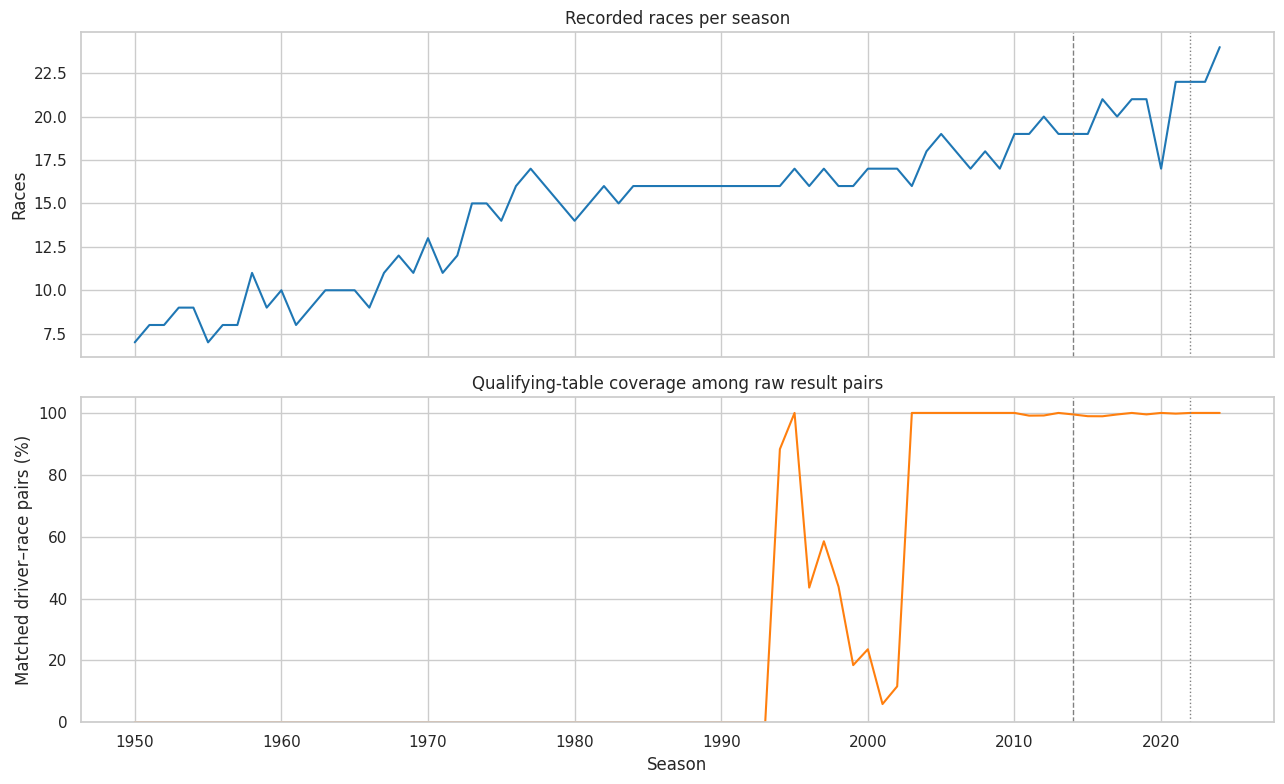

In [5]:
races = tables["races"].copy()
race_dates = pd.to_datetime(races["date"], errors="coerce")
print("Race years:", int(races["year"].min()), "to", int(races["year"].max()))
print("Race dates:", race_dates.min().date(), "to", race_dates.max().date())
print("Unparseable race dates:", int(race_dates.isna().sum()))

linked_coverage = []
for name, df in tables.items():
    if "raceId" in df.columns:
        years = df[["raceId"]].merge(races[["raceId", "year"]], on="raceId", how="left", validate="many_to_one")["year"]
        linked_coverage.append({"table": name, "rows": len(df),
                                "first_year": years.min(), "last_year": years.max(),
                                "distinct_races": df["raceId"].nunique(),
                                "unknown_race_rows": int(years.isna().sum())})
display(pd.DataFrame(linked_coverage).sort_values("first_year"))

entries = tables["results"][["raceId", "driverId"]].drop_duplicates().merge(
    races[["raceId", "year"]], on="raceId", how="left", validate="many_to_one"
)
qual_pairs = tables["qualifying"][["raceId", "driverId"]].drop_duplicates().assign(has_qualifying=1)
entry_coverage = entries.merge(qual_pairs, on=["raceId", "driverId"], how="left", validate="one_to_one")
coverage = races.groupby("year").agg(races=("raceId", "nunique"))
coverage["driver_race_pairs"] = entries.groupby("year").size()
coverage["pairs_with_qualifying"] = entry_coverage.groupby("year")["has_qualifying"].sum().astype(int)
coverage["qualifying_match_pct"] = 100 * coverage["pairs_with_qualifying"] / coverage["driver_race_pairs"]
display(coverage.reset_index())

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(coverage.index, coverage["races"], color="tab:blue")
axes[0].set(ylabel="Races", title="Recorded races per season")
axes[1].plot(coverage.index, coverage["qualifying_match_pct"], color="tab:orange")
axes[1].set(xlabel="Season", ylabel="Matched driver–race pairs (%)",
            title="Qualifying-table coverage among raw result pairs", ylim=(0, 105))
for ax in axes:
    ax.axvline(2014, color="gray", linestyle="--", linewidth=1)
    ax.axvline(2022, color="gray", linestyle=":", linewidth=1)
plt.tight_layout()
plt.show()

### 5. Driver–race grain and shared-drive duplicates

**Why:** The modeling target needs one prediction per driver per race, but early shared drives can give a driver more than one result row in the same race. We measure the duplicate groups and inspect representative records before choosing a retention rule. Distinct `resultId` values do not guarantee a unique driver–race grain.

**Output:** Duplicate row and group counts, years affected, podium-label conflicts, a yearly plot, and representative rows. Step 2 will choose and justify the actual deduplication rule.

Raw result rows: 26759
Distinct driver–race pairs: 26668
Duplicate driver–race groups: 85
Rows in duplicate groups: 176
Extra rows beyond one per pair: 91
Duplicate groups with conflicting podium labels: 21
Duplicate years: 1950 to 1978


,year,name,forename,surname,raceId,driverId,resultId,constructorId,grid,positionOrder,positionText,points,statusId,podium_label
84,1950,Indianapolis 500,Tony,Bettenhausen,835,529,20097,150,8,31,R,0.0,67,False
88,1950,Indianapolis 500,Tony,Bettenhausen,835,529,20179,113,9,5,5,1.0,12,False
85,1950,French Grand Prix,Louis,Rosier,838,627,20143,154,6,12,R,0.0,25,False
89,1950,French Grand Prix,Louis,Rosier,838,627,20182,154,15,6,6,0.0,18,False
86,1950,Italian Grand Prix,Juan,Fangio,839,579,20164,51,1,15,R,1.0,6,False
91,1950,Italian Grand Prix,Juan,Fangio,839,579,20184,51,7,13,R,0.0,5,False
87,1950,Italian Grand Prix,Alberto,Ascari,839,647,20166,6,2,17,R,0.0,5,False
90,1950,Italian Grand Prix,Alberto,Ascari,839,647,20183,6,6,2,2,3.0,1,True
81,1951,French Grand Prix,Juan,Fangio,828,579,19928,51,1,11,11,0.0,115,False
92,1951,French Grand Prix,Juan,Fangio,828,579,20186,51,7,1,1,5.0,1,True


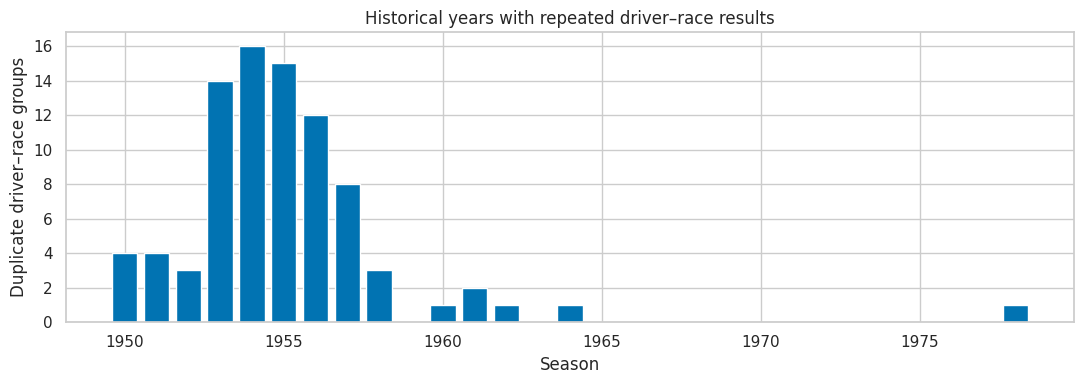

In [6]:
results = tables["results"]
pair_sizes = results.groupby(["raceId", "driverId"]).size().rename("rows_in_pair").reset_index()
duplicate_pairs = pair_sizes[pair_sizes["rows_in_pair"] > 1].copy()
duplicate_rows = results.merge(duplicate_pairs, on=["raceId", "driverId"], how="inner", validate="many_to_one")
duplicate_rows = duplicate_rows.merge(races[["raceId", "year", "name"]], on="raceId", how="left", validate="many_to_one")
duplicate_rows = duplicate_rows.merge(
    tables["drivers"][["driverId", "forename", "surname"]],
    on="driverId", how="left", validate="many_to_one"
)
duplicate_rows["podium_label"] = duplicate_rows["positionOrder"] <= 3
label_conflicts = duplicate_rows.groupby(["raceId", "driverId"])["podium_label"].nunique().gt(1).sum()
print("Raw result rows:", len(results))
print("Distinct driver–race pairs:", len(pair_sizes))
print("Duplicate driver–race groups:", len(duplicate_pairs))
print("Rows in duplicate groups:", len(duplicate_rows))
print("Extra rows beyond one per pair:", int((duplicate_pairs["rows_in_pair"] - 1).sum()))
print("Duplicate groups with conflicting podium labels:", int(label_conflicts))
print("Duplicate years:", int(duplicate_rows["year"].min()), "to", int(duplicate_rows["year"].max()))

sample_columns = ["year", "name", "forename", "surname", "raceId", "driverId",
                  "resultId", "constructorId", "grid", "positionOrder",
                  "positionText", "points", "statusId", "podium_label"]
display(duplicate_rows.sort_values(["year", "raceId", "driverId", "resultId"])[sample_columns].head(24))

dup_by_year = duplicate_pairs.merge(races[["raceId", "year"]], on="raceId", validate="many_to_one").groupby("year").size()
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(dup_by_year.index, dup_by_year.values)
ax.set(xlabel="Season", ylabel="Duplicate driver–race groups",
       title="Historical years with repeated driver–race results")
plt.tight_layout()
plt.show()

### 6. Preliminary prediction-population EDA

**Why:** Podium outcomes are uncommon, and historical field sizes differ from modern races. We plot the raw podium rate and the distribution of starting-grid values to see how the prediction population changes by era. A `grid` value of zero needs investigation with `status` before we decide whether the row represents an actual start.

**Important limit:** These are raw result rows, including shared-drive duplicates and non-starters. The rates are descriptive audit figures, **not final modeling rates**.

Raw podium rows: 3397
Raw overall podium rate: 12.69%
Raw grid=0 rows: 1638


,year,result_rows,podium_rows,grid_zero_rows,podium_pct,grid_zero_pct
0,1950,160,22,0,13.750000,0.000000
1,1951,179,28,0,15.642458,0.000000
2,1952,215,24,12,11.162791,5.581395
3,1953,246,29,0,11.788618,0.000000
4,1954,230,29,3,12.608696,1.304348
5,1955,180,27,7,15.000000,3.888889
6,1956,190,29,8,15.263158,4.210526
7,1957,171,25,5,14.619883,2.923977
8,1958,241,33,17,13.692946,7.053942
9,1959,195,27,16,13.846154,8.205128


Most common statuses among grid=0 rows:


,statusId,status,rows
0,81,Did not qualify,1013
1,97,Did not prequalify,331
2,54,Withdrew,164
3,11,+1 Lap,27
4,1,Finished,22
5,3,Accident,20
6,82,Injury,8
7,12,+2 Laps,7
8,5,Engine,6
9,2,Disqualified,6


Position-text values among grid=0 rows:


,positionText,rows
0,F,1348
1,W,203
2,R,14
3,17,9
4,13,7
5,E,7
6,10,7
7,D,6
8,18,6
9,16,6


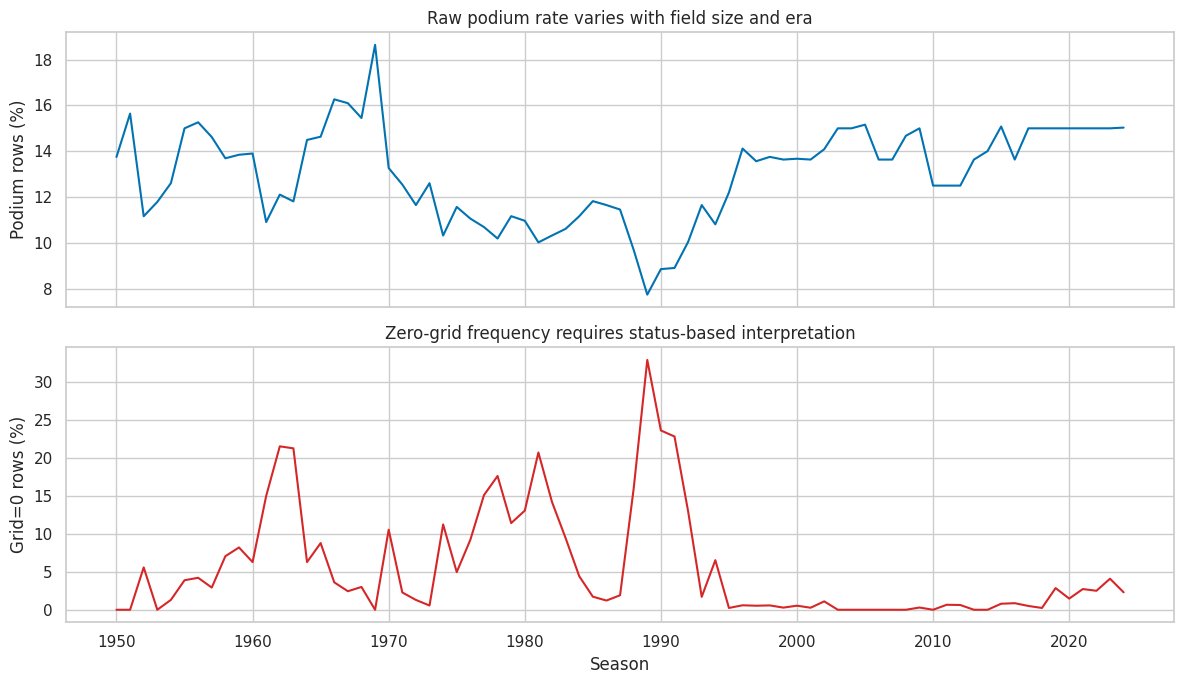

In [7]:
raw_results = results.merge(races[["raceId", "year"]], on="raceId", how="left", validate="many_to_one")
raw_results["podium_raw"] = raw_results["positionOrder"] <= 3
raw_results["grid_zero"] = raw_results["grid"] == 0
yearly = raw_results.groupby("year").agg(
    result_rows=("resultId", "size"),
    podium_rows=("podium_raw", "sum"),
    grid_zero_rows=("grid_zero", "sum")
)
yearly["podium_pct"] = 100 * yearly["podium_rows"] / yearly["result_rows"]
yearly["grid_zero_pct"] = 100 * yearly["grid_zero_rows"] / yearly["result_rows"]
print("Raw podium rows:", int(raw_results["podium_raw"].sum()))
print("Raw overall podium rate: {:.2f}%".format(100 * raw_results["podium_raw"].mean()))
print("Raw grid=0 rows:", int(raw_results["grid_zero"].sum()))
display(yearly.reset_index())

zero_status = raw_results.loc[raw_results["grid_zero"]].merge(
    tables["status"][["statusId", "status"]], on="statusId", how="left", validate="many_to_one"
)
print("Most common statuses among grid=0 rows:")
display(zero_status.groupby(["statusId", "status"]).size().rename("rows").sort_values(ascending=False).head(20).reset_index())
print("Position-text values among grid=0 rows:")
display(zero_status["positionText"].value_counts().head(12).rename_axis("positionText").reset_index(name="rows"))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(yearly.index, yearly["podium_pct"])
axes[0].set(ylabel="Podium rows (%)", title="Raw podium rate varies with field size and era")
axes[1].plot(yearly.index, yearly["grid_zero_pct"], color="tab:red")
axes[1].set(xlabel="Season", ylabel="Grid=0 rows (%)",
            title="Zero-grid frequency requires status-based interpretation")
plt.tight_layout()
plt.show()

### 7. Step 1 findings and decisions for cleaning

**Verified findings from the attached 1950–2024 dataset**

- The ZIP supplies all 14 expected tables: 1,125 races, 26,759 raw result rows, and 120 source columns in total. Race dates parse from 13 May 1950 through 8 December 2024.
- Every candidate primary key checked is non-null and unique, and all 23 checked foreign-key links have zero orphan values. This supports the planned joins, but finer-grain tables still require careful aggregation.
- The raw read contains **160,076 literal `\N` cells** and **68 blank cells**. Several near-empty fields reflect historical or event-specific coverage, including sprint dates and practice times; their rates should not trigger automatic deletion.
- Qualifying records cover 1994–2024, while the results and race tables cover 1950–2024. Coverage must therefore be handled by season. The 2024 raw driver–race pairs all match qualifying records; older years do not.
- `results.csv` contains **26,668 distinct driver–race pairs**, but **85 pairs repeat** (176 rows, 91 extra rows), in years 1950–1978. **21 repeated pairs have conflicting raw podium labels**, so the retention rule can change the target and needs a documented sensitivity check.
- **1,638 rows have `grid = 0`**. Most are coded Did not qualify (1,013), Did not prequalify (331), or Withdrew (164), but some are classified as Finished or `+1 Lap`. Therefore `grid = 0` is not by itself a safe non-starter rule.
- The uncleaned result-row podium rate is **12.69%**. It is provisional because duplicates and non-starters remain.

**Decisions to resolve in Step 2**

1. Choose and justify which shared-drive result represents each driver–race, using the 21 label-conflict groups as a sensitivity check.
2. Define actual race-start eligibility from status, grid, and classification evidence; investigate zero-grid finishers separately.
3. Replace sentinels on copies, parse dates and duration fields, and distinguish structural missingness from unusable values.
4. Re-run these distributions after cleaning and quantify what each rule changes.

The raw tables and their Kaggle input files remain untouched throughout this audit.

## Step 2 · Clean copies and establish the driver–race grain

**Goal:** Turn the audited relational data into a typed, validated table with one row per eligible `(raceId, driverId)`. We keep the original `tables` dictionary and Kaggle CSVs unchanged. Every exclusion and duplicate decision below is measured before it is applied.

**Prediction cutoff:** After qualifying and before the race. Post-race fields may define the target and support audits, but they must never enter the eventual feature matrix.

### 8. Standardize missing values and semantic types

**Why:** A literal `\N` or empty string is not a real category, date, number, or duration. We replace these markers on copies, parse dates and numeric fields, and add seconds columns for duration fields. Race-result time mixes a winner’s elapsed time with `+gap` notation, so we parse absolute durations into a separate column and leave the original text available for audit. Current-race times remain post-race data.

In [8]:
clean_tables = {
    name: df.replace({missing_token: pd.NA, "": pd.NA}).copy(deep=True)
    for name, df in tables.items()
}
assert all(clean_tables[name] is not tables[name] for name in tables)

DATE_COLUMNS = {
    "drivers": ["dob"],
    "races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]
}
NUMERIC_COLUMNS = {
    "circuits": ["alt"], "drivers": ["number"],
    "results": ["number", "position", "milliseconds", "fastestLap", "rank", "fastestLapSpeed"],
    "sprint_results": ["number", "position", "milliseconds", "fastestLap"]
}
type_checks = []
for name, columns in DATE_COLUMNS.items():
    for column in columns:
        before = clean_tables[name][column]
        converted = pd.to_datetime(before, errors="coerce")
        type_checks.append({"table": name, "column": column, "type": "datetime",
                            "new_nulls_from_parse": int((before.notna() & converted.isna()).sum())})
        clean_tables[name][column] = converted
for name, columns in NUMERIC_COLUMNS.items():
    for column in columns:
        before = clean_tables[name][column]
        converted = pd.to_numeric(before, errors="coerce")
        type_checks.append({"table": name, "column": column, "type": "numeric",
                            "new_nulls_from_parse": int((before.notna() & converted.isna()).sum())})
        clean_tables[name][column] = converted

def duration_seconds(value):
    """Parse seconds, m:ss.sss, or h:mm:ss.sss; leave gaps and unknowns missing."""
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    if text.startswith("+"):
        return np.nan
    parts = text.split(":")
    if len(parts) > 3:
        return np.nan
    try:
        numbers = [float(part) for part in parts]
    except ValueError:
        return np.nan
    return sum(number * 60**power for power, number in enumerate(reversed(numbers)))

DURATION_COLUMNS = {
    "qualifying": ["q1", "q2", "q3"],
    "lap_times": ["time"], "pit_stops": ["duration"],
    "results": ["fastestLapTime", "time"],
    "sprint_results": ["fastestLapTime", "time"]
}
for name, columns in DURATION_COLUMNS.items():
    for column in columns:
        new_column = ("absolute_race_time_seconds" if column == "time" and name in ["results", "sprint_results"]
                      else f"{column}_seconds")
        clean_tables[name][new_column] = clean_tables[name][column].map(duration_seconds)
        available = clean_tables[name][column].notna()
        if column == "time" and name in ["results", "sprint_results"]:
            available &= ~clean_tables[name][column].astype(str).str.startswith("+")
        type_checks.append({"table": name, "column": new_column, "type": "duration_seconds",
                            "new_nulls_from_parse": int((available & clean_tables[name][new_column].isna()).sum())})

type_checks = pd.DataFrame(type_checks)
display(type_checks)
assert pd.api.types.is_datetime64_any_dtype(clean_tables["races"]["date"])
assert clean_tables["qualifying"]["q1_seconds"].dtype.kind == "f"
print("Original raw result-row count:", len(tables["results"]))
print("Clean-copy result-row count:", len(clean_tables["results"]))
print("Typed race-date range:", clean_tables["races"]["date"].min().date(), "to", clean_tables["races"]["date"].max().date())

,table,column,type,new_nulls_from_parse
0,drivers,dob,datetime,0
1,races,date,datetime,0
2,races,fp1_date,datetime,0
3,races,fp2_date,datetime,0
4,races,fp3_date,datetime,0
5,races,quali_date,datetime,0
6,races,sprint_date,datetime,0
7,circuits,alt,numeric,0
8,drivers,number,numeric,0
9,results,number,numeric,0


Original raw result-row count: 26759
Clean-copy result-row count: 26759
Typed race-date range: 1950-05-13 to 2024-12-08


### 9. Verify cleaned keys and missingness

The raw files remain unchanged. We now check that cleaning creates no new key collisions or broken links, and compare raw `\N` / blank placeholders with true missing values. Timing and finishing fields remain in clean audit tables but will not enter the pre-race feature table.

,table,null_key_rows,duplicate_key_excess
0,circuits,0,0
1,constructors,0,0
2,constructor_results,0,0
3,constructor_standings,0,0
4,drivers,0,0
5,driver_standings,0,0
6,races,0,0
7,results,0,0
8,qualifying,0,0
9,lap_times,0,0


,child,foreign_key,parent,orphan_rows
0,races,circuitId,circuits,0
1,results,raceId,races,0
2,results,driverId,drivers,0
3,results,constructorId,constructors,0
4,results,statusId,status,0
5,qualifying,raceId,races,0
6,qualifying,driverId,drivers,0
7,qualifying,constructorId,constructors,0
8,driver_standings,raceId,races,0
9,driver_standings,driverId,drivers,0


Total orphan rows across checked links: 0


,table,column,raw_placeholder_rows,clean_null_rows
19,results,time,19079,19079
20,results,milliseconds,19079,19079
23,results,fastestLapTime,18507,18507
21,results,fastestLap,18507,18507
24,results,fastestLapSpeed,18507,18507
22,results,rank,18249,18249
0,constructor_results,status,12608,12608
18,results,position,10953,10953
5,qualifying,q3,6865,6865
4,qualifying,q2,4647,4647


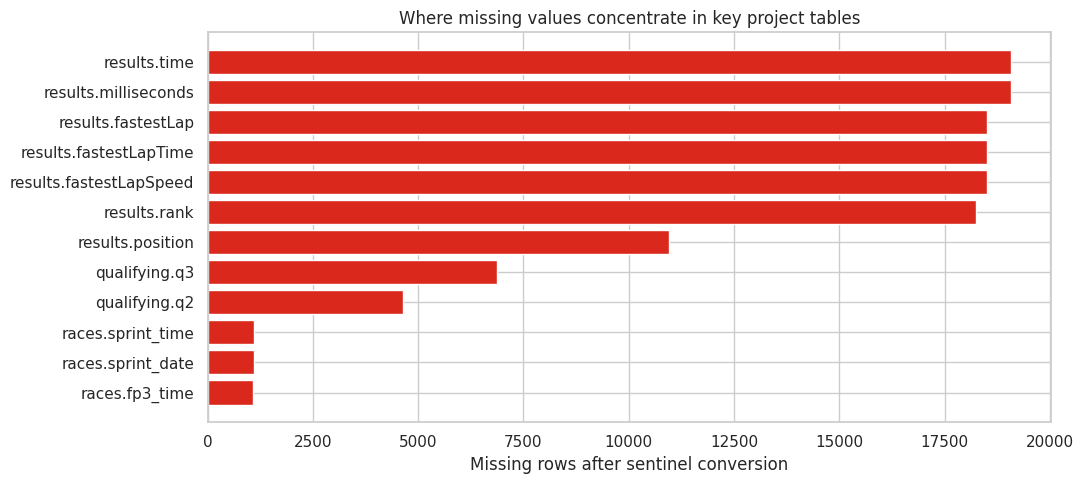

In [9]:
clean_key_checks = []
for name, key in PRIMARY_KEYS.items():
    frame = clean_tables[name]
    clean_key_checks.append((name, int(frame[key].isna().any(axis=1).sum()), int(frame.duplicated(key).sum())))
clean_key_checks = pd.DataFrame(clean_key_checks, columns=["table", "null_key_rows", "duplicate_key_excess"])
assert clean_key_checks[["null_key_rows", "duplicate_key_excess"]].to_numpy().sum() == 0

def fk_gap(child, child_col, parent, parent_col):
    values = clean_tables[child][child_col].dropna()
    return int((~values.isin(clean_tables[parent][parent_col].dropna())).sum())

clean_fk_checks = pd.DataFrame([
    (child, child_col, parent, fk_gap(child, child_col, parent, parent_col))
    for child, child_col, parent, parent_col in FOREIGN_KEYS
], columns=["child", "foreign_key", "parent", "orphan_rows"])
display(clean_key_checks, clean_fk_checks)
print("Total orphan rows across checked links:", clean_fk_checks.orphan_rows.sum())

missing_comparison = []
for name, original in tables.items():
    for column in original.columns:
        raw_placeholders = int(original[column].astype(str).isin([missing_token, ""]).sum())
        cleaned_nulls = int(clean_tables[name][column].isna().sum())
        if raw_placeholders or cleaned_nulls:
            missing_comparison.append((name, column, raw_placeholders, cleaned_nulls))
missing_comparison = pd.DataFrame(missing_comparison, columns=["table", "column", "raw_placeholder_rows", "clean_null_rows"])
assert (missing_comparison.clean_null_rows >= missing_comparison.raw_placeholder_rows).all()
display(missing_comparison.sort_values("clean_null_rows", ascending=False).head(20))
fig, ax = plt.subplots(figsize=(11, 5))
shown = missing_comparison.query("table in ['results', 'qualifying', 'drivers', 'races']").nlargest(12, "clean_null_rows")
ax.barh(shown.table + '.' + shown.column, shown.clean_null_rows, color='#da291c')
ax.invert_yaxis(); ax.set(xlabel="Missing rows after sentinel conversion", title="Where missing values concentrate in key project tables")
plt.tight_layout(); plt.show()

### 10. Historical shared drives: compare rules before collapsing rows

A result row is not always a driver–race. Older races can contain multiple entries for the same driver. We compare (1) the first stored result, (2) the best finishing row, and (3) a representative selected by a known starting grid position. The **podium label is driver-level**: a driver is positive if *any* of that driver's result rows for that race finished in the top three. This keeps a shared-drive podium and avoids using the finish to choose predictor fields.

Duplicate driver–race groups: 85 ; rows in them: 176 ; excess rows: 91


,representative_rule,rows_different_from_grid_rule,podiums_if_using_only_chosen_row,labels_different_from_any_row_target
0,start,0,3378,17
1,best,56,3395,0
2,first,27,3379,16


Duplicate pairs with conflicting row-level podium labels: 21
Podium-positive driver–race pairs under any-row target: 3395


,year,name,forename,surname,resultId,constructorId,grid,positionOrder,positionText,statusId
1,1957,British Grand Prix,Tony,Brooks,18806,118,3,1,1,1
4,1957,British Grand Prix,Tony,Brooks,20293,118,1,12,R,5
2,1957,British Grand Prix,Stirling,Moss,18817,118,1,12,R,5
3,1957,British Grand Prix,Stirling,Moss,20291,118,3,1,1,1
0,1960,Argentine Grand Prix,Stirling,Moss,18083,170,1,17,R,22
5,1960,Argentine Grand Prix,Stirling,Moss,22372,170,8,3,3,1


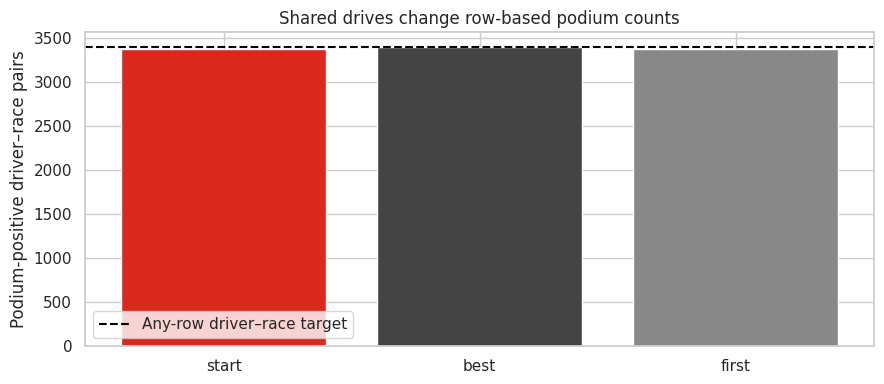

In [10]:
result_rows = clean_tables["results"].copy()
pair = ["raceId", "driverId"]
pair_sizes = result_rows.groupby(pair).size().rename("result_rows").reset_index()
dup_pairs = pair_sizes.query("result_rows > 1")
print("Duplicate driver–race groups:", len(dup_pairs), "; rows in them:", dup_pairs.result_rows.sum(), "; excess rows:", (dup_pairs.result_rows - 1).sum())
assert result_rows.resultId.is_unique

result_rows["has_positive_grid"] = result_rows.grid.gt(0)
result_rows["grid_priority"] = result_rows.grid.where(result_rows.grid.gt(0), 10_000)
start_rep = (result_rows.sort_values(pair + ["has_positive_grid", "grid_priority", "resultId"],
                                     ascending=[True, True, False, True, True])
             .drop_duplicates(pair).copy())
best_rep = result_rows.sort_values(pair + ["positionOrder", "resultId"]).drop_duplicates(pair)
first_rep = result_rows.sort_values(pair + ["resultId"]).drop_duplicates(pair)

podium_by_driver_race = (result_rows.assign(podium_row=result_rows.positionOrder.le(3))
                         .groupby(pair).podium_row.any().rename("podium").reset_index())
start_rep = start_rep.merge(podium_by_driver_race, on=pair, validate="one_to_one")
assert len(start_rep) == len(podium_by_driver_race) == len(pair_sizes)

alternatives = start_rep[pair + ["resultId", "positionOrder", "podium"]].rename(
    columns={"resultId": "start_resultId", "positionOrder": "start_finish"})
for label, frame in [("best", best_rep), ("first", first_rep)]:
    alternatives = alternatives.merge(frame[pair + ["resultId", "positionOrder"]].rename(
        columns={"resultId": f"{label}_resultId", "positionOrder": f"{label}_finish"}),
        on=pair, validate="one_to_one")
for label in ["start", "best", "first"]:
    alternatives[f"{label}_row_podium"] = alternatives[f"{label}_finish"].le(3)
comparison = pd.DataFrame([
    (label, int((alternatives[f"{label}_resultId"] != alternatives.start_resultId).sum()),
     int(alternatives[f"{label}_row_podium"].sum()),
     int((alternatives[f"{label}_row_podium"] != alternatives.podium).sum()))
    for label in ["start", "best", "first"]
], columns=["representative_rule", "rows_different_from_grid_rule", "podiums_if_using_only_chosen_row", "labels_different_from_any_row_target"])
display(comparison)
conflicts = result_rows.groupby(pair).positionOrder.apply(lambda s: s.le(3).nunique())
print("Duplicate pairs with conflicting row-level podium labels:", int((conflicts > 1).sum()))
print("Podium-positive driver–race pairs under any-row target:", int(start_rep.podium.sum()))
example_pairs = alternatives.loc[alternatives.start_row_podium != alternatives.podium, pair].head(3)
examples = result_rows.merge(example_pairs, on=pair, how="inner")
examples = examples.merge(clean_tables["races"][["raceId", "year", "name"]], on="raceId", validate="many_to_one")
examples = examples.merge(clean_tables["drivers"][["driverId", "forename", "surname"]], on="driverId", validate="many_to_one")
display(examples[["year", "name", "forename", "surname", "resultId", "constructorId", "grid", "positionOrder", "positionText", "statusId"]].sort_values(["year", "name", "surname", "resultId"]))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(comparison.representative_rule, comparison.podiums_if_using_only_chosen_row, color=["#da291c", "#444", "#888"])
ax.axhline(start_rep.podium.sum(), color="black", linestyle="--", label="Any-row driver–race target")
ax.set(ylabel="Podium-positive driver–race pairs", title="Shared drives change row-based podium counts")
ax.legend(); plt.tight_layout(); plt.show()

### 11. Define the prediction population at the post-qualifying cutoff

`grid = 0` is ambiguous: it includes DNQ/DNPQ/withdrawals **and** a small number of drivers recorded as finishing or retiring. We exclude failed qualification (`positionText = F`) and withdrawals with no assigned grid (`W` and grid 0). We retain other grid-zero records for audit and later sensitivity analysis. We also retain withdrawals with a positive grid because whether they subsequently start may be unknown at prediction time. The end-of-race `status` explains exclusions but is never used as a predictor.

All representative rows with grid 0: 1635


,positionText,status,driver_races
0,F,Did not qualify,1012
1,F,Did not prequalify,330
2,W,Withdrew,163
3,W,Accident,18
4,E,Excluded,6
5,D,Disqualified,6
6,W,Engine,6
7,W,Injury,6
8,10,+1 Lap,4
9,13,+1 Lap,4


,stage,rows,podium_labels,podium_rate_pct
0,Raw results rows,26759,3397,12.69
1,Unique driver–race pairs,26668,3395,12.73
2,Post-qualifying cohort,25100,3395,13.53


Excluded F: 1366 ; excluded W with grid 0: 202
Retained grid-0 cases: 87


,positionText,status,excluded_pairs
0,F,Did not qualify,1024
1,F,Did not prequalify,330
2,W,Withdrew,163
3,W,Accident,18
4,F,107% Rule,9
5,W,Engine,6
6,W,Injury,6
7,F,Injury,3
8,W,Safety concerns,2
9,W,Fuel system,2


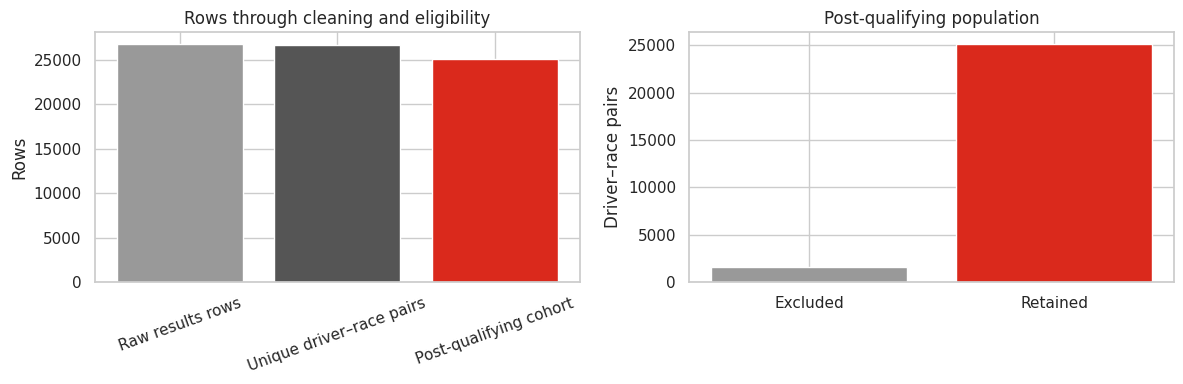

In [11]:
status_names = clean_tables["status"][["statusId", "status"]]
grid_zero_audit = start_rep.loc[start_rep.grid.eq(0)].merge(status_names, on="statusId", validate="many_to_one")
print("All representative rows with grid 0:", len(grid_zero_audit))
display(grid_zero_audit.groupby(["positionText", "status"], dropna=False).size().rename("driver_races").sort_values(ascending=False).head(20).reset_index())

failed_qualification = start_rep.positionText.eq("F")
no_grid_withdrawal = start_rep.positionText.eq("W") & start_rep.grid.eq(0)
eligible = ~(failed_qualification | no_grid_withdrawal)
modeling_representative = start_rep.loc[eligible].copy()
excluded = start_rep.loc[~eligible].merge(status_names, on="statusId", validate="many_to_one")
cohort_counts = pd.DataFrame([
    ("Raw results rows", len(result_rows), int(result_rows.positionOrder.le(3).sum())),
    ("Unique driver–race pairs", len(start_rep), int(start_rep.podium.sum())),
    ("Post-qualifying cohort", len(modeling_representative), int(modeling_representative.podium.sum()))
], columns=["stage", "rows", "podium_labels"])
cohort_counts["podium_rate_pct"] = (100 * cohort_counts.podium_labels / cohort_counts.rows).round(2)
display(cohort_counts)
print("Excluded F:", int(failed_qualification.sum()), "; excluded W with grid 0:", int(no_grid_withdrawal.sum()))
print("Retained grid-0 cases:", int(modeling_representative.grid.eq(0).sum()))
display(excluded.groupby(["positionText", "status"], dropna=False).size().rename("excluded_pairs").sort_values(ascending=False).head(20).reset_index())
assert modeling_representative[pair].duplicated().sum() == 0
assert len(modeling_representative) + len(excluded) == len(start_rep)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(cohort_counts.stage, cohort_counts.rows, color=["#999", "#555", "#da291c"])
axes[0].tick_params(axis="x", rotation=20); axes[0].set(ylabel="Rows", title="Rows through cleaning and eligibility")
axes[1].bar(["Excluded", "Retained"], [len(excluded), len(modeling_representative)], color=["#999", "#da291c"])
axes[1].set(ylabel="Driver–race pairs", title="Post-qualifying population")
plt.tight_layout(); plt.show()

### 12. Build the one-row-per-driver–race analysis table

The final table carries a stable row for each eligible driver and race, plus the driver-level podium target. Joins use explicit cardinality checks. It includes grid and qualifying measurements available by the post-qualifying cutoff. It deliberately omits finishing position, race points, laps, fastest lap, race time, and status, which would leak the outcome.

In [12]:
analysis_table = modeling_representative[["raceId", "driverId", "constructorId", "grid", "podium"]].copy()
expected_rows = len(analysis_table)
join_checks = []

def checked_join(left, right, on, label):
    merged = left.merge(right, on=on, how="left", validate="many_to_one")
    assert len(merged) == len(left), f"{label} multiplied driver–race rows"
    join_checks.append((label, len(left), len(merged)))
    return merged

race_info = clean_tables["races"][["raceId", "year", "round", "date", "circuitId", "name"]].rename(columns={"name": "race_name"})
driver_info = clean_tables["drivers"][["driverId", "forename", "surname", "nationality", "dob"]].rename(columns={"nationality": "driver_nationality"})
constructor_info = clean_tables["constructors"][["constructorId", "name", "nationality"]].rename(columns={"name": "constructor_name", "nationality": "constructor_nationality"})
analysis_table = checked_join(analysis_table, race_info, "raceId", "races")
analysis_table = checked_join(analysis_table, driver_info, "driverId", "drivers")
analysis_table = checked_join(analysis_table, constructor_info, "constructorId", "constructors")

qualifying_clean = clean_tables["qualifying"]
qualifying_duplicate_pairs = int(qualifying_clean.duplicated(pair).sum())
print("Extra qualifying rows per driver–race:", qualifying_duplicate_pairs)
qualifying_one = (qualifying_clean.sort_values(pair + ["position", "qualifyId"])
                  .drop_duplicates(pair))
qualifying_info = qualifying_one[pair + ["position", "q1_seconds", "q2_seconds", "q3_seconds"]].rename(columns={"position": "qualifying_position"})
analysis_table = checked_join(analysis_table, qualifying_info, pair, "qualifying")
assert len(analysis_table) == expected_rows == 25_100
assert analysis_table[pair].duplicated().sum() == 0
assert analysis_table.podium.notna().all()
assert not set(["positionOrder", "positionText", "statusId", "points", "laps", "fastestLap", "milliseconds", "time"]) & set(analysis_table.columns)
display(pd.DataFrame(join_checks, columns=["join", "rows_before", "rows_after"]))
print("Final driver–race analysis shape:", analysis_table.shape)
print("Missing qualifying position:", int(analysis_table.qualifying_position.isna().sum()))
print("Missing Q1 seconds:", int(analysis_table.q1_seconds.isna().sum()))
display(analysis_table.head(8))

Extra qualifying rows per driver–race: 0


,join,rows_before,rows_after
0,races,25100,25100
1,drivers,25100,25100
2,constructors,25100,25100
3,qualifying,25100,25100


Final driver–race analysis shape: (25100, 20)
Missing qualifying position: 14623
Missing Q1 seconds: 14777


,raceId,driverId,constructorId,grid,podium,year,round,date,circuitId,race_name,forename,surname,driver_nationality,dob,constructor_name,constructor_nationality,qualifying_position,q1_seconds,q2_seconds,q3_seconds
0,1,1,1,18,False,2009,1,2009-03-29,1,Australian Grand Prix,Lewis,Hamilton,British,1985-01-07,McLaren,British,15.0,86.454,NaN,NaN
1,1,2,2,9,False,2009,1,2009-03-29,1,Australian Grand Prix,Nick,Heidfeld,German,1977-05-10,BMW Sauber,German,11.0,85.827,85.504,NaN
2,1,3,3,5,False,2009,1,2009-03-29,1,Australian Grand Prix,Nico,Rosberg,German,1985-06-27,Williams,British,5.0,85.846,85.123,86.973
3,1,4,4,10,False,2009,1,2009-03-29,1,Australian Grand Prix,Fernando,Alonso,Spanish,1981-07-29,Renault,French,12.0,86.026,85.605,NaN
4,1,5,1,12,False,2009,1,2009-03-29,1,Australian Grand Prix,Heikki,Kovalainen,Finnish,1981-10-19,McLaren,British,14.0,86.184,85.726,NaN
5,1,6,3,11,False,2009,1,2009-03-29,1,Australian Grand Prix,Kazuki,Nakajima,Japanese,1985-01-11,Williams,British,13.0,86.074,85.607,NaN
6,1,7,5,17,False,2009,1,2009-03-29,1,Australian Grand Prix,Sébastien,Bourdais,French,1979-02-28,Toro Rosso,Italian,20.0,86.964,NaN,NaN
7,1,8,6,7,False,2009,1,2009-03-29,1,Australian Grand Prix,Kimi,Räikkönen,Finnish,1979-10-17,Ferrari,Italian,9.0,85.899,85.380,87.163


### 13. Check distributions and coverage after cleaning

These plots show the effect of the population rule and reveal when qualifying information is available. Missing qualifying data is a coverage issue, especially in earlier decades; Step 3 must handle it explicitly rather than filling historical gaps with race outcomes.

,decade,driver_races,podium_rate,qualifying_coverage,q1_coverage
0,1950,1854,0.146170,0.000000,0.000000
1,1960,1910,0.157592,0.000000,0.000000
2,1970,3455,0.125036,0.000000,0.000000
3,1980,3941,0.118752,0.000000,0.000000
4,1990,3881,0.125225,0.358155,0.350425
5,2000,3635,0.143604,0.738652,0.721596
6,2010,4289,0.138494,0.995104,0.985544
7,2020,2135,0.150351,0.999532,0.989696


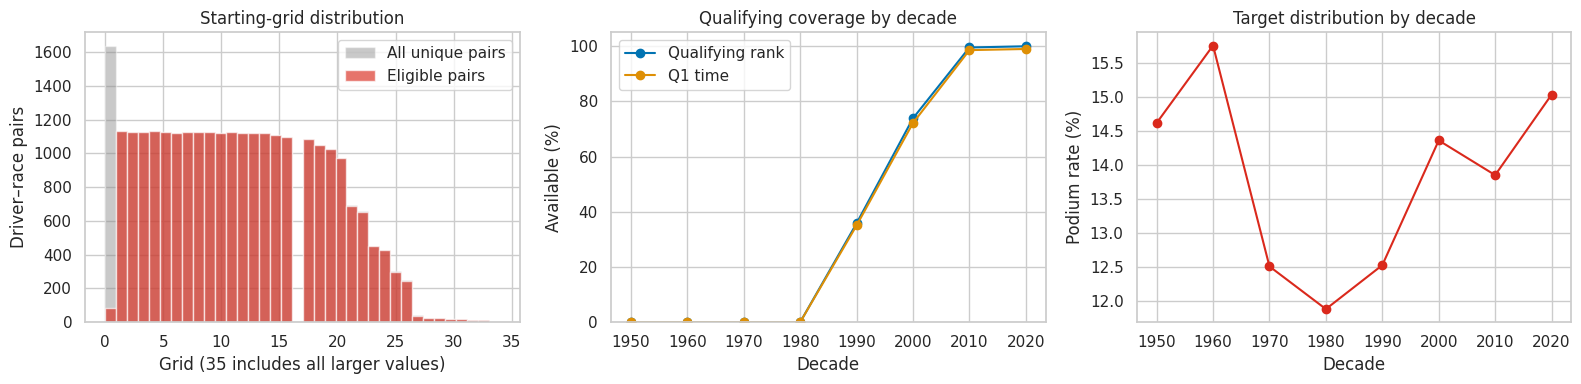

Step 2 checks passed: 14 source tables preserved, 25,100 eligible rows, unique driver–race grain, stable joins, and no outcome fields in analysis_table.


In [13]:
era_summary = (analysis_table.assign(decade=(analysis_table.year // 10) * 10)
               .groupby("decade")
               .agg(driver_races=("driverId", "size"), podium_rate=("podium", "mean"),
                    qualifying_coverage=("qualifying_position", lambda s: s.notna().mean()),
                    q1_coverage=("q1_seconds", lambda s: s.notna().mean()))
               .reset_index())
display(era_summary)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(start_rep.grid.clip(upper=35), bins=36, alpha=.45, label="All unique pairs", color="#888")
axes[0].hist(analysis_table.grid.clip(upper=35), bins=36, alpha=.65, label="Eligible pairs", color="#da291c")
axes[0].set(xlabel="Grid (35 includes all larger values)", ylabel="Driver–race pairs", title="Starting-grid distribution")
axes[0].legend()
axes[1].plot(era_summary.decade, era_summary.qualifying_coverage * 100, marker="o", label="Qualifying rank")
axes[1].plot(era_summary.decade, era_summary.q1_coverage * 100, marker="o", label="Q1 time")
axes[1].set(xlabel="Decade", ylabel="Available (%)", ylim=(0, 105), title="Qualifying coverage by decade")
axes[1].legend()
axes[2].plot(era_summary.decade, era_summary.podium_rate * 100, marker="o", color="#da291c")
axes[2].set(xlabel="Decade", ylabel="Podium rate (%)", title="Target distribution by decade")
plt.tight_layout(); plt.show()

assert len(tables) == 14
assert len(clean_tables) == len(tables)
assert analysis_table.groupby(pair).size().max() == 1
print("Step 2 checks passed: 14 source tables preserved, 25,100 eligible rows, unique driver–race grain, stable joins, and no outcome fields in analysis_table.")

### 14. Step 2 findings, rule choices, and handoff

- **Integrity:** All 14 source tables remain intact. Converted dates, numeric fields, and parseable durations produced no unexpected new nulls. The checked primary keys have no missing or duplicate values; the checked foreign-key links have zero orphan rows.
- **Shared drives:** The 26,759 result rows represent 26,668 distinct driver–race pairs. There are 85 duplicate pairs (91 excess rows), and 21 pairs have conflicting row-level podium labels. Choosing the grid-priority representative alone gives 3,378 podiums; choosing the best-finishing row gives 3,395. The chosen driver-level *any-row top-three* label gives 3,395 without letting race finish choose pre-race features. The 1957 British Grand Prix rows for Stirling Moss and Tony Brooks illustrate why this matters.
- **Population:** Excluding failed qualification (1,366 pairs) and grid-zero withdrawals (202 pairs) leaves **25,100** driver–race rows, **3,395** podium labels, and a **13.53%** podium rate. We retain 87 other grid-zero cases because zero alone does not reliably mean no start. The 2025+ races are outside this snapshot; its race dates end in 2024.
- **Join protection:** Race, driver, constructor, and qualifying joins each preserve all 25,100 rows. The final `analysis_table` has 20 columns, a unique `(raceId, driverId)` key, and no current-race finish, points, laps, race-time, or status fields.
- **For Step 3:** Qualifying rank is absent for 14,623 cohort rows and Q1 time for 14,777. Coverage is zero in the 1950s–1980s and rises later, so historical feature design needs explicit missingness handling. Review the 87 retained grid-zero cases and positive-grid withdrawals as a sensitivity check. A constructor selected from a shared-drive representative may not capture every car that driver shared; keep that limitation visible when interpreting features.

## Step 3 — Answer the three data-engineering questions

**Goal:** Answer the milestone's three required questions with multi-table joins, explicit denominators, labeled figures, numerical findings, and short interpretations. These are *historical analyses*. They may use race outcomes such as finish position and `status`, because they describe what already happened. Except for the pre-race home-race flag, nothing calculated in this step becomes a model feature.

**Rules shared by all three answers**
- We state the grain before aggregating, and check every new join for row multiplication.
- We count missing values instead of dropping them silently. Qualifying-based answers are restricted to seasons where qualifying data exists.
- Every rate is shown with its counts. Small samples also get 95% Wilson intervals, so a circuit or team with few races cannot dominate a ranking.
- These are associations in observational data, not causal effects.

### 15. Shared setup: circuit join and interval helper

**Why:** Q1 and Q2 both work at the eligible driver–race grain from Step 2 (`analysis_table`, 25,100 rows). We attach the circuit name and country once using a many-to-one check. We also define the Wilson score interval, which behaves well for proportions with small denominators.

In [14]:
import re
import warnings
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import StratifiedTable
from IPython.display import Markdown

def wilson_interval(successes, trials, z=1.96):
    """Vectorised 95% Wilson score interval for a binomial proportion."""
    successes = np.asarray(successes, dtype=float)
    trials = np.asarray(trials, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = successes / trials
        denom = 1 + z**2 / trials
        centre = (p + z**2 / (2 * trials)) / denom
        half = z * np.sqrt(p * (1 - p) / trials + z**2 / (4 * trials**2)) / denom
    return centre - half, centre + half

circuit_info = (clean_tables["circuits"][["circuitId", "circuitRef", "name", "location", "country"]]
                .rename(columns={"name": "circuit_name", "country": "circuit_country"}))
q_base = checked_join(analysis_table, circuit_info, "circuitId", "circuits (Step 3)")
q_base["podium"] = q_base["podium"].astype(bool)
assert len(q_base) == len(analysis_table) == 25_100
assert q_base[pair].duplicated().sum() == 0
print("Step 3 base grain: one eligible driver–race per row ->", q_base.shape)
print("Rows with missing circuit country:", int(q_base.circuit_country.isna().sum()))
print("Rows with missing driver nationality:", int(q_base.driver_nationality.isna().sum()))
print("Rows with missing qualifying position:", int(q_base.qualifying_position.isna().sum()))

Step 3 base grain: one eligible driver–race per row -> (25100, 24)
Rows with missing circuit country: 0
Rows with missing driver nationality: 0
Rows with missing qualifying position: 14623


### 16. Q1 — Front row to podium: choosing and checking the definition

**Question:** Which circuits most often convert a front-row start into a podium, and does the ranking change after the 2014 hybrid-era boundary?

**Two possible definitions of "front row":**
- **Actual grid 1–2** (`results.grid`): where the car really started, after penalties. Available for every season.
- **Qualifying P1–P2** (`qualifying.position`): pace in the session. Available only from 1994. It can differ from the grid because of penalties.

**Primary definition: actual grid positions 1–2**, because the question asks about converting a *start*. The qualifying definition is a robustness check for 1994–2024. We use the modern two-car front row in every season. Some 1950s grids had three or four cars on the first row, so grid 1–2 is a consistent rule rather than an exact historical reconstruction.

**Grain:** eligible driver–race rows. **Outcome:** the Step 2 driver-level podium label. Rows with missing qualifying position are excluded only from the qualifying-based definition. The table below counts how often the two definitions disagree.

In [15]:
HYBRID_START = 2014
PRE_LABEL, HYB_LABEL = "1950–2013", "2014–2024"
MIN_FRONT_ROW_STARTS = 10   # roughly five races' worth of front-row starters per circuit and era

q1 = q_base.copy()
q1["era"] = np.where(q1.year >= HYBRID_START, HYB_LABEL, PRE_LABEL)
q1["front_row_grid"] = q1.grid.between(1, 2)
q1["has_qualifying"] = q1.qualifying_position.notna()
q1["front_row_quali"] = q1.qualifying_position.between(1, 2)

quali_rows = q1[q1.has_qualifying]
definition_check = pd.crosstab(
    quali_rows.front_row_quali.map({True: "Qualified P1–P2", False: "Qualified P3+"}),
    quali_rows.front_row_grid.map({True: "Started grid 1–2", False: "Started grid 3+ or 0"}))
print("Rows with qualifying data:", len(quali_rows), f"({quali_rows.year.min()}–{quali_rows.year.max()})")
display(definition_check)
mismatch = quali_rows[quali_rows.front_row_quali != quali_rows.front_row_grid]
print(f"The definitions disagree for {len(mismatch)} driver–races "
      f"({100 * len(mismatch) / max(int(quali_rows.front_row_quali.sum()), 1):.1f}% relative to qualifying front-row rows).")
print("Most recent examples (penalties, pit-lane starts, or grid changes after qualifying):")
display(mismatch.sort_values("date")[["year", "race_name", "forename", "surname", "constructor_name",
                                      "qualifying_position", "grid", "podium"]].tail(12))

era_overall = (q1[q1.front_row_grid].groupby("era")
               .agg(races=("raceId", "nunique"), front_row_starts=("podium", "size"), podiums=("podium", "sum")))
era_overall["conversion_pct"] = 100 * era_overall.podiums / era_overall.front_row_starts
low, high = wilson_interval(era_overall.podiums, era_overall.front_row_starts)
era_overall["wilson_low_pct"], era_overall["wilson_high_pct"] = 100 * low, 100 * high
print("Overall front-row (grid 1–2) conversion by era:")
display(era_overall.round(2))

Rows with qualifying data: 10477 (1994–2024)


front_row_grid,Started grid 1–2,Started grid 3+ or 0
front_row_quali,,
Qualified P1–P2,950,37
Qualified P3+,36,9454


The definitions disagree for 73 driver–races (7.4% relative to qualifying front-row rows).
Most recent examples (penalties, pit-lane starts, or grid changes after qualifying):


,year,race_name,forename,surname,constructor_name,qualifying_position,grid,podium
24204,2023,Saudi Arabian Grand Prix,Fernando,Alonso,Aston Martin,3.0,2,True
24214,2023,Saudi Arabian Grand Prix,Charles,Leclerc,Ferrari,2.0,12,False
24324,2023,Canadian Grand Prix,Fernando,Alonso,Aston Martin,3.0,2,True
24325,2023,Canadian Grand Prix,Nico,Hülkenberg,Haas F1 Team,2.0,5,False
24406,2023,Belgian Grand Prix,Sergio,Pérez,Red Bull,3.0,2,True
24410,2023,Belgian Grand Prix,Max,Verstappen,Red Bull,1.0,6,True
24588,2023,Las Vegas Grand Prix,Max,Verstappen,Red Bull,3.0,2,True
24589,2023,Las Vegas Grand Prix,Carlos,Sainz,Ferrari,2.0,12,False
24753,2024,Emilia Romagna Grand Prix,Lando,Norris,McLaren,3.0,2,True
24758,2024,Emilia Romagna Grand Prix,Oscar,Piastri,McLaren,2.0,5,False


Overall front-row (grid 1–2) conversion by era:


,races,front_row_starts,podiums,conversion_pct,wilson_low_pct,wilson_high_pct
era,,,,,,
1950–2013,897,1805,1013,56.12,53.82,58.40
2014–2024,228,454,345,75.99,71.85,79.69


### 17. Q1 — Circuit conversion rankings before and after 2014

**Method:** For each circuit and era, we count front-row starts (grid 1–2), podiums among those starts, and distinct races. Circuits are ranked by the **95% Wilson lower bound**, not the raw rate, so a circuit that converted 2 of 2 starts cannot outrank one that converted 40 of 44. Circuit–era cells with fewer than 10 front-row starts are listed as small samples rather than ranked.

To ask whether the ranking *changed*, we compare only circuits with enough starts in **both** eras and report the Spearman rank correlation of their conversion rates. A high ρ means a stable ranking; a low or negative ρ means it reshuffled.

Circuits ranked per era (>= 10 front-row starts): {'1950–2013': 45, '2014–2024': 19}
Small-sample circuit–era cells not ranked: 37 (173 front-row starts)

Highest-converting circuits, 1950–2013 (ranked by Wilson lower bound)


,rank_in_era,circuit_name,circuit_country,races,front_row_starts,podiums,conversion_pct,wilson_low_pct,wilson_high_pct,first_year,last_year
7,1,Circuit de Nevers Magny-Cours,France,18,36,29,80.6,65.0,90.2,1991,2008
21,2,Suzuka Circuit,Japan,25,50,35,70.0,56.2,80.9,1987,2013
10,3,Hungaroring,Hungary,28,56,38,67.9,54.8,78.6,1986,2013
4,4,Istanbul Park,Turkey,7,14,11,78.6,52.4,92.4,2005,2011
56,5,Aintree,UK,5,11,9,81.8,52.3,94.9,1955,1962
1,6,Sepang International Circuit,Malaysia,15,30,21,70.0,52.1,83.3,1999,2013
3,7,Circuit de Barcelona-Catalunya,Spain,23,46,30,65.2,50.8,77.3,1991,2013
9,8,Hockenheimring,Germany,33,66,40,60.6,48.5,71.5,1970,2012
17,9,Autódromo José Carlos Pace,Brazil,31,62,37,59.7,47.3,71.0,1973,2013
39,10,Dijon-Prenois,France,6,12,9,75.0,46.8,91.1,1974,1984


Lowest-converting circuits, 1950–2013


,rank_in_era,circuit_name,circuit_country,races,front_row_starts,podiums,conversion_pct,wilson_low_pct,wilson_high_pct,first_year,last_year
36,41,Brands Hatch,UK,14,28,11,39.3,23.6,57.6,1964,1986
46,42,Mosport International Raceway,Canada,8,16,7,43.8,23.1,66.8,1967,1977
45,43,Scandinavian Raceway,Sweden,6,12,5,41.7,19.3,68.0,1973,1978
34,44,Autódromo Internacional Nelson Piquet,Brazil,10,20,7,35.0,18.1,56.7,1978,1989
35,45,Detroit Street Circuit,USA,7,14,4,28.6,11.7,54.6,1982,1988



Highest-converting circuits, 2014–2024 (ranked by Wilson lower bound)


...

,rank_in_era,circuit_name,circuit_country,races,front_row_starts,podiums,conversion_pct,wilson_low_pct,wilson_high_pct,first_year,last_year
81,14,Marina Bay Street Circuit,Singapore,9,18,13,72.2,49.1,87.5,2014,2024
71,16,Bahrain International Circuit,Bahrain,12,24,16,66.7,46.7,82.0,2014,2024
78,17,Hungaroring,Hungary,11,22,13,59.1,38.7,76.7,2014,2024
94,18,Baku City Circuit,Azerbaijan,8,16,10,62.5,38.6,81.5,2016,2024
88,19,Autódromo Hermanos Rodríguez,Mexico,9,18,11,61.1,38.6,79.7,2015,2024


Small-sample hybrid-era circuits (shown for transparency, not ranked):


,circuit_name,races,front_row_starts,podiums,conversion_pct
84,Nürburgring,1,2,1,50.0
96,Autodromo Internazionale del Mugello,1,2,2,100.0
95,Autódromo Internacional do Algarve,2,4,4,100.0
73,Istanbul Park,2,4,2,50.0
100,Las Vegas Strip Street Circuit,2,4,4,100.0
99,Miami International Autodrome,3,6,6,100.0
98,Losail International Circuit,3,6,3,50.0
70,Sepang International Circuit,4,7,6,85.7
90,Circuit Park Zandvoort,4,8,7,87.5
89,Circuit Paul Ricard,4,8,6,75.0



Circuits with >= 10 front-row starts in BOTH eras: 16
Spearman rank correlation of conversion rates across eras: rho = -0.03 (p = 0.909)


,circuitId,circuit_name,pre_rate,hybrid_rate,pre_n,hybrid_n,pre_rank,hybrid_rank,rank_change
12,22,Suzuka Circuit,70.0,88.9,50,18,1,1,0
13,24,Yas Marina Circuit,60.0,86.4,10,22,6,2,4
3,6,Circuit de Monaco,49.6,85.0,121,20,15,3,12
2,4,Circuit de Barcelona-Catalunya,65.2,81.8,46,22,4,4,0
7,13,Circuit de Spa-Francorchamps,54.3,81.8,92,22,12,4,8
11,18,Autódromo José Carlos Pace,59.7,78.9,62,19,8,6,2
10,17,Shanghai International Circuit,65.0,78.6,20,14,5,7,-2
4,7,Circuit Gilles Villeneuve,52.9,77.8,68,18,13,8,5
5,9,Silverstone Circuit,56.4,75.0,94,24,10,9,1
15,70,Red Bull Ring,52.0,73.1,50,26,14,10,4


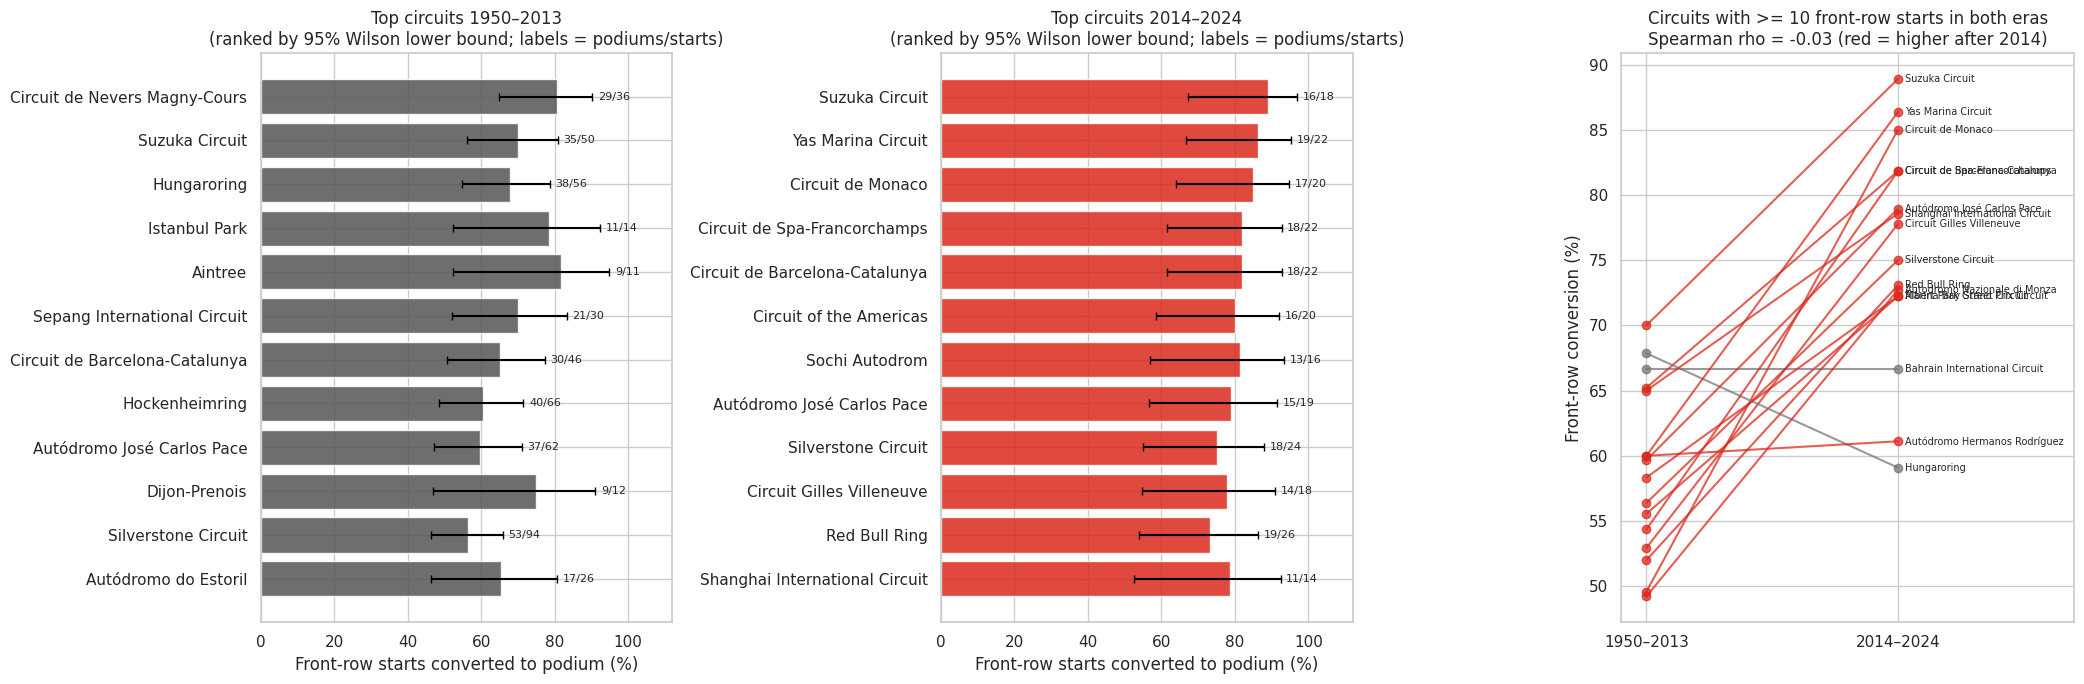

In [16]:
def front_row_conversion(frame, flag_column):
    starts = frame[frame[flag_column]]
    out = (starts.groupby(["era", "circuitId", "circuit_name", "circuit_country"])
           .agg(races=("raceId", "nunique"), front_row_starts=("podium", "size"), podiums=("podium", "sum"),
                first_year=("year", "min"), last_year=("year", "max"))
           .reset_index())
    out["conversion_pct"] = 100 * out.podiums / out.front_row_starts
    low, high = wilson_interval(out.podiums, out.front_row_starts)
    out["wilson_low_pct"], out["wilson_high_pct"] = 100 * low, 100 * high
    return out

grid_conv = front_row_conversion(q1, "front_row_grid")
ranked = grid_conv[grid_conv.front_row_starts >= MIN_FRONT_ROW_STARTS].copy()
ranked["rank_in_era"] = ranked.groupby("era").wilson_low_pct.rank(ascending=False, method="min").astype(int)
small = grid_conv[grid_conv.front_row_starts < MIN_FRONT_ROW_STARTS]
print(f"Circuits ranked per era (>= {MIN_FRONT_ROW_STARTS} front-row starts):", ranked.groupby("era").size().to_dict())
print(f"Small-sample circuit–era cells not ranked: {len(small)} "
      f"({int(small.front_row_starts.sum())} front-row starts)")
show_cols = ["rank_in_era", "circuit_name", "circuit_country", "races", "front_row_starts", "podiums",
             "conversion_pct", "wilson_low_pct", "wilson_high_pct", "first_year", "last_year"]
for era in [PRE_LABEL, HYB_LABEL]:
    era_rank = ranked[ranked.era == era].sort_values(["rank_in_era", "front_row_starts"], ascending=[True, False])
    print(f"\nHighest-converting circuits, {era} (ranked by Wilson lower bound)")
    display(era_rank[show_cols].head(10).round(1))
    print(f"Lowest-converting circuits, {era}")
    display(era_rank[show_cols].tail(5).round(1))
print("Small-sample hybrid-era circuits (shown for transparency, not ranked):")
display(small[small.era == HYB_LABEL].sort_values("front_row_starts")[
    ["circuit_name", "races", "front_row_starts", "podiums", "conversion_pct"]].round(1))

wide = ranked.pivot_table(index=["circuitId", "circuit_name"], columns="era",
                          values=["conversion_pct", "front_row_starts"])
shared = wide.dropna()
shared_rates = pd.DataFrame({
    "pre_rate": shared[("conversion_pct", PRE_LABEL)], "hybrid_rate": shared[("conversion_pct", HYB_LABEL)],
    "pre_n": shared[("front_row_starts", PRE_LABEL)].astype(int),
    "hybrid_n": shared[("front_row_starts", HYB_LABEL)].astype(int)}).reset_index()
shared_rates["pre_rank"] = shared_rates.pre_rate.rank(ascending=False, method="min").astype(int)
shared_rates["hybrid_rank"] = shared_rates.hybrid_rate.rank(ascending=False, method="min").astype(int)
shared_rates["rank_change"] = shared_rates.pre_rank - shared_rates.hybrid_rank
rho, rho_p = stats.spearmanr(shared_rates.pre_rate, shared_rates.hybrid_rate) if len(shared_rates) > 2 else (np.nan, np.nan)
print(f"\nCircuits with >= {MIN_FRONT_ROW_STARTS} front-row starts in BOTH eras: {len(shared_rates)}")
print(f"Spearman rank correlation of conversion rates across eras: rho = {rho:.2f} (p = {rho_p:.3f})")
display(shared_rates.sort_values("hybrid_rank").round(1))

fig, axes = plt.subplots(1, 3, figsize=(21, 7), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for ax, era, colour in zip(axes[:2], [PRE_LABEL, HYB_LABEL], ["#555555", "#da291c"]):
    top = ranked[ranked.era == era].nlargest(12, "wilson_low_pct").sort_values("wilson_low_pct")
    y = np.arange(len(top))
    ax.barh(y, top.conversion_pct, color=colour, alpha=.85)
    ax.errorbar(top.conversion_pct, y, fmt="none", ecolor="black", capsize=3,
                xerr=[top.conversion_pct - top.wilson_low_pct, top.wilson_high_pct - top.conversion_pct])
    for yi, (hi, k, n) in enumerate(zip(top.wilson_high_pct, top.podiums, top.front_row_starts)):
        ax.text(min(hi + 1.5, 101), yi, f"{k}/{n}", va="center", fontsize=8)
    ax.set_yticks(y, top.circuit_name)
    ax.set(xlim=(0, 112), xlabel="Front-row starts converted to podium (%)",
           title=f"Top circuits {era}\n(ranked by 95% Wilson lower bound; labels = podiums/starts)")
ax = axes[2]
for _, r in shared_rates.iterrows():
    ax.plot([0, 1], [r.pre_rate, r.hybrid_rate], marker="o", alpha=.75,
            color="#da291c" if r.hybrid_rate > r.pre_rate else "#777777")
    ax.text(1.03, r.hybrid_rate, r.circuit_name, fontsize=7, va="center")
ax.set(xticks=[0, 1], xticklabels=[PRE_LABEL, HYB_LABEL], xlim=(-0.1, 1.7), ylabel="Front-row conversion (%)",
       title=f"Circuits with >= {MIN_FRONT_ROW_STARTS} front-row starts in both eras\nSpearman rho = {rho:.2f} (red = higher after 2014)")
plt.tight_layout(); plt.show()

**Robustness check: qualifying P1–P2 instead of grid 1–2 (1994–2024 only).** Here both definitions use the same seasons, 1994–2013 compared with 2014–2024, so any difference comes from the definition rather than from history.

In [17]:
q1_modern = q1[q1.has_qualifying].copy()
q1_modern["era"] = np.where(q1_modern.year >= HYBRID_START, HYB_LABEL, "1994–2013")
definition_rows = []
for label, flag in [("Grid 1–2", "front_row_grid"), ("Qualifying P1–P2", "front_row_quali")]:
    for era, g in q1_modern[q1_modern[flag]].groupby("era"):
        definition_rows.append({"definition": label, "era": era, "front_row_starts": len(g),
                                "podiums": int(g.podium.sum()), "conversion_pct": 100 * g.podium.mean()})
display(pd.DataFrame(definition_rows).round(2))

quali_conv = front_row_conversion(q1_modern, "front_row_quali")
grid_conv_modern = front_row_conversion(q1_modern, "front_row_grid")
robust = quali_conv.merge(grid_conv_modern, on=["era", "circuitId", "circuit_name", "circuit_country"],
                          how="outer", suffixes=("_quali", "_grid"), validate="one_to_one")
robust = robust[robust.era.eq(HYB_LABEL) & robust.front_row_starts_grid.ge(MIN_FRONT_ROW_STARTS)]
robust["rank_grid"] = robust.wilson_low_pct_grid.rank(ascending=False, method="min")
robust["rank_quali"] = robust.wilson_low_pct_quali.rank(ascending=False, method="min")
rank_agreement = stats.spearmanr(robust.conversion_pct_grid, robust.conversion_pct_quali, nan_policy="omit")[0]
print(f"Hybrid era: Spearman correlation between grid-based and qualifying-based circuit rates = {rank_agreement:.2f}")
display(robust.sort_values("rank_grid")[["circuit_name", "front_row_starts_grid", "conversion_pct_grid", "rank_grid",
                                         "front_row_starts_quali", "conversion_pct_quali", "rank_quali"]].head(12).round(1))

,definition,era,front_row_starts,podiums,conversion_pct
0,Grid 1–2,1994–2013,532,347,65.23
1,Grid 1–2,2014–2024,454,345,75.99
2,Qualifying P1–P2,1994–2013,532,344,64.66
3,Qualifying P1–P2,2014–2024,455,336,73.85


Hybrid era: Spearman correlation between grid-based and qualifying-based circuit rates = 0.90


,circuit_name,front_row_starts_grid,conversion_pct_grid,rank_grid,front_row_starts_quali,conversion_pct_quali,rank_quali
49,Suzuka Circuit,18,88.9,1.0,18,88.9,1.0
50,Yas Marina Circuit,22,86.4,2.0,22,81.8,3.0
37,Circuit de Monaco,20,85.0,3.0,20,85.0,2.0
35,Circuit de Barcelona-Catalunya,22,81.8,4.0,22,81.8,3.0
42,Circuit de Spa-Francorchamps,22,81.8,4.0,22,81.8,3.0
54,Circuit of the Americas,20,80.0,6.0,20,75.0,8.0
56,Sochi Autodrom,16,81.2,7.0,16,81.2,6.0
46,Autódromo José Carlos Pace,19,78.9,8.0,19,68.4,16.0
39,Silverstone Circuit,24,75.0,9.0,24,75.0,7.0
38,Circuit Gilles Villeneuve,18,77.8,10.0,18,72.2,12.0


In [18]:
def top_circuits_text(era, k=3):
    t = ranked[ranked.era == era].sort_values(["rank_in_era", "front_row_starts"], ascending=[True, False]).head(k)
    return "; ".join(f"**{r.circuit_name}** {r.conversion_pct:.0f}% ({r.podiums}/{r.front_row_starts})" for r in t.itertuples())

q1_findings = {
    "pre_rate": era_overall.loc[PRE_LABEL, "conversion_pct"], "hyb_rate": era_overall.loc[HYB_LABEL, "conversion_pct"],
    "pre_n": int(era_overall.loc[PRE_LABEL, "front_row_starts"]), "hyb_n": int(era_overall.loc[HYB_LABEL, "front_row_starts"]),
    "rho": rho, "n_shared": len(shared_rates)}
rank_verdict = ("the ranking changes substantially after 2014" if rho < 0.5 else
                "the ranking changes partly after 2014" if rho < 0.8 else "the ranking is largely stable across 2014")
display(Markdown(f"""**Q1 finding (auto-generated from the outputs above)**

- Definition: actual starting grid 1–2. The qualifying P1–P2 definition disagrees for {len(mismatch)} driver–races in 1994–2024. The two definitions rank hybrid-era circuits similarly (Spearman = {rank_agreement:.2f}).
- Overall, front-row starters reached the podium **{q1_findings['pre_rate']:.1f}%** of the time in {PRE_LABEL} (n = {q1_findings['pre_n']}) and **{q1_findings['hyb_rate']:.1f}%** in {HYB_LABEL} (n = {q1_findings['hyb_n']}).
- Highest conversion (by Wilson lower bound) in {PRE_LABEL}: {top_circuits_text(PRE_LABEL)}.
- Highest conversion in {HYB_LABEL}: {top_circuits_text(HYB_LABEL)}.
- Among the {q1_findings['n_shared']} circuits with enough starts in both eras, the rank correlation is ρ = {q1_findings['rho']:.2f}, so **{rank_verdict}**. The per-circuit Wilson intervals are wide, so individual rank moves should not be over-interpreted.
- Interpretation: a front-row start is a strong advantage everywhere. The circuit-level differences combine track characteristics with which teams dominated the era (for example, one dominant team during the hybrid years). This is an association, not a track effect isolated from car performance."""))

**Q1 finding (auto-generated from the outputs above)**

- Definition: actual starting grid 1–2. The qualifying P1–P2 definition disagrees for 73 driver–races in 1994–2024. The two definitions rank hybrid-era circuits similarly (Spearman = 0.90).
- Overall, front-row starters reached the podium **56.1%** of the time in 1950–2013 (n = 1805) and **76.0%** in 2014–2024 (n = 454).
- Highest conversion (by Wilson lower bound) in 1950–2013: **Circuit de Nevers Magny-Cours** 81% (29/36); **Suzuka Circuit** 70% (35/50); **Hungaroring** 68% (38/56).
- Highest conversion in 2014–2024: **Suzuka Circuit** 89% (16/18); **Yas Marina Circuit** 86% (19/22); **Circuit de Monaco** 85% (17/20).
- Among the 16 circuits with enough starts in both eras, the rank correlation is ρ = -0.03, so **the ranking changes substantially after 2014**. The per-circuit Wilson intervals are wide, so individual rank moves should not be over-interpreted.
- Interpretation: a front-row start is a strong advantage everywhere. The circuit-level differences combine track characteristics with which teams dominated the era (for example, one dominant team during the hybrid years). This is an association, not a track effect isolated from car performance.

#### Answer to Q1 — front row to podium by circuit

**Definition used:** a front-row start is an *actual starting grid* position of 1 or 2 (`results.grid`), because the question is about converting a start. Qualifying P1–P2 (`qualifying.position`) is kept separate. The two disagree for 73 driver–races in 1994–2024, mostly because of grid penalties (for example, Verstappen qualified P1 but started 11th at the 2024 Belgian GP). With qualifying P1–P2 instead, the hybrid-era circuit ranking is almost the same (Spearman 0.90).

**Grain and missingness:** eligible driver–race rows (25,100); no circuit or grid values are missing. The qualifying-based check uses only 1994–2024, the years where qualifying data exists. Circuits need at least 10 front-row starts per era and are ranked by the 95% Wilson lower bound, so a circuit with 2/2 cannot top the list.

**Answer:**
- Overall conversion rose from **56.1%** (1,013 of 1,805 front-row starts, 1950–2013) to **76.0%** (345 of 454, 2014–2024).
- **1950–2013** leaders: Magny-Cours 81% (29/36), Suzuka 70% (35/50), Hungaroring 68% (38/56).
- **2014–2024** leaders: Suzuka 89% (16/18), Yas Marina 86% (19/22), Monaco 85% (17/20).
- **The ranking changes after 2014.** Among the 16 circuits with enough starts in both eras, the rank correlation is ρ = −0.03 (p = 0.91). Monaco rose from 15th to 3rd, while the Hungaroring fell from 2nd to last (67.9% → 59.1%).

**Interpretation:** the per-circuit intervals are wide (often ±15 percentage points), so single rank moves are uncertain. The era-wide rise is clear and fits dominant, reliable hybrid-era cars converting front-row starts. These are associations; they do not separate a track's effect from the cars that happened to start at the front.

### 18. Q2 — Home-country podium effect: a reviewed nationality-to-country mapping

**Question:** Do drivers reach the podium more often at home, after controlling for similar starting-grid positions?

**Join path:** `analysis_table` (driver nationality, e.g. "British") → `races` → `circuits.country` (e.g. "UK"). Nationalities are demonyms, while circuit countries are place names, so a direct string join would fail. We use an **explicit mapping** written by hand and reviewed against every value that occurs in the data.
- "Home" means the **physical country of the circuit**. Example: the 1982 Swiss GP was held at Dijon, France, so it is *not* a home race for Swiss drivers.
- Dual nationalities (`American-Italian`, `Argentine-Italian`) are home in either country. East German drivers are mapped to Germany.
- Nationalities with no championship race in their country, such as Finnish or Danish, map to an empty set: those drivers are always "away".
- Country spellings are normalised first (`United States` → `USA`, and so on).

**Output:** Two review tables — every nationality with its mapped countries and number of home driver–races, and every circuit country with whether any nationality maps to it — plus warnings for unreviewed values.

In [19]:
COUNTRY_ALIASES = {"United States": "USA", "US": "USA", "United Kingdom": "UK", "Great Britain": "UK",
                   "South Korea": "Korea", "United Arab Emirates": "UAE"}
NATIONALITY_TO_COUNTRIES = {
    "American": {"USA"}, "American-Italian": {"USA", "Italy"}, "Argentine": {"Argentina"},
    "Argentinian": {"Argentina"}, "Argentine-Italian": {"Argentina", "Italy"}, "Australian": {"Australia"},
    "Austrian": {"Austria"}, "Belgian": {"Belgium"}, "Brazilian": {"Brazil"}, "British": {"UK"},
    "Canadian": {"Canada"}, "Chinese": {"China"}, "Dutch": {"Netherlands"}, "French": {"France"},
    "German": {"Germany"}, "East German": {"Germany"}, "West German": {"Germany"}, "Hungarian": {"Hungary"},
    "Indian": {"India"}, "Italian": {"Italy"}, "Japanese": {"Japan"}, "Malaysian": {"Malaysia"},
    "Mexican": {"Mexico"}, "Monegasque": {"Monaco"}, "Portuguese": {"Portugal"}, "Russian": {"Russia"},
    "South African": {"South Africa"}, "Spanish": {"Spain"}, "Swedish": {"Sweden"}, "Swiss": {"Switzerland"},
    # Reviewed: no championship race was held in these countries in 1950–2024
    "Chilean": set(), "Colombian": set(), "Czech": set(), "Danish": set(), "Finnish": set(),
    "Hong Kong": set(), "Indonesian": set(), "Irish": set(), "Liechtensteiner": set(),
    "New Zealander": set(), "Polish": set(), "Rhodesian": set(), "Thai": set(), "Uruguayan": set(),
    "Venezuelan": set(),
}

def home_race_flag(nationalities, circuit_countries):
    countries = pd.Series(circuit_countries).astype(str).str.strip().replace(COUNTRY_ALIASES)
    return np.array([c in NATIONALITY_TO_COUNTRIES.get(str(n).strip(), set()) for n, c in zip(nationalities, countries)])

q2 = q_base.copy()
q2["circuit_country_norm"] = q2.circuit_country.replace(COUNTRY_ALIASES)
raw_nationalities = set(q2.driver_nationality.dropna())
q2["driver_nationality"] = q2.driver_nationality.str.strip()
print("Nationality strings with stray whitespace (normalised by stripping):",
      sorted(repr(n) for n in raw_nationalities if n != n.strip()) or "none")
q2["is_home_race"] = home_race_flag(q2.driver_nationality, q2.circuit_country)

nat_review = (q2.groupby("driver_nationality", dropna=False)
              .agg(driver_races=("driverId", "size"), drivers=("driverId", "nunique"),
                   home_driver_races=("is_home_race", "sum"))
              .reset_index())
nat_review["in_reviewed_mapping"] = nat_review.driver_nationality.isin(NATIONALITY_TO_COUNTRIES.keys())
nat_review["home_countries"] = nat_review.driver_nationality.map(
    lambda n: ", ".join(sorted(NATIONALITY_TO_COUNTRIES.get(n, set()))) or "none (no home race possible)")
mapped_countries = set().union(*NATIONALITY_TO_COUNTRIES.values())
country_review = (q2.groupby("circuit_country_norm")
                  .agg(races=("raceId", "nunique"), circuits=("circuitId", "nunique")).reset_index())
country_review["matched_by_a_nationality"] = country_review.circuit_country_norm.isin(mapped_countries)
print("Nationality review:")
display(nat_review.sort_values("driver_races", ascending=False))
print("Circuit-country review:")
display(country_review.sort_values("races", ascending=False))

unreviewed = nat_review.loc[~nat_review.in_reviewed_mapping, "driver_nationality"].tolist()
not_seen = sorted(mapped_countries - set(country_review.circuit_country_norm))
if unreviewed:
    warnings.warn(f"Nationalities missing from the reviewed mapping (treated as away): {unreviewed}")
print("Nationalities not in the reviewed mapping:", unreviewed or "none")
print("Circuit countries with no driver nationality mapped to them:",
      country_review.loc[~country_review.matched_by_a_nationality, "circuit_country_norm"].tolist())
print("Mapped countries that never appear as a circuit country (spelling check):", not_seen or "none")
print(f"Home driver–races: {int(q2.is_home_race.sum())} of {len(q2)} ({100 * q2.is_home_race.mean():.1f}%)")

Nationality strings with stray whitespace (normalised by stripping): ["'Argentinian '"]
Nationality review:


,driver_nationality,driver_races,drivers,home_driver_races,in_reviewed_mapping,home_countries
9,British,4302,153,451,True,UK
25,Italian,3019,83,403,True,Italy
19,French,2930,72,207,True,France
20,German,2326,45,199,True,Germany
8,Brazilian,1859,32,114,True,Brazil
0,American,1218,152,492,True,USA
18,Finnish,1160,8,0,True,none (no home race possible)
37,Spanish,884,14,61,True,Spain
5,Australian,870,16,28,True,Australia
6,Austrian,667,14,29,True,Austria


Circuit-country review:


,circuit_country_norm,races,circuits,matched_by_a_nationality
13,Italy,107,4,True
10,Germany,79,3,True
32,UK,79,4,True
33,USA,79,12,True
18,Monaco,70,1,True
5,Belgium,69,3,True
9,France,63,7,True
27,Spain,61,6,True
7,Canada,53,3,True
6,Brazil,51,2,True


Nationalities not in the reviewed mapping: none
Circuit countries with no driver nationality mapped to them: ['Azerbaijan', 'Bahrain', 'Korea', 'Morocco', 'Qatar', 'Saudi Arabia', 'Singapore', 'Turkey', 'UAE']
Mapped countries that never appear as a circuit country (spelling check): none
Home driver–races: 2325 of 25100 (9.3%)


### 19. Q2 — Home vs away podium rates within starting-grid strata

**Why control for grid:** Raw home rates are confounded. A strong home driver also starts near the front, and starting position is the strongest single predictor of a podium. We therefore compare home and away **within the same grid band** (P1, P2, P3, P4–6, P7–10, P11+, and grid 0), then pool across bands with:
1. a **grid-standardised difference**: the within-band home−away difference, weighted by the number of home starts;
2. the **Mantel–Haenszel pooled odds ratio** with a 95% CI and CMH test;
3. a **logistic regression**, `podium ~ home + grid band + decade`, which also adjusts for era.

The main analysis **excludes the 1950–1960 Indianapolis 500** (see Section 20). Other scenarios are reported as sensitivity checks. An odds ratio above 1 means home drivers podium more often than away drivers from comparable grid slots. This describes an association; it is not evidence that racing at home *causes* podiums.

Within-grid-band comparison, main scenario:


,grid_bucket,home_n,home_podiums,away_n,away_podiums,home_rate_pct,away_rate_pct,difference_pp
0,Grid 0,4,0,83,0,0.00,0.00,0.00
1,P1,84,52,1040,673,61.90,64.71,-2.81
2,P2,77,44,1034,581,57.14,56.19,0.95
3,P3,70,37,1044,479,52.86,45.88,6.98
4,P4-6,227,61,3114,812,26.87,26.08,0.80
5,P7-10,337,24,4116,380,7.12,9.23,-2.11
6,P11+,1146,12,12343,204,1.05,1.65,-0.61


Pooled home effect across scenarios:


,scenario,driver_races,home_driver_races,raw_home_rate_pct,raw_away_rate_pct,grid_standardised_diff_pp,MH_odds_ratio,MH_CI_low,MH_CI_high,CMH_p_value,logit_OR_grid_decade,logit_CI_low,logit_CI_high,logit_p
0,Main: 1950–2024 excluding Indy 500,24719,1945,11.825,13.739,-0.462,0.939,0.791,1.116,0.482,0.931,0.784,1.105,0.414
1,All seasons including Indy 500,25100,2325,11.441,13.739,-0.498,0.934,0.797,1.094,0.398,0.916,0.778,1.078,0.291
2,1994–2024 (qualifying era),12287,593,12.648,14.161,-2.716,0.687,0.501,0.942,0.021,0.693,0.507,0.947,0.021
3,2014–2024 (hybrid era),4620,145,16.552,14.749,-1.852,0.784,0.424,1.451,0.427,0.773,0.411,1.453,0.424


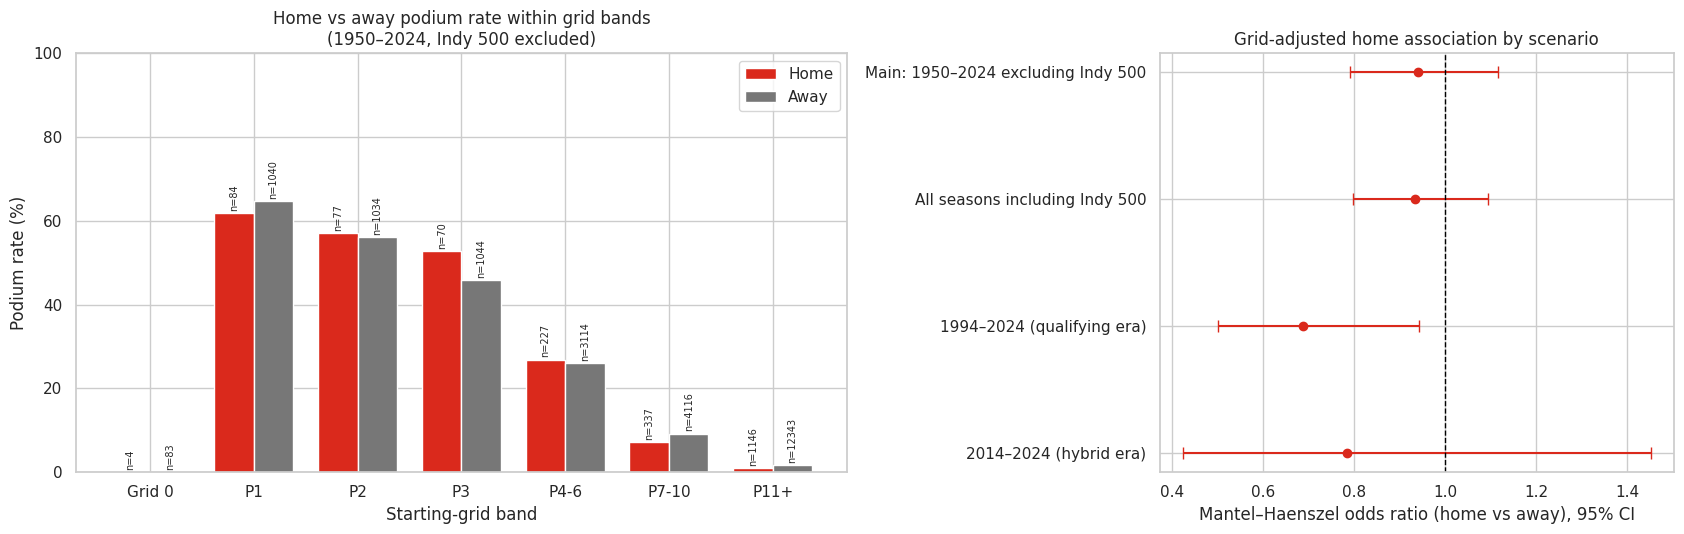

In [20]:
GRID_BINS = [-0.5, 0.5, 1.5, 2.5, 3.5, 6.5, 10.5, np.inf]
GRID_LABELS = ["Grid 0", "P1", "P2", "P3", "P4-6", "P7-10", "P11+"]
q2["grid_bucket"] = pd.cut(q2.grid, bins=GRID_BINS, labels=GRID_LABELS)
q2["is_indy500"] = q2.race_name.str.contains("Indianapolis 500", case=False, na=False) & q2.year.between(1950, 1960)
q2["decade"] = (q2.year // 10) * 10
q2["podium_int"] = q2.podium.astype(int)
q2["home_int"] = q2.is_home_race.astype(int)

def home_away_by_grid(frame):
    rows = []
    for bucket, g in frame.groupby("grid_bucket", observed=True):
        home, away = g[g.is_home_race], g[~g.is_home_race]
        rows.append({"grid_bucket": bucket, "home_n": len(home), "home_podiums": int(home.podium.sum()),
                     "away_n": len(away), "away_podiums": int(away.podium.sum())})
    t = pd.DataFrame(rows)
    t["home_rate_pct"] = 100 * t.home_podiums / t.home_n.replace(0, np.nan)
    t["away_rate_pct"] = 100 * t.away_podiums / t.away_n.replace(0, np.nan)
    t["difference_pp"] = t.home_rate_pct - t.away_rate_pct
    return t

def home_effect_summary(frame, label):
    strata = home_away_by_grid(frame)
    usable = strata[(strata.home_n > 0) & (strata.away_n > 0)]
    tables_2x2 = [np.array([[r.home_podiums, r.home_n - r.home_podiums],
                            [r.away_podiums, r.away_n - r.away_podiums]], dtype=float) for r in usable.itertuples()]
    st = StratifiedTable(tables_2x2)
    ci_low, ci_high = st.oddsratio_pooled_confint()
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fit = smf.logit("podium_int ~ home_int + C(grid_bucket) + C(decade)",
                            data=frame.assign(grid_bucket=frame.grid_bucket.astype(str))).fit(disp=False)
        logit_or = np.exp(fit.params["home_int"])
        logit_ci = np.exp(fit.conf_int().loc["home_int"]).tolist()
        logit_p = fit.pvalues["home_int"]
    except Exception as exc:
        print(f"[{label}] logistic regression skipped: {exc}")
        logit_or, logit_ci, logit_p = np.nan, [np.nan, np.nan], np.nan
    summary = {
        "scenario": label, "driver_races": len(frame), "home_driver_races": int(frame.is_home_race.sum()),
        "raw_home_rate_pct": 100 * frame.loc[frame.is_home_race, "podium"].mean(),
        "raw_away_rate_pct": 100 * frame.loc[~frame.is_home_race, "podium"].mean(),
        "grid_standardised_diff_pp": np.average(usable.difference_pp, weights=usable.home_n),
        "MH_odds_ratio": st.oddsratio_pooled, "MH_CI_low": ci_low, "MH_CI_high": ci_high,
        "CMH_p_value": st.test_null_odds().pvalue,
        "logit_OR_grid_decade": logit_or, "logit_CI_low": logit_ci[0], "logit_CI_high": logit_ci[1], "logit_p": logit_p}
    return summary, strata

scenarios = {
    "Main: 1950–2024 excluding Indy 500": q2[~q2.is_indy500],
    "All seasons including Indy 500": q2,
    "1994–2024 (qualifying era)": q2[q2.year >= 1994],
    "2014–2024 (hybrid era)": q2[q2.year >= 2014],
}
home_results, home_strata = [], {}
for label, frame in scenarios.items():
    summary, strata = home_effect_summary(frame, label)
    home_results.append(summary)
    home_strata[label] = strata
home_results = pd.DataFrame(home_results)
MAIN_HOME = "Main: 1950–2024 excluding Indy 500"
print("Within-grid-band comparison, main scenario:")
display(home_strata[MAIN_HOME].round(2))
print("Pooled home effect across scenarios:")
display(home_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
strata = home_strata[MAIN_HOME]
x = np.arange(len(strata)); w = 0.38
axes[0].bar(x - w / 2, strata.home_rate_pct, w, label="Home", color="#da291c")
axes[0].bar(x + w / 2, strata.away_rate_pct, w, label="Away", color="#777777")
for xi, r in zip(x, strata.itertuples()):
    axes[0].text(xi - w / 2, (r.home_rate_pct if pd.notna(r.home_rate_pct) else 0) + 1, f"n={r.home_n}", ha="center", fontsize=7, rotation=90)
    axes[0].text(xi + w / 2, (r.away_rate_pct if pd.notna(r.away_rate_pct) else 0) + 1, f"n={r.away_n}", ha="center", fontsize=7, rotation=90)
axes[0].set_xticks(x, strata.grid_bucket.astype(str))
axes[0].set(xlabel="Starting-grid band", ylabel="Podium rate (%)", ylim=(0, 100),
            title="Home vs away podium rate within grid bands\n(1950–2024, Indy 500 excluded)")
axes[0].legend()
y = np.arange(len(home_results))
axes[1].errorbar(home_results.MH_odds_ratio, y, fmt="o", color="#da291c", capsize=4,
                 xerr=[home_results.MH_odds_ratio - home_results.MH_CI_low, home_results.MH_CI_high - home_results.MH_odds_ratio])
axes[1].axvline(1, color="black", linestyle="--", linewidth=1)
axes[1].set_yticks(y, home_results.scenario); axes[1].invert_yaxis()
axes[1].set(xlabel="Mantel–Haenszel odds ratio (home vs away), 95% CI", title="Grid-adjusted home association by scenario")
plt.tight_layout(); plt.show()

### 20. Q2 — Investigating the 1950–1960 Indianapolis 500 separately

**Why:** The Indianapolis 500 counted toward the World Championship from 1950 to 1960. It was run under different regulations, almost entirely by American oval specialists who rarely entered any other championship race. Nearly every Indy entry is therefore a "home" driver–race, and every Indy podium is a home podium. Including those races would inflate the home rate through a race that is effectively a separate competition, not through any home advantage at a Formula 1 Grand Prix.

**Output:** How many rows and home podiums the Indy 500 contributes, how separate its driver pool is, and how the 1950–1960 home comparison changes with and without it.

Indianapolis 500 races identified (1950–1960): 11 | driver–race rows: 381


,year,race_name,entrants,home_entrants,podiums
0,1950,Indianapolis 500,34,34,3
1,1951,Indianapolis 500,34,34,4
2,1952,Indianapolis 500,33,32,3
3,1953,Indianapolis 500,37,37,4
4,1954,Indianapolis 500,42,42,3
5,1955,Indianapolis 500,35,35,4
6,1956,Indianapolis 500,34,34,3
7,1957,Indianapolis 500,33,33,3
8,1958,Indianapolis 500,33,33,3
9,1959,Indianapolis 500,33,33,3


Indy drivers who also started another 1950–1960 championship race: 3 of 107
Indy 500 contributes 36 of 266 home podiums across 1950–2024 (13.5%), from 1.5% of all driver–races.


,subset,driver_races,home_share_pct,home_podium_rate_pct,away_podium_rate_pct
0,1950–60 Indy 500,381,99.74,9.47,0.00
1,1950–60 other races,1681,22.78,10.97,17.26
2,1950–60 all races,2062,37.00,10.22,17.24


,scenario,home_driver_races,raw_home_rate_pct,raw_away_rate_pct,grid_standardised_diff_pp,MH_odds_ratio,MH_CI_low,MH_CI_high
0,1950–60 incl. Indy,763,10.223,17.244,-0.938,0.855,0.625,1.169
1,1950–60 excl. Indy,383,10.966,17.257,-0.486,0.941,0.626,1.414


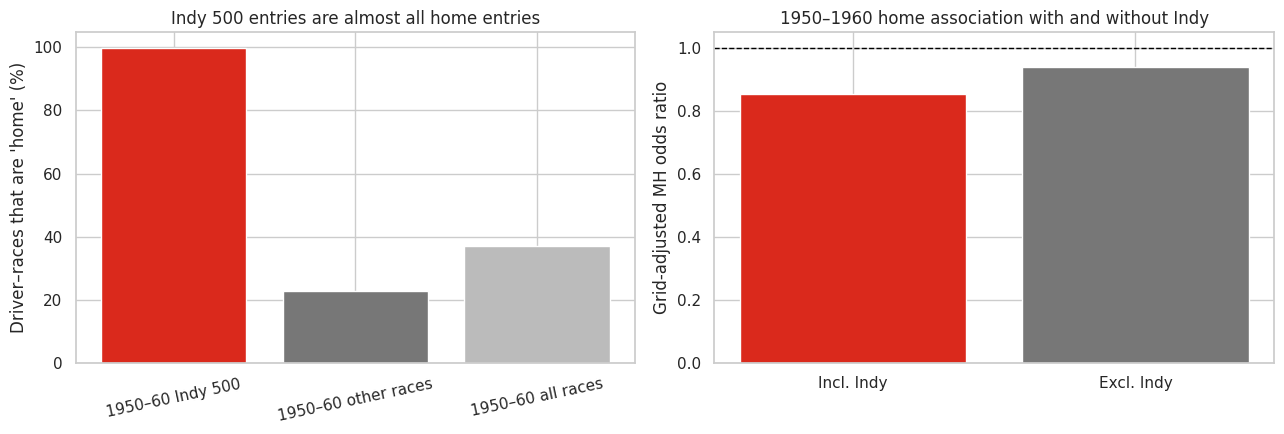

**Q2 finding (auto-generated)**

- Main analysis (1950–2024, Indy 500 excluded, 1945 home driver–races). Raw podium rate: home **11.8%** vs away **13.7%**. After comparing within grid bands, the standardised difference is **-0.5 percentage points**, and the Mantel–Haenszel OR is **0.94** (95% CI 0.79–1.12, CMH p = 0.482). Logistic regression with grid band and decade gives OR = 0.93.
- Including the Indy 500 changes the OR to 0.93. Indy contributes 36 home podiums from a nearly separate driver pool, so it is excluded from the main estimate.
- Sensitivity across eras (grid-adjusted Mantel–Haenszel odds ratios): Main: 1950–2024 excluding Indy 500: OR 0.94 [0.79, 1.12], p = 0.482; All seasons including Indy 500: OR 0.93 [0.80, 1.09], p = 0.398; 1994–2024 (qualifying era): OR 0.69 [0.50, 0.94], p = 0.0209; 2014–2024 (hybrid era): OR 0.78 [0.42, 1.45], p = 0.427. An odds ratio below 1 means home drivers podium *less* often than away drivers from similar grid slots.
- Interpretation: the raw gap is -1.9 pp and the grid-standardised gap is -0.5 pp, so most of the raw difference (home drivers podium less often than away drivers) disappears once grid position is controlled. It therefore largely reflects where home drivers start (many home entries are one-off local drivers starting further back). Also, the 95% CI includes 1, so the grid-adjusted association is not statistically distinguishable from no difference. Any remaining difference is an **association**. Possible explanations include crowd support, track familiarity, and home teams selecting stronger local drivers; these data cannot separate them.

In [21]:
indy = q2[q2.is_indy500]
fifties = q2[q2.year.between(1950, 1960)]
other_fifties = fifties[~fifties.is_indy500]
indy_drivers = set(indy.driverId)
print("Indianapolis 500 races identified (1950–1960):", indy.raceId.nunique(), "| driver–race rows:", len(indy))
display(indy.groupby("year").agg(race_name=("race_name", "first"), entrants=("driverId", "size"),
                                 home_entrants=("is_home_race", "sum"), podiums=("podium", "sum")).reset_index())
print(f"Indy drivers who also started another 1950–1960 championship race: "
      f"{len(indy_drivers & set(other_fifties.driverId))} of {len(indy_drivers)}")
home_podiums_all = int(q2.loc[q2.is_home_race, "podium"].sum())
home_podiums_indy = int(indy.loc[indy.is_home_race, "podium"].sum())
print(f"Indy 500 contributes {home_podiums_indy} of {home_podiums_all} home podiums across 1950–2024 "
      f"({100 * home_podiums_indy / home_podiums_all:.1f}%), from {100 * len(indy) / len(q2):.1f}% of all driver–races.")

indy_compare = pd.DataFrame([
    {"subset": name, "driver_races": len(g), "home_share_pct": 100 * g.is_home_race.mean(),
     "home_podium_rate_pct": 100 * g.loc[g.is_home_race, "podium"].mean(),
     "away_podium_rate_pct": 100 * g.loc[~g.is_home_race, "podium"].mean()}
    for name, g in [("1950–60 Indy 500", indy), ("1950–60 other races", other_fifties), ("1950–60 all races", fifties)]])
display(indy_compare.round(2))
fifties_with = home_effect_summary(fifties, "1950–60 incl. Indy")[0]
fifties_without = home_effect_summary(other_fifties, "1950–60 excl. Indy")[0]
display(pd.DataFrame([fifties_with, fifties_without])[["scenario", "home_driver_races", "raw_home_rate_pct", "raw_away_rate_pct",
                                                      "grid_standardised_diff_pp", "MH_odds_ratio", "MH_CI_low", "MH_CI_high"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(indy_compare.subset, indy_compare.home_share_pct, color=["#da291c", "#777", "#bbb"])
axes[0].set(ylabel="Driver–races that are 'home' (%)", title="Indy 500 entries are almost all home entries")
axes[0].tick_params(axis="x", rotation=12)
labels = ["Incl. Indy", "Excl. Indy"]
axes[1].bar(labels, [fifties_with["MH_odds_ratio"], fifties_without["MH_odds_ratio"]], color=["#da291c", "#777"])
axes[1].axhline(1, color="black", linestyle="--", linewidth=1)
axes[1].set(ylabel="Grid-adjusted MH odds ratio", title="1950–1960 home association with and without Indy")
plt.tight_layout(); plt.show()

main = home_results.set_index("scenario").loc[MAIN_HOME]
with_indy = home_results.set_index("scenario").loc["All seasons including Indy 500"]
raw_gap = main.raw_home_rate_pct - main.raw_away_rate_pct
adjusted_gap = main.grid_standardised_diff_pp
gap_verdict = (f"most of the raw difference (home drivers podium {'less' if raw_gap < 0 else 'more'} often than away drivers) "
               "disappears once grid position is controlled. It therefore largely reflects where home drivers start "
               "(many home entries are one-off local drivers starting further back)"
               if abs(adjusted_gap) < 0.5 * abs(raw_gap) else
               "a substantial part of the raw gap remains after controlling for grid position")
scenario_lines = "; ".join(f"{r.scenario}: OR {r.MH_odds_ratio:.2f} [{r.MH_CI_low:.2f}, {r.MH_CI_high:.2f}], p = {r.CMH_p_value:.3g}"
                           for r in home_results.itertuples())
ci_verdict = ("the 95% CI excludes 1, so the grid-adjusted association is statistically detectable"
              if (main.MH_CI_low > 1 or main.MH_CI_high < 1) else
              "the 95% CI includes 1, so the grid-adjusted association is not statistically distinguishable from no difference")
display(Markdown(f"""**Q2 finding (auto-generated)**

- Main analysis (1950–2024, Indy 500 excluded, {int(main.home_driver_races)} home driver–races). Raw podium rate: home **{main.raw_home_rate_pct:.1f}%** vs away **{main.raw_away_rate_pct:.1f}%**. After comparing within grid bands, the standardised difference is **{main.grid_standardised_diff_pp:+.1f} percentage points**, and the Mantel–Haenszel OR is **{main.MH_odds_ratio:.2f}** (95% CI {main.MH_CI_low:.2f}–{main.MH_CI_high:.2f}, CMH p = {main.CMH_p_value:.3g}). Logistic regression with grid band and decade gives OR = {main.logit_OR_grid_decade:.2f}.
- Including the Indy 500 changes the OR to {with_indy.MH_odds_ratio:.2f}. Indy contributes {home_podiums_indy} home podiums from a nearly separate driver pool, so it is excluded from the main estimate.
- Sensitivity across eras (grid-adjusted Mantel–Haenszel odds ratios): {scenario_lines}. An odds ratio below 1 means home drivers podium *less* often than away drivers from similar grid slots.
- Interpretation: the raw gap is {raw_gap:+.1f} pp and the grid-standardised gap is {adjusted_gap:+.1f} pp, so {gap_verdict}. Also, {ci_verdict}. Any remaining difference is an **association**. Possible explanations include crowd support, track familiarity, and home teams selecting stronger local drivers; these data cannot separate them."""))

#### Answer to Q2 — home-country podium effect

**Join and mapping:** driver nationality (e.g. "British") → reviewed mapping → circuit country (e.g. "UK"), via `races` → `circuits`. All 43 nationality values that occur are reviewed. One string with a stray space (`"Argentinian "`) is normalised. Nationalities without a home race, such as Finnish or Danish, are always "away". 2,325 of 25,100 driver–races (9.3%) are home races.

**Control for starting position:** home and away are compared *within the same grid band* (P1, P2, P3, P4–6, P7–10, P11+, grid 0), then pooled with a Mantel–Haenszel odds ratio. A logistic regression with grid band and decade gives the same answer.

**Answer:**
- Raw podium rate (excluding the Indy 500): home **11.8%** vs away **13.7%**. Home drivers podium *less* often overall, mainly because many home entries are one-off local drivers starting further back.
- After controlling for grid, the gap shrinks to −0.5 percentage points. **OR = 0.94 (95% CI 0.79–1.12, p = 0.48)**, and the logistic regression gives OR 0.93. **There is no detectable home advantage.**
- By era: 1994–2024 shows a significant home *disadvantage* (OR 0.69, CI 0.50–0.94, p = 0.021), and 2014–2024 shows no effect (OR 0.78, CI 0.42–1.45).

**Indianapolis 500 (1950–1960):** the 11 Indy races contain 381 driver–races, and 380 of them are "home" (American drivers in the USA). Only 3 of the 107 Indy drivers ever started another championship race in 1950–1960. Indy supplies 36 of the 266 home podiums (13.5%) from just 1.5% of all rows, so it is a separate competition and is excluded from the main estimate. With it included, the OR is 0.93.

**Interpretation:** this is an association in observational data, not proof that racing at home helps or hurts. Possible factors such as crowd support, track familiarity, and local drivers being selected for their home race cannot be separated with these data.

### 21. Q3 — Mechanical retirements: explicit status mapping and race-start denominator

**Question (brief):** Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 2022–2024?

**Definition (brief):** a mechanical retirement is *a race start that ended early because a component of the car failed*. It excludes failures caused by a crash, by the driver, or by a regulation decision. The status mapping below follows that definition. Lapped finishers ("+1 Lap" and so on) count as finished, as the F1 guide states.

**Grain and denominator:** One **race start** = one car that took the start. We use all result rows in 2014–2024; there are no shared drives in this period, which we assert. A row is *not* a start if `positionText` is F (failed to qualify) or W (withdrawn before the start). A few rows have status "Withdrew" but a race classification (a finishing number or R). Those cars **did** start and stopped during the race, so they stay in the denominator under "other". Disqualified and non-classified cars also started and stay in the denominator.

**Status mapping:** Every status is assigned to exactly one category:
- `finished` (Finished, +n Laps)
- `mechanical failure` (car or power-unit component failures: engine, gearbox, hydraulics, brakes, suspension, electrical, overheating, power unit, wheel/driveshaft failures, and similar)
- `crash / contact` (accident, collision, collision damage, spun off, damage, debris)
- `driver-related` (illness, injury, physical, stalled)
- `regulatory` (disqualified, excluded, underweight, safety concerns)
- `other` (tyre/puncture, out of fuel, pit-stop wheel issues, unspecified "Retired", not classified)

Exact names are checked first, then mechanical keywords. **The full mapping table for every status that occurs is printed below for review.**

In [22]:
FINISHED_RE = re.compile(r"^(Finished|\+\d+ Laps?)$")
NON_START_STATUSES = {"Did not qualify", "Did not prequalify", "Withdrew", "Did not start", "Not qualified"}
CRASH_STATUSES = {"Accident", "Collision", "Collision damage", "Spun off", "Damage", "Fatal accident", "Debris"}
DRIVER_STATUSES = {"Driver unwell", "Physical", "Injured", "Injury", "Illness", "Eye injury", "Fatigue",
                   "Stalled", "Driver Seat"}
REGULATORY_STATUSES = {"Disqualified", "Excluded", "Underweight", "107% Rule", "Safety concerns", "Safety"}
OTHER_STATUSES = {"Retired", "Not classified", "Out of fuel", "Fuel rig", "Refuelling", "Wheel nut", "Loose wheel",
                  "Tyre", "Puncture", "Not restarted", "Safety belt", "Withdrawn"}
MECHANICAL_RE = re.compile(
    r"engine|gearbox|transmission|clutch|hydraulic|electric|radiator|suspension|brake|differential|overheat|"
    r"mechanical|oil|fuel|water|throttle|steering|technical|electronic|power unit|power loss|\bers\b|turbo|battery|exhaust|"
    r"drive ?shaft|halfshaft|axle|vibration|pneumatic|spark|ignition|injection|alternator|magneto|cooling|"
    r"drivetrain|crankshaft|camshaft|piston|valve|supercharger|wheel|track rod|chassis|undertray|wing|"
    r"cv joint|launch|heat shield|fire|handling|distributor|spoiler|wiring|sensor|pump|leak|seat", re.IGNORECASE)

def categorize_status(status):
    s = str(status).strip()
    if FINISHED_RE.match(s):
        return "finished"
    if s in NON_START_STATUSES:
        return "non-start"
    for category, names in [("crash / contact", CRASH_STATUSES), ("driver-related", DRIVER_STATUSES),
                            ("regulatory", REGULATORY_STATUSES), ("other", OTHER_STATUSES)]:
        if s in names:
            return category
    return "mechanical failure" if MECHANICAL_RE.search(s) else "other"

constructor_names = (clean_tables["constructors"][["constructorId", "constructorRef", "name"]]
                     .rename(columns={"name": "constructor_name"}))
q3 = (result_rows[["resultId", "raceId", "driverId", "constructorId", "grid", "positionText", "statusId"]]
      .merge(clean_tables["races"][["raceId", "year", "name"]].rename(columns={"name": "race_name"}),
             on="raceId", how="left", validate="many_to_one")
      .merge(status_names, on="statusId", how="left", validate="many_to_one")
      .merge(constructor_names, on="constructorId", how="left", validate="many_to_one"))
q3 = q3[q3.year.between(2014, 2024)].copy()
assert not q3.duplicated(pair).any(), "Expected one result row per driver–race in 2014–2024"
assert q3.status.notna().all()
q3["outcome_category"] = q3.status.map(categorize_status)
q3["race_start"] = ~q3.positionText.isin(["F", "W"])
# A "Withdrew" status on a car with a race classification means it started and then stopped -> "other"
q3.loc[q3.race_start & q3.outcome_category.eq("non-start"), "outcome_category"] = "other"
q3["period"] = np.where(q3.year <= 2021, "2014–2021", "2022–2024")

status_map_table = (q3.groupby(["outcome_category", "status"]).size().rename("result_rows").reset_index()
                    .sort_values(["outcome_category", "result_rows"], ascending=[True, False]))
print("Result rows 2014–2024:", len(q3), "| race starts:", int(q3.race_start.sum()),
      "| excluded non-starts:", int((~q3.race_start).sum()))
print("Excluded rows by status:")
display(q3.loc[~q3.race_start].groupby(["positionText", "status"]).size().rename("rows").reset_index())
print("Complete status -> category mapping for 2014–2024 (review this table):")
display(status_map_table.reset_index(drop=True))

Result rows 2014–2024: 4626 | race starts: 4598 | excluded non-starts: 28
Excluded rows by status:


,positionText,status,rows
0,W,Brakes,1
1,W,Driveshaft,1
2,W,ERS,1
3,W,Engine,2
4,W,Exhaust,1
5,W,Fuel leak,1
6,W,Fuel system,1
7,W,Gearbox,2
8,W,Hydraulics,1
9,W,Illness,1


Complete status -> category mapping for 2014–2024 (review this table):


,outcome_category,status,result_rows
0,crash / contact,Collision,150
1,crash / contact,Accident,85
2,crash / contact,Collision damage,59
3,crash / contact,Spun off,11
4,crash / contact,Damage,2
5,crash / contact,Debris,1
6,driver-related,Illness,3
7,finished,Finished,2403
8,finished,+1 Lap,1178
9,finished,+2 Laps,208


### 22. Q3 — Mechanical-retirement rates by constructor, 2014–2021 vs 2022–2024

**Constructor identity:** the F1 guide notes that each constructor name is a separate `constructorId`. The **primary answer** is therefore a ranking of constructors *as recorded* in each period (Section 22b). Several teams were renamed between the periods (for example, Racing Point became Aston Martin), so a supplementary view also groups renamed teams into an explicit **team lineage** mapped by `constructorRef`, to compare the same organisation across both periods. Rates always include counts (`mechanical / starts`) and 95% Wilson intervals. We also test the change in the overall rate with a χ² test, and the change for each team with Fisher's exact test.

,team,constructor_name,first,last,starts
0,Caterham,Caterham,2014,2014,33
1,Ferrari,Ferrari,2014,2024,452
2,Force India / Racing Point / Aston Martin,Aston Martin,2021,2024,178
3,Force India / Racing Point / Aston Martin,Force India,2014,2018,198
4,Force India / Racing Point / Aston Martin,Racing Point,2019,2020,75
5,Haas F1 Team,Haas F1 Team,2016,2024,376
6,Lotus F1 / Renault / Alpine,Alpine F1 Team,2021,2024,179
7,Lotus F1 / Renault / Alpine,Lotus F1,2014,2015,75
8,Lotus F1 / Renault / Alpine,Renault,2016,2020,199
9,Marussia / Manor,Manor Marussia,2015,2016,77


All constructors, by period (counts and rates):


outcome_category,period,finished,mechanical failure,crash / contact,driver-related,regulatory,other,starts,mechanical_rate_pct,wilson_low_pct,wilson_high_pct
0,2014–2021,2660,304,219,1,8,54,3246,9.37,8.41,10.42
1,2022–2024,1165,80,89,1,4,13,1352,5.92,4.78,7.30


Overall change in mechanical-retirement rate: chi-square = 14.38, p = 0.000149
By recorded constructor name:


outcome_category,constructor_name,period,finished,mechanical failure,crash / contact,driver-related,regulatory,other,starts,mechanical_rate_pct,wilson_low_pct,wilson_high_pct
0,Alfa Romeo,2014–2021,109,5,6,0,0,0,120,4.17,1.79,9.38
1,Alfa Romeo,2022–2024,71,11,6,0,0,0,88,12.50,7.13,21.01
2,AlphaTauri,2014–2021,65,7,4,0,0,1,77,9.09,4.47,17.60
3,AlphaTauri,2022–2024,74,7,7,0,0,0,88,7.95,3.91,15.52
4,Alpine F1 Team,2014–2021,39,4,1,0,0,0,44,9.09,3.59,21.16
5,Alpine F1 Team,2022–2024,112,14,9,0,0,0,135,10.37,6.28,16.66
6,Aston Martin,2014–2021,36,1,5,0,1,1,44,2.27,0.40,11.81
7,Aston Martin,2022–2024,118,7,7,0,0,2,134,5.22,2.55,10.39
8,Caterham,2014–2021,21,7,2,0,0,3,33,21.21,10.68,37.75
9,Ferrari,2014–2021,277,18,21,0,0,2,318,5.66,3.61,8.77


Team lineages present in both periods:


,starts_2014_21,mech_2014_21,rate_2014_21_pct,starts_2022_24,mech_2022_24,rate_2022_24_pct,change_pp,fisher_p
team,,,,,,,,
McLaren,316,43,13.608,136,5,3.676,-9.931,0.001
Toro Rosso / AlphaTauri / RB,319,46,14.420,136,9,6.618,-7.802,0.019
Red Bull,318,34,10.692,136,5,3.676,-7.015,0.016
Lotus F1 / Renault / Alpine,318,46,14.465,135,14,10.370,-4.095,0.289
Haas F1 Team,241,21,8.714,135,7,5.185,-3.529,0.306
Williams,319,24,7.524,134,8,5.970,-1.553,0.689
Force India / Racing Point / Aston Martin,317,20,6.309,134,7,5.224,-1.085,0.829
Ferrari,318,18,5.660,134,7,5.224,-0.436,1.000
Mercedes,320,12,3.750,136,6,4.412,0.662,0.794


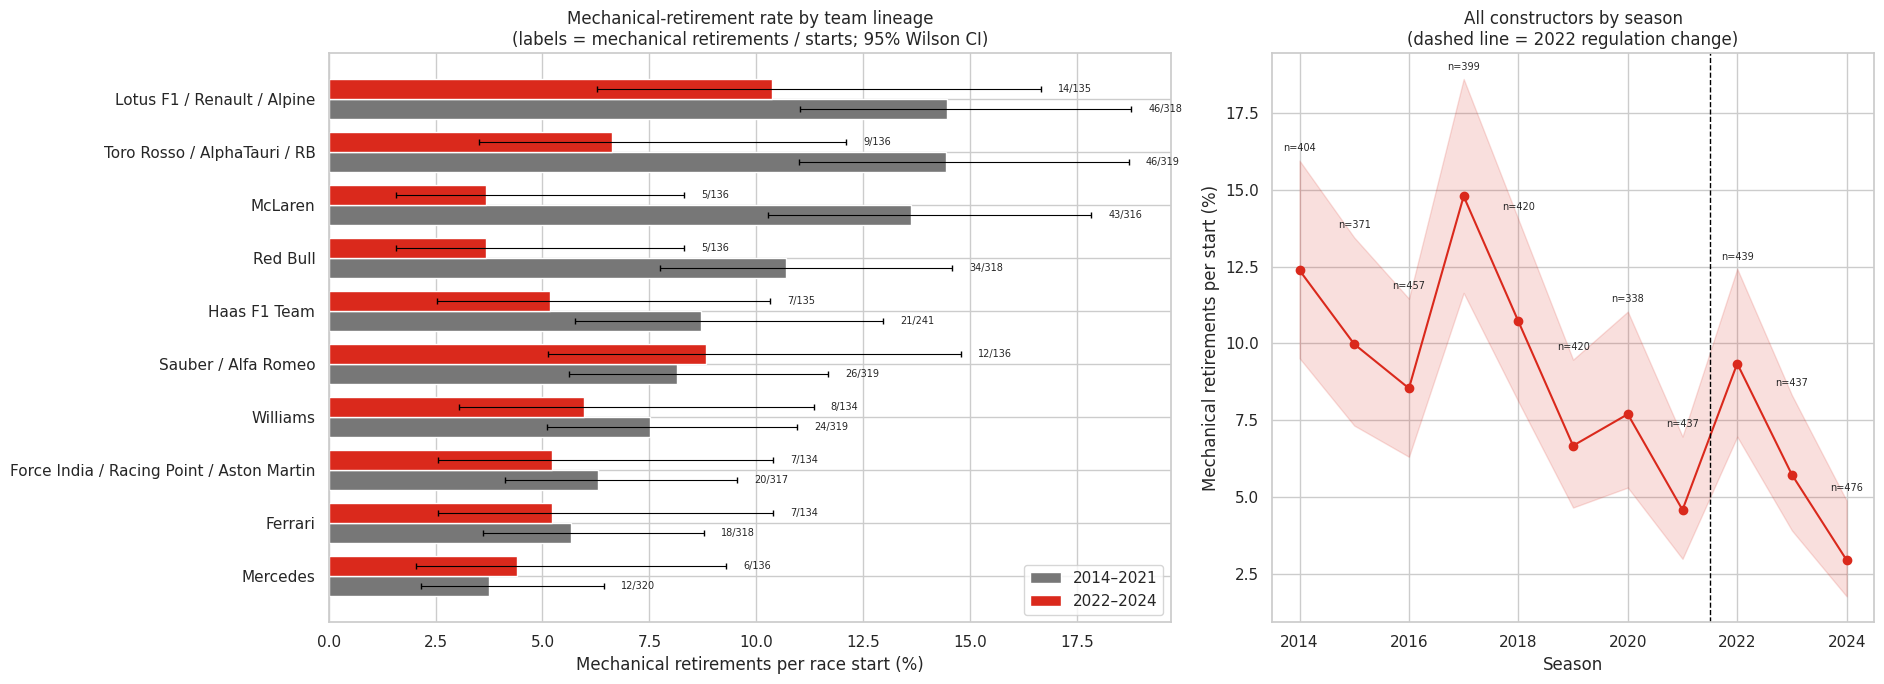

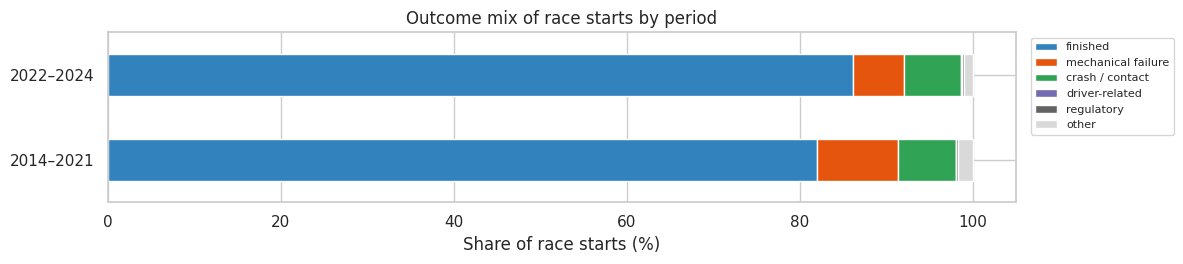

In [23]:
TEAM_LINEAGE = {
    "toro_rosso": "Toro Rosso / AlphaTauri / RB", "alphatauri": "Toro Rosso / AlphaTauri / RB", "rb": "Toro Rosso / AlphaTauri / RB",
    "force_india": "Force India / Racing Point / Aston Martin", "racing_point": "Force India / Racing Point / Aston Martin",
    "aston_martin": "Force India / Racing Point / Aston Martin",
    "lotus_f1": "Lotus F1 / Renault / Alpine", "renault": "Lotus F1 / Renault / Alpine", "alpine": "Lotus F1 / Renault / Alpine",
    "sauber": "Sauber / Alfa Romeo", "alfa": "Sauber / Alfa Romeo",
    "marussia": "Marussia / Manor", "manor": "Marussia / Manor",
}
OUTCOME_ORDER = ["finished", "mechanical failure", "crash / contact", "driver-related", "regulatory", "other"]
PERIODS = ["2014–2021", "2022–2024"]
starts = q3[q3.race_start].copy()
starts["team"] = starts.constructorRef.map(TEAM_LINEAGE).fillna(starts.constructor_name)
display(starts.groupby(["team", "constructor_name"]).agg(first=("year", "min"), last=("year", "max"), starts=("resultId", "size")).reset_index())

def outcome_rates(frame, keys):
    counts = frame.groupby(keys + ["outcome_category"]).size().unstack("outcome_category", fill_value=0)
    counts = counts.reindex(columns=OUTCOME_ORDER, fill_value=0)
    counts["starts"] = counts.sum(axis=1)
    counts["mechanical_rate_pct"] = 100 * counts["mechanical failure"] / counts.starts
    low, high = wilson_interval(counts["mechanical failure"], counts.starts)
    counts["wilson_low_pct"], counts["wilson_high_pct"] = 100 * low, 100 * high
    return counts.reset_index()

period_rates = outcome_rates(starts, ["period"])
team_rates = outcome_rates(starts, ["team", "period"])
recorded_rates = outcome_rates(starts, ["constructor_name", "period"])
print("All constructors, by period (counts and rates):")
display(period_rates.round(2))
chi2, chi2_p, _, _ = stats.chi2_contingency(period_rates[["mechanical failure"]].assign(
    not_mechanical=period_rates.starts - period_rates["mechanical failure"]).to_numpy())
print(f"Overall change in mechanical-retirement rate: chi-square = {chi2:.2f}, p = {chi2_p:.3g}")
print("By recorded constructor name:")
display(recorded_rates.sort_values(["constructor_name", "period"]).round(2))

team_wide = team_rates.pivot(index="team", columns="period", values=["starts", "mechanical failure", "mechanical_rate_pct"])
both = team_wide.dropna()
team_comparison = pd.DataFrame({
    "starts_2014_21": both[("starts", PERIODS[0])].astype(int), "mech_2014_21": both[("mechanical failure", PERIODS[0])].astype(int),
    "rate_2014_21_pct": both[("mechanical_rate_pct", PERIODS[0])],
    "starts_2022_24": both[("starts", PERIODS[1])].astype(int), "mech_2022_24": both[("mechanical failure", PERIODS[1])].astype(int),
    "rate_2022_24_pct": both[("mechanical_rate_pct", PERIODS[1])]})
team_comparison["change_pp"] = team_comparison.rate_2022_24_pct - team_comparison.rate_2014_21_pct
team_comparison["fisher_p"] = [stats.fisher_exact([[r.mech_2014_21, r.starts_2014_21 - r.mech_2014_21],
                                                   [r.mech_2022_24, r.starts_2022_24 - r.mech_2022_24]])[1]
                               for r in team_comparison.itertuples()]
print("Team lineages present in both periods:")
display(team_comparison.sort_values("change_pp").round(3))

plot_rates = team_rates[team_rates.team.isin(team_comparison.index)]
order = team_comparison.sort_values("rate_2014_21_pct").index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(19, 7), gridspec_kw={"width_ratios": [1.4, 1]})
y = np.arange(len(order)); h = 0.38
for offset, period, colour in [(-h / 2, PERIODS[0], "#777777"), (h / 2, PERIODS[1], "#da291c")]:
    d = plot_rates[plot_rates.period == period].set_index("team").reindex(order)
    axes[0].barh(y + offset, d.mechanical_rate_pct, h, color=colour, label=period)
    axes[0].errorbar(d.mechanical_rate_pct, y + offset, fmt="none", ecolor="black", capsize=2, linewidth=.8,
                     xerr=[d.mechanical_rate_pct - d.wilson_low_pct, d.wilson_high_pct - d.mechanical_rate_pct])
    for yi, (hi, k, n) in enumerate(zip(d.wilson_high_pct, d["mechanical failure"], d.starts)):
        axes[0].text(hi + 0.4, yi + offset, f"{int(k)}/{int(n)}", va="center", fontsize=7)
axes[0].set_yticks(y, order)
axes[0].set(xlabel="Mechanical retirements per race start (%)", title="Mechanical-retirement rate by team lineage\n(labels = mechanical retirements / starts; 95% Wilson CI)")
axes[0].legend(loc="lower right")
season = outcome_rates(starts, ["year"])
axes[1].plot(season.year, season.mechanical_rate_pct, marker="o", color="#da291c")
axes[1].fill_between(season.year, season.wilson_low_pct, season.wilson_high_pct, color="#da291c", alpha=.15)
for r in season.itertuples():
    axes[1].text(r.year, r.wilson_high_pct + 0.3, f"n={r.starts}", ha="center", fontsize=7)
axes[1].axvline(2021.5, color="black", linestyle="--", linewidth=1)
axes[1].set(xlabel="Season", ylabel="Mechanical retirements per start (%)", title="All constructors by season\n(dashed line = 2022 regulation change)")
plt.tight_layout(); plt.show()

share = period_rates.set_index("period")[OUTCOME_ORDER].div(period_rates.set_index("period").starts, axis=0) * 100
ax = share.plot(kind="barh", stacked=True, figsize=(12, 2.8), colormap="tab20c")
ax.set(xlabel="Share of race starts (%)", ylabel="", title="Outcome mix of race starts by period")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

#### 22b. Answer: constructors with the highest mechanical-retirement rate in each period

Constructors are ranked within each period by mechanical retirements per race start. To stop a team with a handful of starts topping the list by chance, only constructors with **at least 20 starts** in the period are ranked; smaller entries are listed separately. Counts and 95% Wilson intervals are shown with every rate.


2014–2021: constructors ranked by mechanical-retirement rate (>= 20 starts)


outcome_category,rank_in_period,constructor_name,starts,mechanical failure,mechanical_rate_pct,wilson_low_pct,wilson_high_pct
8,1,Caterham,33,7,21.21,10.68,37.75
14,2,Lotus F1,75,14,18.67,11.46,28.93
28,3,Toro Rosso,242,39,16.12,12.02,21.27
25,4,Renault,199,28,14.07,9.92,19.58
17,5,McLaren,316,43,13.61,10.26,17.83
23,6,Red Bull,318,34,10.69,7.75,14.57
26,7,Sauber,199,21,10.55,7.01,15.59
16,8,Marussia,31,3,9.68,3.35,24.90
4,9,Alpine F1 Team,44,4,9.09,3.59,21.16
2,9,AlphaTauri,77,7,9.09,4.47,17.60



2022–2024: constructors ranked by mechanical-retirement rate (>= 20 starts)


outcome_category,rank_in_period,constructor_name,starts,mechanical failure,mechanical_rate_pct,wilson_low_pct,wilson_high_pct
1,1,Alfa Romeo,88,11,12.50,7.13,21.01
5,2,Alpine F1 Team,135,14,10.37,6.28,16.66
3,3,AlphaTauri,88,7,7.95,3.91,15.52
30,4,Williams,134,8,5.97,3.06,11.34
10,5,Ferrari,134,7,5.22,2.55,10.39
7,5,Aston Martin,134,7,5.22,2.55,10.39
13,7,Haas F1 Team,135,7,5.19,2.53,10.32
20,8,Mercedes,136,6,4.41,2.04,9.29
21,9,RB F1 Team,48,2,4.17,1.15,13.98
18,10,McLaren,136,5,3.68,1.58,8.32


Constructors below the minimum-starts rule (not ranked): none


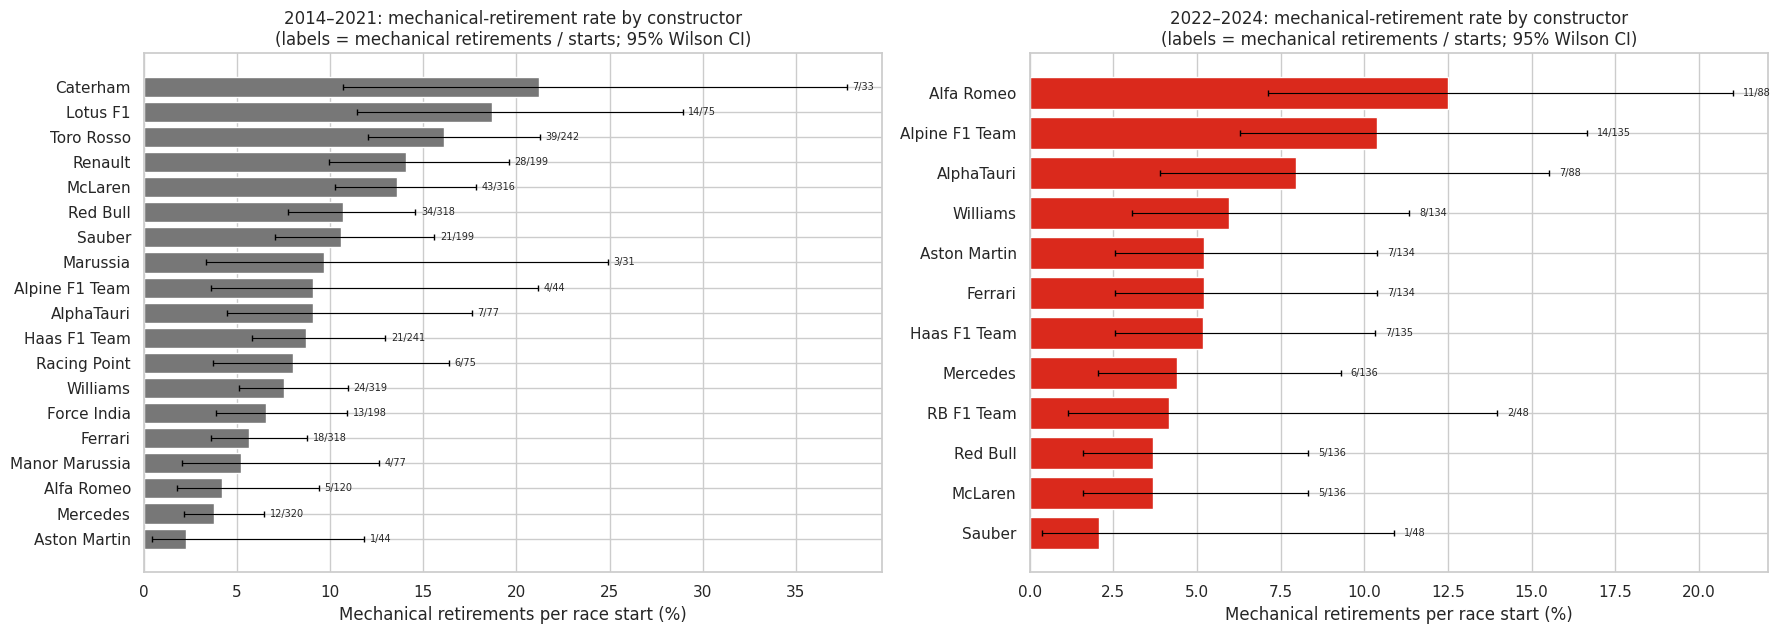

In [24]:
MIN_STARTS_RANK = 20
ranked_constructors = recorded_rates[recorded_rates.starts >= MIN_STARTS_RANK].copy()
ranked_constructors["rank_in_period"] = (ranked_constructors.groupby("period").mechanical_rate_pct
                                         .rank(ascending=False, method="min").astype(int))
rank_cols = ["rank_in_period", "constructor_name", "starts", "mechanical failure", "mechanical_rate_pct",
             "wilson_low_pct", "wilson_high_pct"]
for period in PERIODS:
    print(f"\n{period}: constructors ranked by mechanical-retirement rate (>= {MIN_STARTS_RANK} starts)")
    display(ranked_constructors[ranked_constructors.period == period].sort_values("rank_in_period")[rank_cols].round(2))
small_entries = recorded_rates[recorded_rates.starts < MIN_STARTS_RANK]
print("Constructors below the minimum-starts rule (not ranked):",
      small_entries[["constructor_name", "period", "starts"]].to_dict("records") or "none")

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
for ax, period, colour in zip(axes, PERIODS, ["#777777", "#da291c"]):
    d = ranked_constructors[ranked_constructors.period == period].sort_values("mechanical_rate_pct")
    y = np.arange(len(d))
    ax.barh(y, d.mechanical_rate_pct, color=colour)
    ax.errorbar(d.mechanical_rate_pct, y, fmt="none", ecolor="black", capsize=2, linewidth=.8,
                xerr=[d.mechanical_rate_pct - d.wilson_low_pct, d.wilson_high_pct - d.mechanical_rate_pct])
    for yi, (hi, k, n) in enumerate(zip(d.wilson_high_pct, d["mechanical failure"], d.starts)):
        ax.text(hi + 0.3, yi, f"{int(k)}/{int(n)}", va="center", fontsize=7)
    ax.set_yticks(y, d.constructor_name)
    ax.set(xlabel="Mechanical retirements per race start (%)",
           title=f"{period}: mechanical-retirement rate by constructor\n(labels = mechanical retirements / starts; 95% Wilson CI)")
plt.tight_layout(); plt.show()
highest = {p: ranked_constructors[ranked_constructors.period == p].nlargest(3, "mechanical_rate_pct") for p in PERIODS}

In [25]:
pr = period_rates.set_index("period")
improved = team_comparison.sort_values("change_pp").head(3)
worsened = team_comparison.sort_values("change_pp", ascending=False).head(2)
display(Markdown(f"""**Q3 finding (auto-generated)**

- Denominator: {len(starts)} race starts in 2014–2024 ({int((~q3.race_start).sum())} non-starts removed). Every status is mapped explicitly; see the table in Section 21.
- **Highest mechanical-retirement rate, 2014–2021:** {"; ".join(f"**{r.constructor_name}** {r.mechanical_rate_pct:.1f}% ({int(r.mech)}/{int(r.starts)})" for r in highest[PERIODS[0]].rename(columns={"mechanical failure": "mech"}).itertuples())}.
- **Highest mechanical-retirement rate, 2022–2024:** {"; ".join(f"**{r.constructor_name}** {r.mechanical_rate_pct:.1f}% ({int(r.mech)}/{int(r.starts)})" for r in highest[PERIODS[1]].rename(columns={"mechanical failure": "mech"}).itertuples())}.
- Across all constructors, mechanical failures ended **{pr.loc[PERIODS[0], 'mechanical_rate_pct']:.1f}%** of starts in 2014–2021 ({int(pr.loc[PERIODS[0], 'mechanical failure'])}/{int(pr.loc[PERIODS[0], 'starts'])}) and **{pr.loc[PERIODS[1], 'mechanical_rate_pct']:.1f}%** in 2022–2024 ({int(pr.loc[PERIODS[1], 'mechanical failure'])}/{int(pr.loc[PERIODS[1], 'starts'])}); χ² p = {chi2_p:.3g}.
- Largest decreases: {"; ".join(f"{t} {r.rate_2014_21_pct:.1f}% → {r.rate_2022_24_pct:.1f}% ({int(r.mech_2014_21)}/{int(r.starts_2014_21)} → {int(r.mech_2022_24)}/{int(r.starts_2022_24)})" for t, r in improved.iterrows())}.
- Largest increases: {"; ".join(f"{t} {r.rate_2014_21_pct:.1f}% → {r.rate_2022_24_pct:.1f}%" for t, r in worsened.iterrows())}.
- Interpretation: the 2014–2021 period includes the first hybrid seasons, which were known for power-unit unreliability. A lower 2022–2024 rate fits a maturing power-unit era with frozen engine development, but the second period has only three seasons, so each team has far fewer starts. Team-level intervals are therefore wide; check the Fisher p-values before calling a per-team change real. These are descriptive rates, not causal effects of the regulations."""))

**Q3 finding (auto-generated)**

- Denominator: 4598 race starts in 2014–2024 (28 non-starts removed). Every status is mapped explicitly; see the table in Section 21.
- **Highest mechanical-retirement rate, 2014–2021:** **Caterham** 21.2% (7/33); **Lotus F1** 18.7% (14/75); **Toro Rosso** 16.1% (39/242).
- **Highest mechanical-retirement rate, 2022–2024:** **Alfa Romeo** 12.5% (11/88); **Alpine F1 Team** 10.4% (14/135); **AlphaTauri** 8.0% (7/88).
- Across all constructors, mechanical failures ended **9.4%** of starts in 2014–2021 (304/3246) and **5.9%** in 2022–2024 (80/1352); χ² p = 0.000149.
- Largest decreases: McLaren 13.6% → 3.7% (43/316 → 5/136); Toro Rosso / AlphaTauri / RB 14.4% → 6.6% (46/319 → 9/136); Red Bull 10.7% → 3.7% (34/318 → 5/136).
- Largest increases: Sauber / Alfa Romeo 8.2% → 8.8%; Mercedes 3.8% → 4.4%.
- Interpretation: the 2014–2021 period includes the first hybrid seasons, which were known for power-unit unreliability. A lower 2022–2024 rate fits a maturing power-unit era with frozen engine development, but the second period has only three seasons, so each team has far fewer starts. Team-level intervals are therefore wide; check the Fisher p-values before calling a per-team change real. These are descriptive rates, not causal effects of the regulations.

#### Answer to Q3 — mechanical retirements by constructor

**Definition (from the brief):** a mechanical retirement is a race start that ended because a car component failed. Crashes, driver causes, and regulation decisions are excluded. Every `status` value is mapped explicitly (Section 21 table): finished (including "+n Laps"), mechanical failure, crash / contact, driver-related, regulatory, or other (tyre or puncture, pit-stop wheel nut, out of fuel, unspecified "Retired").

**Denominator:** race starts in 2014–2024 = 4,598. The 28 cars that failed to qualify or withdrew before the start (`positionText` F/W) are excluded.

**Answer — highest mechanical-retirement rate (constructors with ≥ 20 starts):**
- **2014–2021:** **Caterham 21.2%** (7/33), Lotus F1 18.7% (14/75), Toro Rosso 16.1% (39/242), Renault 14.1% (28/199), McLaren 13.6% (43/316).
- **2022–2024:** **Alfa Romeo 12.5%** (11/88), Alpine 10.4% (14/135), AlphaTauri 8.0% (7/88), Williams 6.0% (8/134).
- Across all constructors, the rate fell from **9.4% (304/3,246)** to **5.9% (80/1,352)** (χ² p = 0.0001).
- Following renamed teams as one lineage, the clearest improvements are McLaren 13.6% → 3.7% (Fisher p = 0.001), Toro Rosso/AlphaTauri/RB 14.4% → 6.6%, and Red Bull 10.7% → 3.7%.

**Interpretation:** the early hybrid seasons (2014–2016) had many power-unit failures; by 2022–2024 the units were mature and development was frozen. The 2022–2024 period has only three seasons (about 135 starts per team), so team-level intervals are wide. These are descriptive rates, not causal effects of the regulations.

### 23. Step 3 summary

The three answers above each provide (1) an explicit grain and join check, (2) a missingness or eligibility rule, (3) at least one labeled figure, (4) counts with rates, and (5) an auto-generated finding to copy into the report. The table below gathers the headline numbers in one place for the PDF.

In [26]:
step3_summary = pd.DataFrame([
    ("Q1", "Front-row (grid 1–2) conversion, 1950–2013", f"{q1_findings['pre_rate']:.1f}% (n={q1_findings['pre_n']})"),
    ("Q1", "Front-row (grid 1–2) conversion, 2014–2024", f"{q1_findings['hyb_rate']:.1f}% (n={q1_findings['hyb_n']})"),
    ("Q1", "Circuit-rate rank correlation across eras", f"rho={q1_findings['rho']:.2f} over {q1_findings['n_shared']} circuits"),
    ("Q2", "Raw home vs away podium rate (excl. Indy)", f"{main.raw_home_rate_pct:.1f}% vs {main.raw_away_rate_pct:.1f}%"),
    ("Q2", "Grid-adjusted MH odds ratio (excl. Indy)", f"{main.MH_odds_ratio:.2f} [{main.MH_CI_low:.2f}, {main.MH_CI_high:.2f}]"),
    ("Q2", "Grid-adjusted MH odds ratio (incl. Indy)", f"{with_indy.MH_odds_ratio:.2f}"),
    ("Q3", "Mechanical retirement rate 2014–2021", f"{pr.loc[PERIODS[0], 'mechanical_rate_pct']:.1f}% ({int(pr.loc[PERIODS[0], 'mechanical failure'])}/{int(pr.loc[PERIODS[0], 'starts'])})"),
    ("Q3", "Highest-rate constructor 2014–2021", f"{highest[PERIODS[0]].constructor_name.iloc[0]} {highest[PERIODS[0]].mechanical_rate_pct.iloc[0]:.1f}%"),
    ("Q3", "Highest-rate constructor 2022–2024", f"{highest[PERIODS[1]].constructor_name.iloc[0]} {highest[PERIODS[1]].mechanical_rate_pct.iloc[0]:.1f}%"),
    ("Q3", "Mechanical retirement rate 2022–2024", f"{pr.loc[PERIODS[1], 'mechanical_rate_pct']:.1f}% ({int(pr.loc[PERIODS[1], 'mechanical failure'])}/{int(pr.loc[PERIODS[1], 'starts'])})"),
], columns=["question", "measure", "value"])
display(step3_summary)
assert len(analysis_table) == 25_100 and analysis_table[pair].duplicated().sum() == 0
print("Step 3 complete: analysis_table unchanged (25,100 unique driver–race rows).")

,question,measure,value
0,Q1,"Front-row (grid 1–2) conversion, 1950–2013",56.1% (n=1805)
1,Q1,"Front-row (grid 1–2) conversion, 2014–2024",76.0% (n=454)
2,Q1,Circuit-rate rank correlation across eras,rho=-0.03 over 16 circuits
3,Q2,Raw home vs away podium rate (excl. Indy),11.8% vs 13.7%
4,Q2,Grid-adjusted MH odds ratio (excl. Indy),"0.94 [0.79, 1.12]"
5,Q2,Grid-adjusted MH odds ratio (incl. Indy),0.93
6,Q3,Mechanical retirement rate 2014–2021,9.4% (304/3246)
7,Q3,Highest-rate constructor 2014–2021,Caterham 21.2%
8,Q3,Highest-rate constructor 2022–2024,Alfa Romeo 12.5%
9,Q3,Mechanical retirement rate 2022–2024,5.9% (80/1352)


Step 3 complete: analysis_table unchanged (25,100 unique driver–race rows).


## Step 4 — Engineer and justify pre-race features

**Goal:** Build a leakage-safe feature table at the same grain as `analysis_table` (one row per eligible driver–race; 25,100 rows). Every feature must be **known after qualifying and before the race starts**. Form and standings features use **past races only**: each driver's or team's history is shifted so the current race never contributes to its own features.

**Feature groups** (these are also the units used for the Step 7 ablations; the brief's example groups are standings, qualifying, and grid, so each has its own group):

| Group | Features | Source and timing |
|---|---|---|
| `grid` | start position, start position as % of field, grid-zero (pit-lane) flag, grid penalty places (grid − qualifying position) | Starting grid, fixed after qualifying and penalties, before lights out |
| `qualifying` | qualifying position, Q1 gap to fastest, best-session gap to pole, qualifying format | Current-race qualifying session, before the race |
| `driver_form` | previous starts, podium rate over last 5 races, average finish % over last 5, classified-finish rate over last 10, career podium rate, age | Driver's *previous* races only |
| `constructor_form` | previous team races, team podium rate over last 5, team best-finish % over last 5, team finish rate over last 10 | Team's *previous* races only (follows `constructorId`, so a rename resets history, as the F1 guide notes) |
| `standings` | championship position, points share of leader, and wins after the *previous* round; last season's final driver and constructor positions | Standings shifted to "before this race" |
| `race_context` | field size, season progress, home-race flag (from Q2) | Entry list, calendar, nationality vs circuit country |

### 24. Availability audit at the prediction cutoff

**Why:** Before engineering features, we classify every candidate field by whether it is known at the cutoff. The F1 guide calls the sprint "a leakage judgement call", so it gets an explicit check here, together with the qualifying date.

In [27]:
availability = pd.DataFrame([
    ("results.grid (current race)", "Known", "Starting grid is fixed after qualifying and penalties, before lights out", "Feature"),
    ("qualifying.position / q1–q3 (current race)", "Known", "Qualifying session ends before the race", "Feature (1994+ coverage)"),
    ("sprint_results (current weekend)", "Known on sprint weekends", "Sprint runs the day before the Grand Prix", "Excluded: no sprint races in the training seasons (≤ 2019)"),
    ("results/standings of PREVIOUS races", "Known", "Published after earlier rounds", "Feature via shift(1) / as-of joins"),
    ("driver/constructor standings AFTER this race", "Not known", "Includes this race's points", "Never used; as-of join uses earlier rounds only"),
    ("positionOrder (current race)", "Not known", "Race outcome", "Target source only"),
    ("points, laps, time, fastest lap, status (current race)", "Not known", "Race outcome", "Never used as features"),
    ("lap_times / pit_stops (current race)", "Not known", "Generated during the race", "Never used as features"),
    ("drivers.dob, nationality; circuits.country", "Known", "Static attributes", "Age and home-race features"),
    ("constructor, entry list (field size), calendar round", "Known", "Published before the weekend", "Context features"),
], columns=["field", "available_at_cutoff", "reason", "decision"])
display(availability)

race_dates = clean_tables["races"][["raceId", "year", "date", "quali_date", "sprint_date"]]
with_quali_date = race_dates.dropna(subset=["quali_date"])
print(f"Races with a recorded qualifying date: {len(with_quali_date)}; "
      f"qualifying held on or before race day in {int((with_quali_date.quali_date <= with_quali_date.date).sum())}")
sprint_weekends = race_dates.dropna(subset=["sprint_date"])
print(f"Races with a recorded sprint date: {len(sprint_weekends)}; "
      f"sprint held before race day in {int((sprint_weekends.sprint_date < sprint_weekends.date).sum())}")
sprint_pairs = clean_tables["sprint_results"][pair].drop_duplicates().assign(has_sprint=1)
sprint_cov = (analysis_table[pair + ["year"]].merge(sprint_pairs, on=pair, how="left", validate="one_to_one")
              .groupby("year").has_sprint.agg(lambda s: 100 * s.notna().mean()).rename("rows_with_sprint_pct"))
print("Sprint coverage of eligible driver–race rows by season (non-zero seasons):")
display(sprint_cov[sprint_cov > 0].round(1).to_frame().T)
sprint_share = 100 * sprint_pairs.merge(analysis_table[pair], on=pair, validate="one_to_one").shape[0] / len(analysis_table)
print(f"Sprint results are pre-race information (the sprint runs before the Grand Prix), but they exist only from 2021 "
      f"({sprint_share:.2f}% of all eligible driver–races). The training seasons end in 2019 (Step 5), so a sprint feature "
      "would be missing for every training row and could not be learned. It is excluded, and the decision is documented here.")

,field,available_at_cutoff,reason,decision
0,results.grid (current race),Known,Starting grid is fixed after qualifying and pe...,Feature
1,qualifying.position / q1–q3 (current race),Known,Qualifying session ends before the race,Feature (1994+ coverage)
2,sprint_results (current weekend),Known on sprint weekends,Sprint runs the day before the Grand Prix,Excluded: no sprint races in the training seas...
3,results/standings of PREVIOUS races,Known,Published after earlier rounds,Feature via shift(1) / as-of joins
4,driver/constructor standings AFTER this race,Not known,Includes this race's points,Never used; as-of join uses earlier rounds only
5,positionOrder (current race),Not known,Race outcome,Target source only
6,"points, laps, time, fastest lap, status (curre...",Not known,Race outcome,Never used as features
7,lap_times / pit_stops (current race),Not known,Generated during the race,Never used as features
8,"drivers.dob, nationality; circuits.country",Known,Static attributes,Age and home-race features
9,"constructor, entry list (field size), calendar...",Known,Published before the weekend,Context features


Races with a recorded qualifying date: 90; qualifying held on or before race day in 90
Races with a recorded sprint date: 18; sprint held before race day in 18
Sprint coverage of eligible driver–race rows by season (non-zero seasons):


year,2021,2022,2023,2024
rows_with_sprint_pct,13.4,13.7,27.2,25.1


Sprint results are pre-race information (the sprint runs before the Grand Prix), but they exist only from 2021 (1.43% of all eligible driver–races). The training seasons end in 2019 (Step 5), so a sprint feature would be missing for every training row and could not be learned. It is excluded, and the decision is documented here.


### 25. Driver and constructor form from past races only

**How leakage is prevented:** We build a history frame with one row per eligible driver–race and that race's *outcomes*: podium, best finish as a share of the field, and whether the car was classified. Rows are sorted by date within each driver or team. Each statistic is then computed on the series **shifted by one race**, so row *t* sees races 1…*t*−1 only. A driver's first race has no history, so its form features are missing; Step 5 handles them with train-fitted imputation and missing indicators. Team form is calculated at constructor–race level first, so two team-mates in the same race share the same team history.

Finish position is divided by field size (`finish_pct`, where 0 is best) so a P10 in a 34-car 1950s field and a P10 in a 20-car modern field are comparable.

In [28]:
DRIVER_FORM = ["driver_prev_starts", "driver_podium_rate_last5", "driver_avg_finish_pct_last5",
               "driver_finish_rate_last10", "driver_career_podium_rate"]
CONSTRUCTOR_FORM = ["constructor_prev_races", "constructor_podium_rate_last5",
                    "constructor_best_finish_pct_last5", "constructor_finish_rate_last10"]

def build_history_frame(base, rows):
    """One row per eligible driver–race with that race's outcomes (used ONLY to describe the past)."""
    hist = base[pair + ["constructorId", "year", "round", "date", "grid", "podium"]].copy()
    outcome = (rows.assign(classified=rows.positionText.astype(str).str.fullmatch(r"\d+"))
               .groupby(pair).agg(best_finish=("positionOrder", "min"), classified=("classified", "any"))
               .reset_index())
    hist = hist.merge(outcome, on=pair, how="left", validate="one_to_one")
    hist["field_size"] = hist.groupby("raceId").driverId.transform("size")
    hist["finish_pct"] = ((hist.best_finish - 1) / (hist.field_size - 1).clip(lower=1)).clip(0, 1)
    hist["podium"] = hist.podium.astype(float)
    hist["classified"] = hist.classified.astype(float)
    return hist

def rolling_past_mean(frame, group_col, value_col, window=None):
    """Mean of the previous `window` values within each group, excluding the current row."""
    shifted = frame.groupby(group_col, sort=False)[value_col].shift(1)
    grouped = shifted.groupby(frame[group_col], sort=False)
    if window is None:
        return grouped.transform(lambda s: s.expanding().mean())
    return grouped.transform(lambda s: s.rolling(window, min_periods=1).mean())

def build_form_features(hist):
    h = hist.sort_values(["driverId", "date", "raceId"]).copy()
    h["driver_prev_starts"] = h.groupby("driverId", sort=False).cumcount()
    h["driver_podium_rate_last5"] = rolling_past_mean(h, "driverId", "podium", 5)
    h["driver_avg_finish_pct_last5"] = rolling_past_mean(h, "driverId", "finish_pct", 5)
    h["driver_finish_rate_last10"] = rolling_past_mean(h, "driverId", "classified", 10)
    h["driver_career_podium_rate"] = rolling_past_mean(h, "driverId", "podium", None)
    team = (h.groupby(["constructorId", "raceId"])
            .agg(date=("date", "first"), team_podium=("podium", "max"),
                 team_best_finish_pct=("finish_pct", "min"), team_classified_rate=("classified", "mean"))
            .reset_index().sort_values(["constructorId", "date", "raceId"]))
    team["constructor_prev_races"] = team.groupby("constructorId", sort=False).cumcount()
    team["constructor_podium_rate_last5"] = rolling_past_mean(team, "constructorId", "team_podium", 5)
    team["constructor_best_finish_pct_last5"] = rolling_past_mean(team, "constructorId", "team_best_finish_pct", 5)
    team["constructor_finish_rate_last10"] = rolling_past_mean(team, "constructorId", "team_classified_rate", 10)
    h = h.merge(team[["constructorId", "raceId"] + CONSTRUCTOR_FORM], on=["constructorId", "raceId"],
                how="left", validate="many_to_one")
    assert len(h) == len(hist)
    return h[pair + DRIVER_FORM + CONSTRUCTOR_FORM]

hist = build_history_frame(analysis_table, result_rows)
form = build_form_features(hist)
assert len(form) == len(analysis_table) and not form.duplicated(pair).any()
print("History rows:", len(hist), "| form rows:", len(form))
display(form.describe().T.round(3))

History rows: 25100 | form rows: 25100


,count,mean,std,min,25%,50%,75%,max
raceId,25100.0,555.106,320.153,1.0,289.000,538.000,826.000,1144.0
driverId,25100.0,281.248,288.941,1.0,55.000,170.000,404.000,862.0
driver_prev_starts,25100.0,67.225,69.073,0.0,14.000,44.000,99.000,403.0
driver_podium_rate_last5,24309.0,0.138,0.237,0.0,0.000,0.000,0.200,1.0
driver_avg_finish_pct_last5,24309.0,0.494,0.196,0.0,0.359,0.509,0.640,1.0
driver_finish_rate_last10,24309.0,0.629,0.251,0.0,0.500,0.667,0.800,1.0
driver_career_podium_rate,24309.0,0.123,0.160,0.0,0.000,0.048,0.200,1.0
constructor_prev_races,25100.0,189.053,228.502,0.0,30.000,98.000,255.000,1098.0
constructor_podium_rate_last5,24787.0,0.252,0.331,0.0,0.000,0.000,0.400,1.0
constructor_best_finish_pct_last5,24787.0,0.348,0.204,0.0,0.179,0.345,0.497,1.0


### 26. Prior standings and previous-season results

`driver_standings` and `constructor_standings` record the championship **after** each race, so joining them on the current `raceId` would leak that race's points. Instead we use an **as-of join** (`merge_asof` with `allow_exact_matches=False`): each row takes the latest standings from an **earlier round of the same season**. Round 1 has no prior standings, which is a structural gap, so we add each driver's and team's **final position in the previous season**. Points are converted to a **share of the leader's points** so that different points systems across eras are comparable.

In [29]:
race_keys = clean_tables["races"][["raceId", "year", "round"]]

def standings_snapshots(table, entity, prefix):
    s = clean_tables[table][["raceId", entity, "points", "position", "wins"]].copy()
    for column in ["points", "position", "wins"]:
        s[column] = pd.to_numeric(s[column], errors="coerce")
    s = s.merge(race_keys, on="raceId", how="left", validate="many_to_one")
    leader = s.groupby("raceId").points.transform("max")
    s["points_share"] = np.where(leader > 0, s.points / leader, 0.0)
    return s.rename(columns={"round": "source_round", "position": f"{prefix}_prior_position",
                             "points_share": f"{prefix}_prior_points_share", "wins": f"{prefix}_prior_wins"})

def prior_in_season(left_keys, snapshots, entity, prefix):
    value_cols = [f"{prefix}_prior_position", f"{prefix}_prior_points_share", f"{prefix}_prior_wins"]
    merged = pd.merge_asof(left_keys.sort_values("round"),
                           snapshots[["year", entity, "source_round"] + value_cols].sort_values("source_round"),
                           left_on="round", right_on="source_round", by=["year", entity],
                           direction="backward", allow_exact_matches=False)
    assert len(merged) == len(left_keys)
    assert (merged.source_round.isna() | (merged.source_round < merged["round"])).all(), "standings leak from current/future round"
    return merged.rename(columns={"source_round": f"{prefix}_standings_round"})

def last_season_position(snapshots, entity, prefix):
    final_round = snapshots.groupby("year").source_round.transform("max")
    final = (snapshots.loc[snapshots.source_round == final_round, ["year", entity, f"{prefix}_prior_position"]]
             .drop_duplicates(["year", entity]))
    return final.assign(year=final.year + 1).rename(columns={f"{prefix}_prior_position": f"{prefix}_last_season_position"})

driver_snap = standings_snapshots("driver_standings", "driverId", "driver")
constructor_snap = standings_snapshots("constructor_standings", "constructorId", "constructor")
keys = analysis_table[pair + ["constructorId", "year", "round"]].copy()
driver_prior = prior_in_season(keys[pair + ["year", "round"]], driver_snap, "driverId", "driver")
constructor_prior = prior_in_season(keys, constructor_snap, "constructorId", "constructor")
driver_last = last_season_position(driver_snap, "driverId", "driver")
constructor_last = last_season_position(constructor_snap, "constructorId", "constructor")
print("Rows with an earlier-round driver standing:", int(driver_prior.driver_prior_position.notna().sum()), "of", len(driver_prior))
print("Rows with an earlier-round constructor standing:", int(constructor_prior.constructor_prior_position.notna().sum()),
      "(constructor championship starts in 1958)")
display(driver_prior.merge(analysis_table[pair + ["forename", "surname", "race_name"]], on=pair, validate="one_to_one")
        .loc[lambda d: (d.year == 2024) & (d["round"].between(2, 3))]
        .sort_values(["round", "driver_prior_position"]).head(8))

Rows with an earlier-round driver standing: 21799 of 25100
Rows with an earlier-round constructor standing: 21795 (constructor championship starts in 1958)


,raceId,driverId,year,round,driver_standings_round,driver_prior_position,driver_prior_points_share,driver_prior_wins,forename,surname,race_name
2581,1122,830,2024,2,1.0,1.0,1.000000,1.0,Max,Verstappen,Saudi Arabian Grand Prix
2641,1122,815,2024,2,1.0,2.0,0.692308,0.0,Sergio,Pérez,Saudi Arabian Grand Prix
2653,1122,844,2024,2,1.0,4.0,0.461538,0.0,Charles,Leclerc,Saudi Arabian Grand Prix
2651,1122,847,2024,2,1.0,5.0,0.384615,0.0,George,Russell,Saudi Arabian Grand Prix
2652,1122,846,2024,2,1.0,6.0,0.307692,0.0,Lando,Norris,Saudi Arabian Grand Prix
2644,1122,1,2024,2,1.0,7.0,0.230769,0.0,Lewis,Hamilton,Saudi Arabian Grand Prix
2647,1122,857,2024,2,1.0,8.0,0.153846,0.0,Oscar,Piastri,Saudi Arabian Grand Prix
2643,1122,4,2024,2,1.0,9.0,0.076923,0.0,Fernando,Alonso,Saudi Arabian Grand Prix


### 27. Grid, qualifying, and context features; assemble the feature table

- **Start position:** `grid` when positive. A grid of 0 (a pit-lane start or unrecorded grid among the retained rows) is set to the back of the field (`field_size`), and `grid_zero_flag` records this. This is a fixed domain rule, not a fitted imputation.
- **Grid penalty places** = grid − qualifying position. It is positive when a penalty demoted the car.
- **Qualifying pace:** Q1 gap to the fastest Q1 time, and best-session gap to the race's best time, both in %. Times under 40 s are treated as invalid, and gaps are capped at 25% so wet or aborted laps do not create extreme outliers.
- **Qualifying format** (categorical, derived from the season): single session 1994–2002, one-lap 2003–2005, knockout from 2006. It tells the model how to read the qualifying fields.
- **Context:** field size (number of eligible starters), season progress (round ÷ season length), and the home-race flag from the Q2 mapping.

Every join below uses validation and length checks. The result is `feature_table`, the validated modeling table.

In [30]:
ft = analysis_table.copy()
ft["podium"] = ft.podium.astype(int)
n_rows = len(ft)

def checked_merge(left, right, on, label, validate):
    merged = left.merge(right, on=on, how="left", validate=validate)
    assert len(merged) == len(left), f"{label} changed the row count"
    join_checks.append((label, len(left), len(merged)))
    return merged

ft = checked_merge(ft, hist[pair + ["field_size"]], pair, "field size", "one_to_one")
ft = checked_merge(ft, form, pair, "driver/constructor form", "one_to_one")
ft = checked_merge(ft, driver_prior[pair + ["driver_prior_position", "driver_prior_points_share", "driver_prior_wins"]],
                   pair, "prior driver standings", "one_to_one")
ft = checked_merge(ft, constructor_prior[pair + ["constructor_prior_position", "constructor_prior_points_share"]],
                   pair, "prior constructor standings", "one_to_one")
ft = checked_merge(ft, driver_last, ["year", "driverId"], "driver last-season position", "many_to_one")
ft = checked_merge(ft, constructor_last, ["year", "constructorId"], "constructor last-season position", "many_to_one")
ft = checked_merge(ft, circuit_info[["circuitId", "circuit_name", "circuit_country"]], "circuitId", "circuit info", "many_to_one")

ft["grid_zero_flag"] = ft.grid.eq(0).astype(int)
ft["start_position"] = np.where(ft.grid > 0, ft.grid, ft.field_size).astype(float)
ft["start_position_pct"] = ft.start_position / ft.field_size
ft["grid_penalty_places"] = np.where(ft.grid > 0, ft.grid - ft.qualifying_position, np.nan)
quali_times = ft[["q1_seconds", "q2_seconds", "q3_seconds"]].where(lambda t: t >= 40)
ft["best_quali_seconds"] = quali_times.min(axis=1)
race_best = ft.groupby("raceId").best_quali_seconds.transform("min")
race_best_q1 = quali_times.q1_seconds.groupby(ft.raceId).transform("min")
ft["best_quali_gap_pct"] = (100 * (ft.best_quali_seconds - race_best) / race_best).clip(0, 25)
ft["q1_gap_pct"] = (100 * (quali_times.q1_seconds - race_best_q1) / race_best_q1).clip(0, 25)
ft["quali_format"] = pd.cut(ft.year, bins=[0, 1993, 2002, 2005, 9999],
                            labels=["none_pre1994", "single_session_1994_2002", "one_lap_2003_2005",
                                    "knockout_2006_plus"]).astype(str)
ft["driver_age"] = (ft.date - ft.dob).dt.days / 365.25
season_rounds = ft.groupby("year")["round"].transform("max")
ft["season_progress"] = ((ft["round"] - 1) / (season_rounds - 1).clip(lower=1)).clip(0, 1)
ft["is_home_race"] = home_race_flag(ft.driver_nationality, ft.circuit_country).astype(int)

FEATURE_GROUPS = {
    "grid": ["start_position", "start_position_pct", "grid_zero_flag", "grid_penalty_places"],
    "qualifying": ["qualifying_position", "q1_gap_pct", "best_quali_gap_pct", "quali_format"],
    "driver_form": DRIVER_FORM + ["driver_age"],
    "constructor_form": CONSTRUCTOR_FORM,
    "standings": ["driver_prior_position", "driver_prior_points_share", "driver_prior_wins",
                  "constructor_prior_position", "constructor_prior_points_share",
                  "driver_last_season_position", "constructor_last_season_position"],
    "race_context": ["field_size", "season_progress", "is_home_race"],
}
CATEGORICAL_FEATURES = ["quali_format"]
NUMERIC_FEATURES = [f for cols in FEATURE_GROUPS.values() for f in cols if f not in CATEGORICAL_FEATURES]
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
FEATURE_TO_GROUP = {f: g for g, cols in FEATURE_GROUPS.items() for f in cols}
ft[NUMERIC_FEATURES] = ft[NUMERIC_FEATURES].apply(pd.to_numeric, errors="coerce").astype(float)

POST_RACE_FIELDS = {"positionOrder", "position", "positionText", "points", "laps", "time", "milliseconds",
                    "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "status",
                    "best_finish", "classified", "finish_pct"}
assert not POST_RACE_FIELDS & set(ft.columns), "post-race fields must not be in the feature table"
assert len(ft) == n_rows == 25_100 and not ft.duplicated(pair).any()
feature_table = ft
print("feature_table shape:", feature_table.shape, "| model features:", len(ALL_FEATURES))
feature_dictionary = pd.DataFrame({
    "feature": ALL_FEATURES, "group": [FEATURE_TO_GROUP[f] for f in ALL_FEATURES],
    "missing_pct_all_years": [100 * feature_table[f].isna().mean() for f in ALL_FEATURES],
    "missing_pct_1994_plus": [100 * feature_table.loc[feature_table.year >= 1994, f].isna().mean() for f in ALL_FEATURES]})
display(feature_dictionary.round(2))

feature_table shape: (25100, 50) | model features: 28


,feature,group,missing_pct_all_years,missing_pct_1994_plus
0,start_position,grid,0.00,0.00
1,start_position_pct,grid,0.00,0.00
2,grid_zero_flag,grid,0.00,0.00
3,grid_penalty_places,grid,58.55,15.32
4,qualifying_position,qualifying,58.26,14.73
5,q1_gap_pct,qualifying,58.87,15.98
6,best_quali_gap_pct,qualifying,58.87,15.98
7,driver_prev_starts,driver_form,0.00,0.00
8,driver_podium_rate_last5,driver_form,3.15,1.12
9,driver_avg_finish_pct_last5,driver_form,3.15,1.12


### 28. Automated leakage tests

These tests check the "past races only" rule directly instead of relying on the description:
1. Each driver's **first** race has zero previous starts and missing form features.
2. Round-1 rows have **no** in-season prior standings. The as-of join already asserted that every standing comes from an earlier round.
3. **Perturbation test:** we flip the outcomes (podium, finish, classified) of one race and rebuild every form feature. The features **of that race must not change**, while the features of the drivers' *next* race must change. This shows the shift excludes the current race but still uses the past.
4. No feature is near-perfectly correlated with the target (|r| < 0.9).

In [31]:
first_rows = feature_table.sort_values(["driverId", "date", "raceId"]).groupby("driverId").head(1)
assert (first_rows.driver_prev_starts == 0).all()
assert first_rows[["driver_podium_rate_last5", "driver_avg_finish_pct_last5", "driver_career_podium_rate"]].isna().all().all()
print("Test 1 passed: first races have no driver history.")

assert feature_table.loc[feature_table["round"] == 1, ["driver_prior_position", "constructor_prior_position"]].isna().all().all()
print("Test 2 passed: round-1 rows carry no in-season standings.")

race_order = (feature_table[["raceId", "date"]].drop_duplicates().sort_values(["date", "raceId"]).raceId.tolist())
probe_race, next_race = race_order[-2], race_order[-1]
hist_perturbed = hist.copy()
mask = hist_perturbed.raceId == probe_race
for column in ["podium", "finish_pct", "classified"]:
    hist_perturbed.loc[mask, column] = 1 - hist_perturbed.loc[mask, column]
form_perturbed = build_form_features(hist_perturbed)
form_cols = DRIVER_FORM + CONSTRUCTOR_FORM
original = form.set_index(pair).sort_index()[form_cols].fillna(-999)
perturbed = form_perturbed.set_index(pair).sort_index()[form_cols].fillna(-999)
race_ids = original.index.get_level_values("raceId")
same_race_unchanged = np.allclose(original[race_ids == probe_race], perturbed[race_ids == probe_race])
next_race_changed = int((~np.isclose(original[race_ids == next_race], perturbed[race_ids == next_race])).any(axis=1).sum())
assert same_race_unchanged, "Current-race outcomes leaked into their own features"
assert next_race_changed > 0, "Past outcomes are not reaching later races"
print(f"Test 3 passed: flipping race {probe_race} left its own features unchanged and changed "
      f"{next_race_changed} rows of the next race ({next_race}).")

corr_with_target = feature_table[NUMERIC_FEATURES].corrwith(feature_table.podium).abs().sort_values(ascending=False)
assert corr_with_target.max() < 0.9
print("Test 4 passed: largest |correlation| with the target =", round(corr_with_target.max(), 3), f"({corr_with_target.idxmax()})")
display(corr_with_target.round(3).to_frame("abs_corr_with_podium").head(10))

Test 1 passed: first races have no driver history.
Test 2 passed: round-1 rows carry no in-season standings.
Test 3 passed: flipping race 1143 left its own features unchanged and changed 20 rows of the next race (1144).
Test 4 passed: largest |correlation| with the target = 0.487 (driver_prior_points_share)


,abs_corr_with_podium
driver_prior_points_share,0.487
qualifying_position,0.487
driver_podium_rate_last5,0.468
constructor_prior_points_share,0.458
start_position_pct,0.451
start_position,0.442
constructor_podium_rate_last5,0.427
driver_career_podium_rate,0.395
driver_prior_wins,0.383
driver_avg_finish_pct_last5,0.382


### 29. EDA supporting the feature choices

**Which rows:** To avoid peeking at evaluation data, this EDA uses only the **training seasons (1950–2019)**. These come from the split defined in the F1 guide (train ≤ 2019, validation 2020–2021, test ≥ 2022), which Section 30 applies and checks. The F1 guide also asks the EDA to plot qualifying coverage per season and decide whether to impute, fall back to grid, or restrict the training window. That coverage plot is in Section 13 (Step 2). The decision is to impute with missing-value indicators (Step 5), and Section 37 tests restricting the training window. We check that each feature group is related to the podium rate in a plausible direction, measure how much each numeric feature separates podium from non-podium rows on its own (univariate ROC-AUC, oriented so 0.5 means no signal), and look for redundant pairs using a Spearman correlation heatmap.

EDA rows (training seasons 1950–2019 only): 22965 | podium rate: 13.39 %


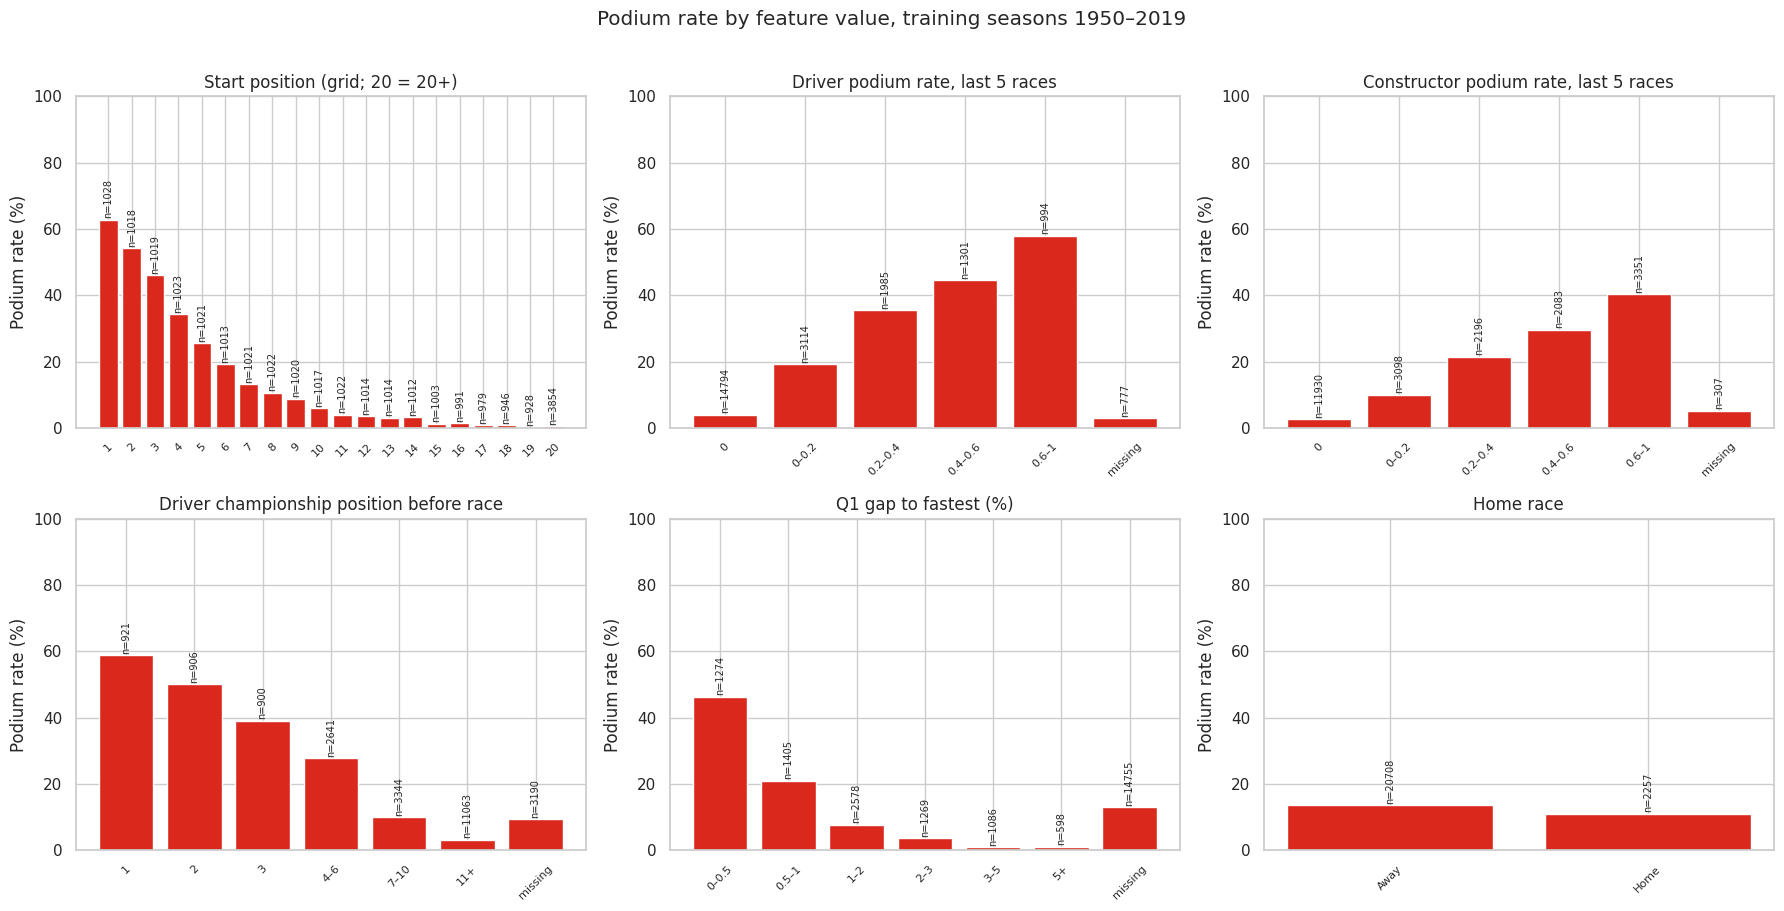

,feature,group,missing_pct,univariate_auc,direction,spearman_with_podium
4,qualifying_position,qualifying,63.671,0.905,lower → more podiums,-0.487
6,best_quali_gap_pct,qualifying,64.250,0.887,lower → more podiums,-0.466
0,start_position,grid,0.000,0.882,lower → more podiums,-0.451
1,start_position_pct,grid,0.000,0.878,lower → more podiums,-0.446
21,constructor_prior_points_share,standings,13.956,0.837,higher → more podiums,0.400
17,driver_prior_position,standings,13.886,0.837,lower → more podiums,-0.406
18,driver_prior_points_share,standings,13.886,0.831,higher → more podiums,0.406
5,q1_gap_pct,qualifying,64.250,0.830,lower → more podiums,-0.398
20,constructor_prior_position,standings,13.956,0.829,lower → more podiums,-0.391
14,constructor_podium_rate_last5,constructor_form,1.337,0.812,higher → more podiums,0.401


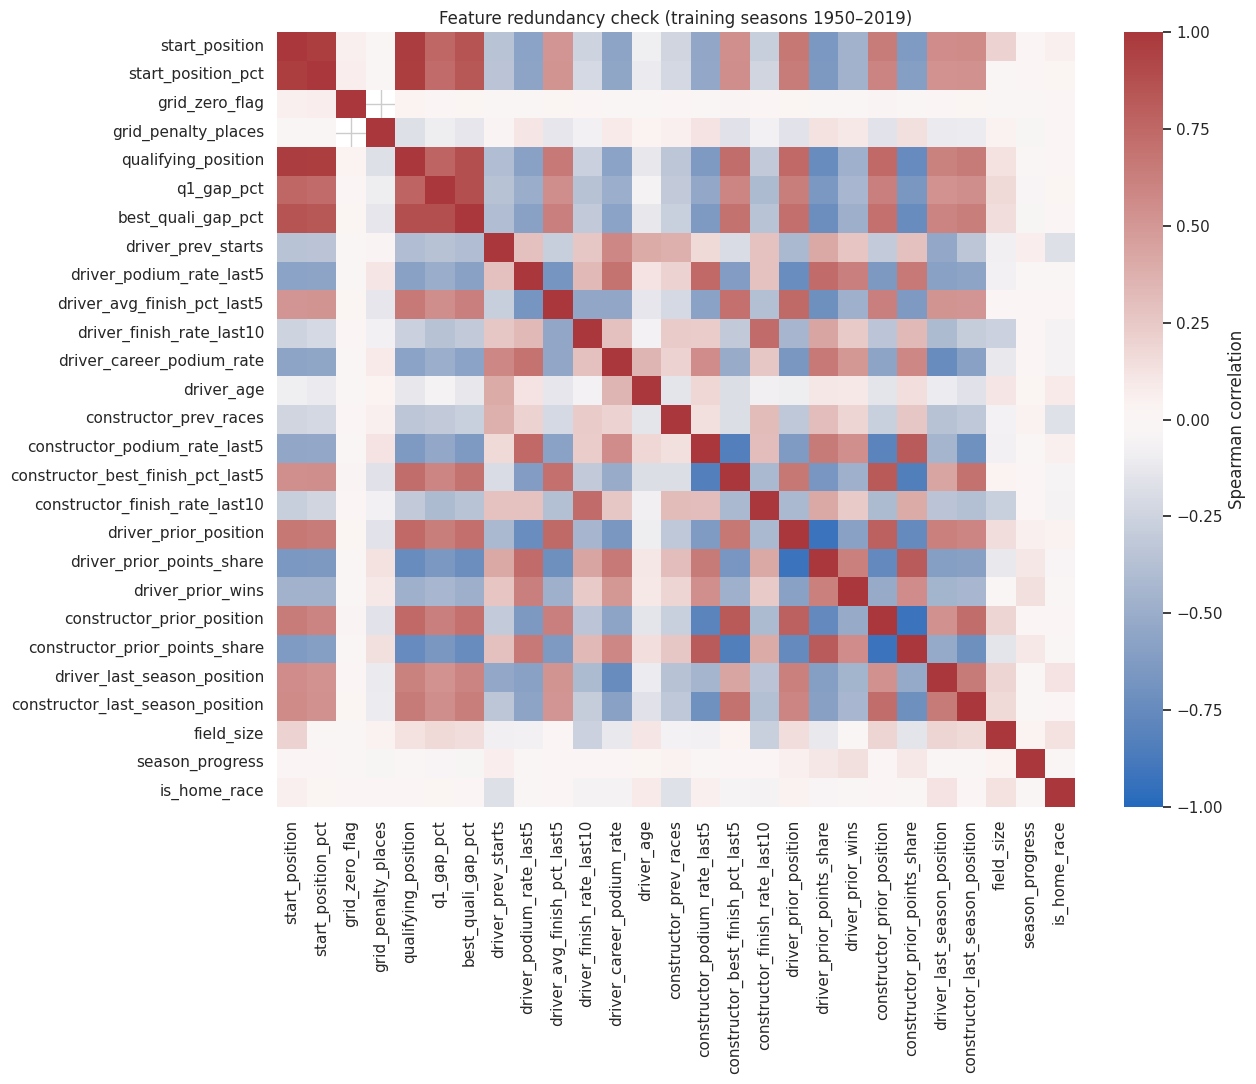

Highly correlated pairs (|rho| >= 0.85): [('start_position', 'start_position_pct', np.float64(0.97)), ('start_position', 'qualifying_position', np.float64(0.98)), ('start_position', 'best_quali_gap_pct', np.float64(0.86)), ('start_position_pct', 'qualifying_position', np.float64(0.96)), ('qualifying_position', 'best_quali_gap_pct', np.float64(0.88)), ('q1_gap_pct', 'best_quali_gap_pct', np.float64(0.88)), ('driver_prior_position', 'driver_prior_points_share', np.float64(-0.92)), ('constructor_prior_position', 'constructor_prior_points_share', np.float64(-0.92))]


In [32]:
from sklearn.metrics import roc_auc_score
SEED = 42
TRAIN_END_YEAR, VAL_END_YEAR = 2019, 2021   # F1 guide: train <= 2019, validation 2020–2021, test >= 2022
eda = feature_table[feature_table.year <= TRAIN_END_YEAR].copy()
print("EDA rows (training seasons 1950–2019 only):", len(eda), "| podium rate:", round(100 * eda.podium.mean(), 2), "%")

def podium_rate_by_bins(frame, column, bins, labels):
    binned = pd.cut(frame[column], bins=bins, labels=labels, include_lowest=True)
    binned = binned.cat.add_categories(["missing"]).fillna("missing")
    out = frame.groupby(binned, observed=True).podium.agg(["mean", "size"])
    out["mean"] *= 100
    return out

panels = [
    ("Start position (grid; 20 = 20+)", eda.assign(sp=eda.start_position.clip(upper=20)).groupby("sp").podium.agg(["mean", "size"]).assign(mean=lambda d: d["mean"] * 100)),
    ("Driver podium rate, last 5 races", podium_rate_by_bins(eda, "driver_podium_rate_last5", [0, 0.001, 0.2, 0.4, 0.6, 1], ["0", "0–0.2", "0.2–0.4", "0.4–0.6", "0.6–1"])),
    ("Constructor podium rate, last 5 races", podium_rate_by_bins(eda, "constructor_podium_rate_last5", [0, 0.001, 0.2, 0.4, 0.6, 1], ["0", "0–0.2", "0.2–0.4", "0.4–0.6", "0.6–1"])),
    ("Driver championship position before race", podium_rate_by_bins(eda, "driver_prior_position", [0, 1, 2, 3, 6, 10, 100], ["1", "2", "3", "4–6", "7–10", "11+"])),
    ("Q1 gap to fastest (%)", podium_rate_by_bins(eda, "q1_gap_pct", [0, 0.5, 1, 2, 3, 5, 100], ["0–0.5", "0.5–1", "1–2", "2–3", "3–5", "5+"])),
    ("Home race", eda.groupby(eda.is_home_race.map({0: "Away", 1: "Home"})).podium.agg(["mean", "size"]).assign(mean=lambda d: d["mean"] * 100)),
]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (title, data) in zip(axes.ravel(), panels):
    labels = [str(int(i)) if isinstance(i, float) else str(i) for i in data.index]
    ax.bar(labels, data["mean"], color="#da291c")
    for i, n in enumerate(data["size"]):
        ax.text(i, data["mean"].iloc[i] + 1, f"n={n}", ha="center", fontsize=7, rotation=90)
    ax.set(title=title, ylabel="Podium rate (%)", ylim=(0, max(100, data["mean"].max() + 15)))
    ax.tick_params(axis="x", rotation=45, labelsize=8)
plt.suptitle("Podium rate by feature value, training seasons 1950–2019", y=1.01)
plt.tight_layout(); plt.show()

screen = []
for f in NUMERIC_FEATURES:
    ok = eda[f].notna()
    auc = roc_auc_score(eda.podium[ok], eda.loc[ok, f]) if ok.sum() > 50 and eda.podium[ok].nunique() == 2 else np.nan
    screen.append({"feature": f, "group": FEATURE_TO_GROUP[f], "missing_pct": 100 * (~ok).mean(),
                   "univariate_auc": max(auc, 1 - auc) if pd.notna(auc) else np.nan,
                   "direction": "higher → more podiums" if pd.notna(auc) and auc >= 0.5 else "lower → more podiums",
                   "spearman_with_podium": eda[[f, "podium"]].corr(method="spearman").iloc[0, 1]})
screen = pd.DataFrame(screen).sort_values("univariate_auc", ascending=False)
display(screen.round(3))

corr = eda[NUMERIC_FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Spearman correlation"})
ax.set_title("Feature redundancy check (training seasons 1950–2019)")
plt.tight_layout(); plt.show()
redundant = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(NUMERIC_FEATURES) for b in NUMERIC_FEATURES[i + 1:] if abs(corr.loc[a, b]) >= 0.85]
print("Highly correlated pairs (|rho| >= 0.85):", redundant or "none")

**Feature decisions, supported by the EDA above**
- **Grid and qualifying** carry the strongest single signal; the podium rate falls steeply with start position. Start position and qualifying position are highly correlated. We keep both because they differ after penalties, and the Step 7 ablation and SHAP results show whether the model relies on the duplication.
- **Driver and constructor form** separate podium from non-podium rows much better than chance. Recent podium rate and finish percentage capture car and driver strength that a single grid slot does not.
- **Standings** (shifted to before the race) add season-level strength. Round-1 gaps are filled by last season's final position, with remaining missingness handled by train-fitted imputation and missing-value indicators.
- **Race context** is weak on its own. The home flag links the model to Q2, and field size normalises different eras.
- **Sprint results** are excluded because no training season has a sprint (Section 24). **Current-race outcomes** are never features (Sections 24 and 28).

## Step 5 — Split and preprocess the data

### 30. Train / validation / test split (season boundaries from the F1 guide)

The F1 guide (*Formula 1 for Newcomers*, glossary entry **Season**) gives the split boundaries: **train ≤ 2019, validation 2020–2021, test ≥ 2022**. We apply them to the **whole** dataset, all 25,100 eligible driver–race rows from 1950 to 2024:

| Split | Seasons | Purpose |
|---|---|---|
| Train | 1950–2019 | Fit imputers, encoders, scalers, and models |
| Validation | 2020–2021 | Choose preprocessing, hyperparameters, feature sets, and thresholds |
| Test | 2022–2024 | Unseen until every choice is fixed; scored once |

**Why this split is appropriate for this task:**
- **It matches the prediction setting.** A real prediction is made before a race using only the past. Training on earlier seasons and testing on later ones means no future season ever informs a prediction about an earlier one.
- **Whole seasons stay together**, so races from the same season, which share the same cars, drivers, and reliability, never appear in both training and evaluation.
- **The test seasons are a new technical era.** The 2022–2024 ground-effect rules (see the guide's era table) make the test an honest check of whether the model generalises to new regulations, not just to more of the same.
- **Validation is the two seasons just before the test**, so thresholds and hyperparameters are tuned on conditions close to the test period. The test set itself is never used for any choice.
- **All of history is used for training.** Qualifying data is missing before 1994 ("historical qualifying-coverage drift" in the brief). Those values are imputed with train-fitted medians and flagged with missing-value indicators, and Section 37 checks the effect of restricting training to 1994+.

**Limitation:** validation and test are much smaller than training (2 and 3 seasons), so their metrics carry more sampling noise. The race counts below show how large that noise could be.

,first_season,last_season,races,rows,podiums,podium_rate_pct,missing_qualifying_pct,share_of_rows_pct
split,,,,,,,,
train,1950,2019,1018,22965,3074,13.39,63.67,91.49
validation,2020,2021,39,779,117,15.02,0.13,3.10
test,2022,2024,68,1356,204,15.04,0.00,5.40


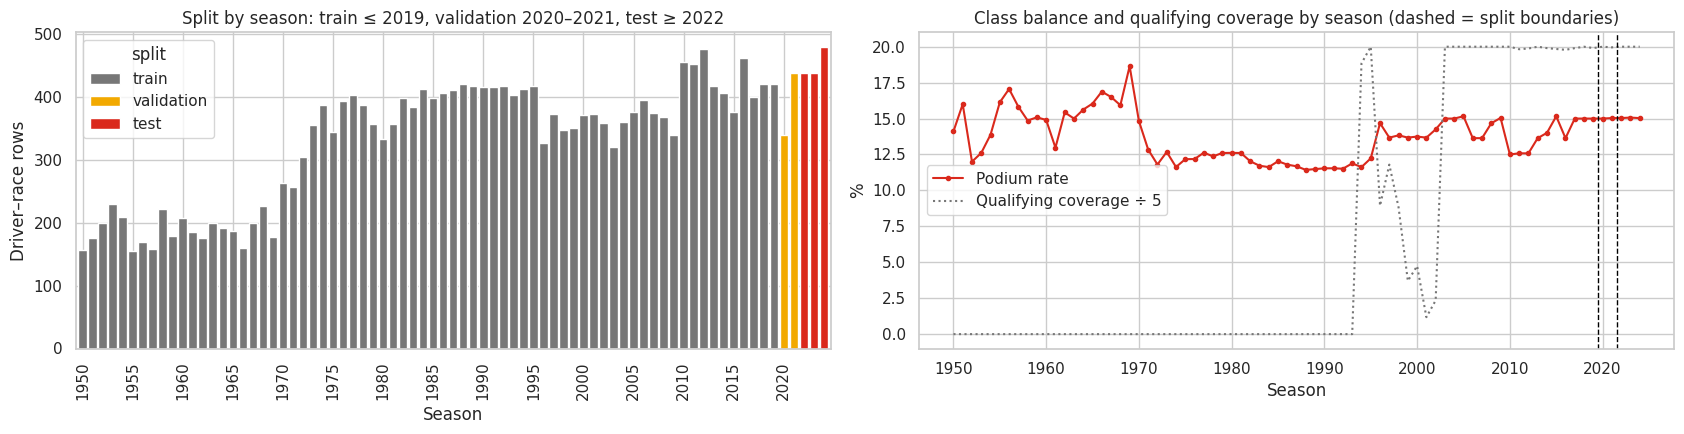

In [33]:
model_df = feature_table.copy()
model_df["split"] = np.select([model_df.year <= TRAIN_END_YEAR, model_df.year <= VAL_END_YEAR],
                              ["train", "validation"], default="test")
feature_table["split"] = model_df["split"]
train_df = model_df[model_df.split == "train"]
val_df = model_df[model_df.split == "validation"]
test_df = model_df[model_df.split == "test"]
assert set(train_df.raceId).isdisjoint(val_df.raceId) and set(val_df.raceId).isdisjoint(test_df.raceId)
assert train_df.date.max() < val_df.date.min() and val_df.date.max() < test_df.date.min()
assert len(train_df) + len(val_df) + len(test_df) == len(model_df) == 25_100

X_train, y_train = train_df[ALL_FEATURES], train_df.podium.astype(int).to_numpy()
X_val, y_val = val_df[ALL_FEATURES], val_df.podium.astype(int).to_numpy()
X_test, y_test = test_df[ALL_FEATURES], test_df.podium.astype(int).to_numpy()

split_summary = (model_df.groupby("split")
                 .agg(first_season=("year", "min"), last_season=("year", "max"), races=("raceId", "nunique"),
                      rows=("driverId", "size"), podiums=("podium", "sum"),
                      podium_rate_pct=("podium", lambda s: 100 * s.mean()),
                      missing_qualifying_pct=("qualifying_position", lambda s: 100 * s.isna().mean()))
                 .reindex(["train", "validation", "test"]))
split_summary["share_of_rows_pct"] = 100 * split_summary.rows / len(model_df)
display(split_summary.round(2))

per_season = model_df.groupby(["year", "split"]).size().unstack(fill_value=0).reindex(columns=["train", "validation", "test"])
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
per_season.plot(kind="bar", stacked=True, ax=axes[0], color=["#777777", "#f2a900", "#da291c"], width=.85)
axes[0].set(xlabel="Season", ylabel="Driver–race rows", title="Split by season: train ≤ 2019, validation 2020–2021, test ≥ 2022")
axes[0].set_xticks(range(0, len(per_season), 5), per_season.index[::5], rotation=90)
rate = model_df.groupby("year").podium.mean() * 100
quali_cov = model_df.groupby("year").qualifying_position.apply(lambda s: 100 * s.notna().mean())
axes[1].plot(rate.index, rate.values, marker=".", color="#da291c", label="Podium rate")
axes[1].plot(quali_cov.index, quali_cov.values / 5, color="#777777", linestyle=":", label="Qualifying coverage ÷ 5")
for boundary in [TRAIN_END_YEAR + 0.5, VAL_END_YEAR + 0.5]:
    axes[1].axvline(boundary, color="black", linestyle="--", linewidth=1)
axes[1].set(xlabel="Season", ylabel="%", title="Class balance and qualifying coverage by season (dashed = split boundaries)")
axes[1].legend()
plt.tight_layout(); plt.show()

### 31. Train-only preprocessing pipeline and how it changes the distributions

**Pipeline** (`ColumnTransformer` inside an sklearn `Pipeline`, so every statistic is learned from training rows only):
- **Numeric:** median imputation **with missing-value indicators**, then `StandardScaler`. The indicators preserve the information that a value was missing, such as no history or no qualifying time.
- **Categorical** (`quali_format`): most-frequent imputation, then one-hot encoding with `handle_unknown="ignore"`, so unseen categories at inference do not cause errors.

Below we show the learned statistics and compare selected features before and after transformation. Training rows end with mean 0 and standard deviation 1, while validation and test rows are transformed **with training statistics**, so their means are not exactly zero. Imputed values appear as a spike at the training median. This is the reference pipeline; Section 32 compares alternative orders, and the variant with the best validation score is used for every model from Step 6 onward.

Raw model features: 28 -> transformed columns: 49 (18 missing indicators, 4 one-hot columns)
Learned one-hot categories: [array(['knockout_2006_plus', 'none_pre1994', 'one_lap_2003_2005',
       'single_session_1994_2002'], dtype=object)]


,start_position,start_position_pct,grid_zero_flag,grid_penalty_places,qualifying_position,q1_gap_pct,best_quali_gap_pct,driver_prev_starts,driver_podium_rate_last5,driver_avg_finish_pct_last5,driver_finish_rate_last10,driver_career_podium_rate,driver_age,constructor_prev_races,constructor_podium_rate_last5,constructor_best_finish_pct_last5,constructor_finish_rate_last10,driver_prior_position,driver_prior_points_share,driver_prior_wins,constructor_prior_position,constructor_prior_points_share,driver_last_season_position,constructor_last_season_position,field_size,season_progress,is_home_race
train_median_used_for_imputation,12.0,0.52,0.0,0.0,11.0,1.502,1.966,40.0,0.0,0.507,0.6,0.049,29.604,90.0,0.0,0.342,0.6,12.0,0.079,0.0,6.0,0.139,12.0,6.0,23.0,0.5,0.0


,train_missing_before,train_mean_before,train_std_before,train_missing_after,train_mean_after,train_std_after,val_mean_after,test_mean_after
start_position,0,12.004,6.907,0,0.0,1.0,-0.211,-0.216
q1_gap_pct,14755,2.025,1.991,0,0.0,1.0,-0.233,-0.516
driver_podium_rate_last5,777,0.137,0.234,0,-0.0,1.0,0.075,0.081
constructor_prior_points_share,3205,0.294,0.336,0,0.0,1.0,0.109,0.086
driver_age,0,30.113,5.219,0,0.0,1.0,-0.428,-0.248


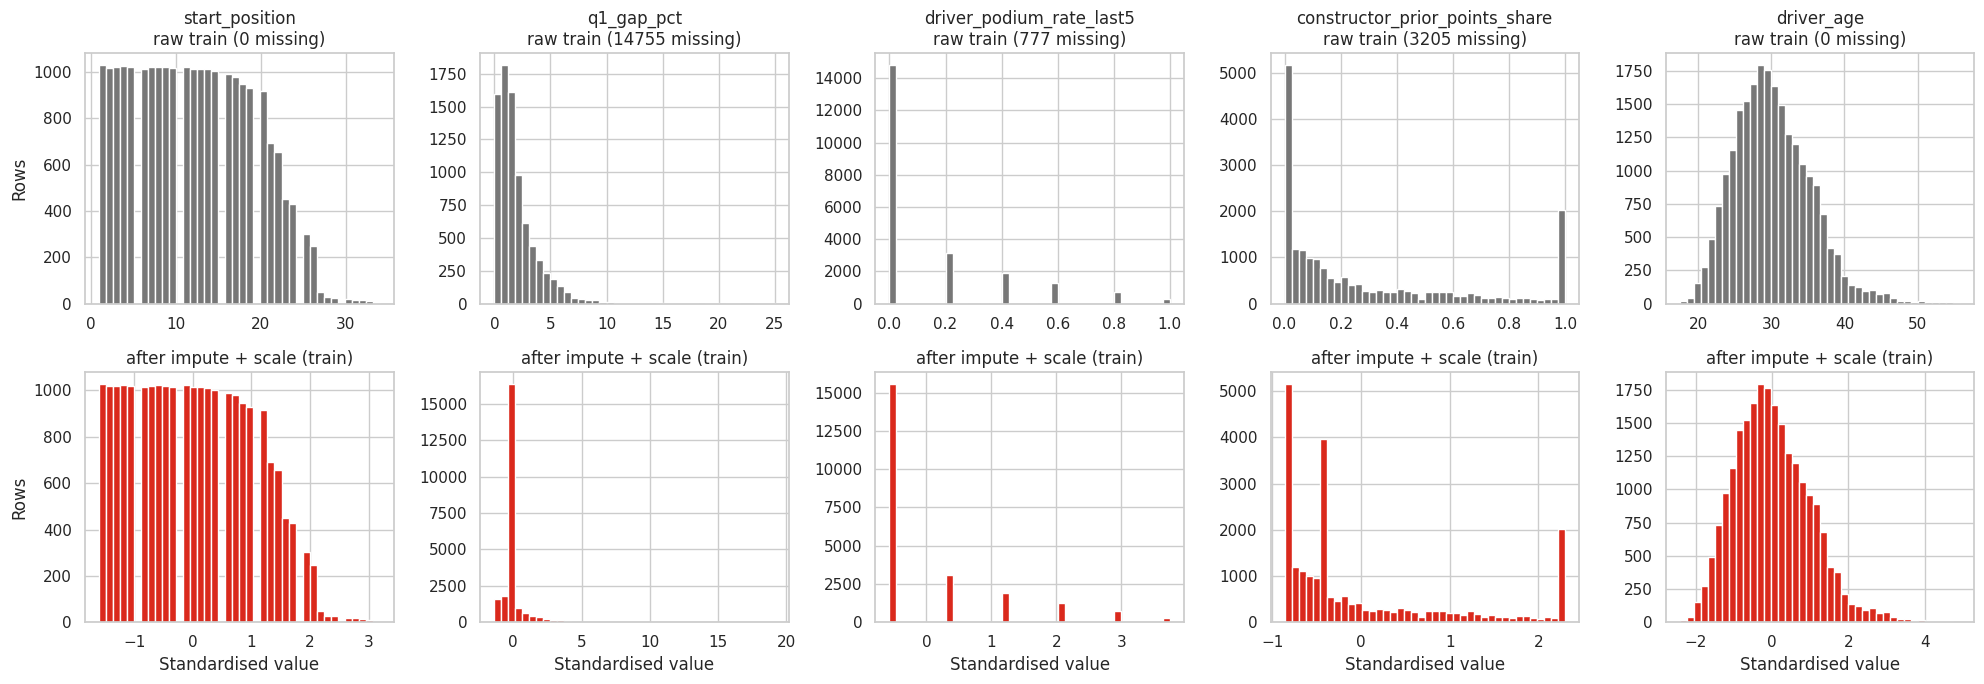

In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (average_precision_score, f1_score, precision_score, recall_score, brier_score_loss,
                             precision_recall_curve, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

def make_preprocessor(numeric, categorical, add_indicator=True, order="impute_then_scale"):
    if order == "impute_then_scale":
        numeric_steps = [("impute", SimpleImputer(strategy="median", add_indicator=add_indicator)), ("scale", StandardScaler())]
    else:
        numeric_steps = [("scale", StandardScaler()), ("impute", SimpleImputer(strategy="median", add_indicator=add_indicator))]
    transformers = [("num", Pipeline(numeric_steps), list(numeric))]
    if categorical:
        transformers.append(("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                              ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
                             list(categorical)))
    return ColumnTransformer(transformers, verbose_feature_names_out=False)

reference_prep = make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES).fit(X_train)
out_names = reference_prep.get_feature_names_out()
to_frame = lambda X: pd.DataFrame(reference_prep.transform(X), columns=out_names, index=X.index)
Xt_train, Xt_val, Xt_test = to_frame(X_train), to_frame(X_val), to_frame(X_test)
print("Raw model features:", len(ALL_FEATURES), "-> transformed columns:", len(out_names),
      f"({sum(n.startswith('missingindicator') for n in out_names)} missing indicators, "
      f"{len(reference_prep.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out())} one-hot columns)")
imputer = reference_prep.named_transformers_["num"].named_steps["impute"]
print("Learned one-hot categories:", reference_prep.named_transformers_["cat"].named_steps["onehot"].categories_)
display(pd.DataFrame({"train_median_used_for_imputation": imputer.statistics_}, index=NUMERIC_FEATURES).round(3).T)

SHOW = ["start_position", "q1_gap_pct", "driver_podium_rate_last5", "constructor_prior_points_share", "driver_age"]
before_after = pd.DataFrame({
    "train_missing_before": X_train[SHOW].isna().sum(), "train_mean_before": X_train[SHOW].mean(),
    "train_std_before": X_train[SHOW].std(), "train_missing_after": Xt_train[SHOW].isna().sum(),
    "train_mean_after": Xt_train[SHOW].mean(), "train_std_after": Xt_train[SHOW].std(),
    "val_mean_after": Xt_val[SHOW].mean(), "test_mean_after": Xt_test[SHOW].mean()})
display(before_after.round(3))
assert Xt_train.isna().sum().sum() == 0 and Xt_val.isna().sum().sum() == 0 and Xt_test.isna().sum().sum() == 0

fig, axes = plt.subplots(2, len(SHOW), figsize=(4 * len(SHOW), 7))
for j, f in enumerate(SHOW):
    axes[0, j].hist(X_train[f].dropna(), bins=40, color="#777777")
    axes[0, j].set(title=f"{f}\nraw train ({int(X_train[f].isna().sum())} missing)", ylabel="Rows" if j == 0 else "")
    axes[1, j].hist(Xt_train[f], bins=40, color="#da291c")
    axes[1, j].set(title="after impute + scale (train)", xlabel="Standardised value", ylabel="Rows" if j == 0 else "")
plt.tight_layout(); plt.show()

### 32. Preprocessing-order experiments

The brief asks for at least two preprocessing-order experiments, and the checklist asks for each attempt in **its own notebook cell**, so the before/after comparison is visible. Every variant uses the same train and validation rows, and the same two scaling-sensitive models (Logistic Regression and a small neural network). Any difference therefore comes from preprocessing alone. Variant A is the reference; each later cell compares itself with A.

| Variant | What changes |
|---|---|
| **A. Reference** | Split → fit on train → impute (median + indicators) → scale |
| **B. Leaky order** | Fit the imputer and scaler on **all rows before splitting**, so validation and test statistics leak into training |
| **C. Scale → impute** | Scale first (NaNs ignored), then impute medians in scaled space |
| **D. No missing indicators** | Same as A but without indicator columns |

We report validation PR-AUC (the primary metric, see Step 6), ROC-AUC, and Brier score. Variant B is **not eligible for selection** however it scores, because it uses information unavailable at training time. It is run only to measure the leakage.

In [35]:
X_all_years = pd.concat([X_train, X_val, X_test])
experiment_models = {
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=3000),
    "MLP (32)": MLPClassifier(hidden_layer_sizes=(32,), alpha=1e-3, early_stopping=True, max_iter=600, random_state=SEED),
}
experiment_rows, fitted_preps = [], {}

def run_preprocessing_variant(variant, prep, fit_rows):
    """Fit `prep` on `fit_rows`, train both experiment models on the training rows, score validation."""
    prep = prep.fit(fit_rows)
    fitted_preps[variant] = prep
    Xtr, Xv = prep.transform(X_train), prep.transform(X_val)
    rows = []
    for model_name, model in experiment_models.items():
        p_val = clone(model).fit(Xtr, y_train).predict_proba(Xv)[:, 1]
        rows.append({"variant": variant, "model": model_name, "transformed_columns": Xtr.shape[1],
                     "val_PR-AUC": average_precision_score(y_val, p_val),
                     "val_ROC-AUC": roc_auc_score(y_val, p_val), "val_Brier": brier_score_loss(y_val, p_val)})
    experiment_rows.extend(rows)
    result = pd.DataFrame(rows)
    if variant != VARIANT_A:
        reference = pd.DataFrame([r for r in experiment_rows if r["variant"] == VARIANT_A]).set_index("model")
        result["delta_PR-AUC_vs_A"] = result["val_PR-AUC"].to_numpy() - reference.loc[result.model, "val_PR-AUC"].to_numpy()
    display(result.round(4))
    return prep

VARIANT_A = "A. Reference (fit on train, impute→scale, indicators)"
VARIANT_B = "B. Leaky: fit preprocessing on all years before split"
VARIANT_C = "C. Scale→impute (fit on train)"
VARIANT_D = "D. No missing indicators (fit on train)"

#### 32a. Variant A — reference order (split → fit on train → impute → scale)

In [36]:
prep_a = run_preprocessing_variant(VARIANT_A, make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES), X_train)

,variant,model,transformed_columns,val_PR-AUC,val_ROC-AUC,val_Brier
0,"A. Reference (fit on train, impute→scale, indi...",Logistic Regression,49,0.7437,0.9327,0.0664
1,"A. Reference (fit on train, impute→scale, indi...",MLP (32),49,0.7044,0.9291,0.0680


#### 32b. Variant B — leaky order (fit preprocessing on all years before splitting)

Besides the scores, we show how far the learned medians and means move when validation and test seasons are included in the fit.

In [37]:
prep_b = run_preprocessing_variant(VARIANT_B, make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES), X_all_years)
n_num = len(NUMERIC_FEATURES)
stat_shift = pd.DataFrame({
    "train_only_median": prep_a.named_transformers_["num"].named_steps["impute"].statistics_,
    "all_years_median": prep_b.named_transformers_["num"].named_steps["impute"].statistics_,
    "train_only_mean": prep_a.named_transformers_["num"].named_steps["scale"].mean_[:n_num],
    "all_years_mean": prep_b.named_transformers_["num"].named_steps["scale"].mean_[:n_num]}, index=NUMERIC_FEATURES)
stat_shift["mean_shift"] = stat_shift.all_years_mean - stat_shift.train_only_mean
print("How the leaky order moves the learned statistics (largest shifts):")
display(stat_shift.reindex(stat_shift.mean_shift.abs().sort_values(ascending=False).index).head(8).round(3))

,variant,model,transformed_columns,val_PR-AUC,val_ROC-AUC,val_Brier,delta_PR-AUC_vs_A
0,B. Leaky: fit preprocessing on all years befor...,Logistic Regression,49,0.7436,0.9327,0.0664,-0.0001
1,B. Leaky: fit preprocessing on all years befor...,MLP (32),49,0.7188,0.9300,0.0674,0.0145


How the leaky order moves the learned statistics (largest shifts):


,train_only_median,all_years_median,train_only_mean,all_years_mean,mean_shift
constructor_prev_races,90.000,98.000,170.835,189.053,18.218
driver_prev_starts,40.000,44.000,60.732,67.225,6.493
driver_last_season_position,12.000,11.000,13.904,13.404,-0.500
field_size,23.000,22.000,23.056,22.792,-0.264
driver_prior_position,12.000,12.000,12.935,12.745,-0.189
driver_age,29.604,29.429,30.113,29.974,-0.139
q1_gap_pct,1.502,1.344,1.689,1.553,-0.136
start_position,12.000,12.000,12.004,11.878,-0.126


#### 32c. Variant C — scale first, then impute

We show that imputing *after* scaling leaves features with missing values off-centre: their training mean is no longer 0 and their standard deviation shrinks.

In [38]:
prep_c = run_preprocessing_variant(VARIANT_C, make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES, order="scale_then_impute"), X_train)
scaled_then_imputed = pd.DataFrame(prep_c.transform(X_train)[:, :len(NUMERIC_FEATURES)], columns=NUMERIC_FEATURES)
print("Scale→impute: train mean / std after transform for features that had missing values")
display(pd.DataFrame({"mean": scaled_then_imputed.mean(), "std": scaled_then_imputed.std(),
                      "train_missing_pct": 100 * X_train[NUMERIC_FEATURES].isna().mean()})
        .query("train_missing_pct > 0").round(3))

,variant,model,transformed_columns,val_PR-AUC,val_ROC-AUC,val_Brier,delta_PR-AUC_vs_A
0,C. Scale→impute (fit on train),Logistic Regression,49,0.7433,0.9324,0.0665,-0.0004
1,C. Scale→impute (fit on train),MLP (32),49,0.7191,0.9279,0.0677,0.0148


Scale→impute: train mean / std after transform for features that had missing values


,mean,std,train_missing_pct
grid_penalty_places,0.005,0.602,63.754
qualifying_position,-0.036,0.603,63.671
q1_gap_pct,-0.169,0.611,64.250
best_quali_gap_pct,-0.139,0.607,64.250
driver_podium_rate_last5,-0.020,0.989,3.383
driver_avg_finish_pct_last5,0.002,0.983,3.383
driver_finish_rate_last10,-0.001,0.983,3.383
driver_career_podium_rate,-0.016,0.986,3.383
constructor_podium_rate_last5,-0.010,0.997,1.337
constructor_best_finish_pct_last5,-0.000,0.993,1.337


#### 32d. Variant D — reference order without missing-value indicators

In [39]:
prep_d = run_preprocessing_variant(VARIANT_D, make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES, add_indicator=False), X_train)

,variant,model,transformed_columns,val_PR-AUC,val_ROC-AUC,val_Brier,delta_PR-AUC_vs_A
0,D. No missing indicators (fit on train),Logistic Regression,31,0.7426,0.9301,0.0666,-0.0011
1,D. No missing indicators (fit on train),MLP (32),31,0.7400,0.9295,0.0670,0.0356


#### 32e. Comparison of all preprocessing variants and the decision

,variant,model,transformed_columns,val_PR-AUC,val_ROC-AUC,val_Brier
0,"A. Reference (fit on train, impute→scale, indi...",Logistic Regression,49,0.7437,0.9327,0.0664
1,"A. Reference (fit on train, impute→scale, indi...",MLP (32),49,0.7044,0.9291,0.0680
2,B. Leaky: fit preprocessing on all years befor...,Logistic Regression,49,0.7436,0.9327,0.0664
3,B. Leaky: fit preprocessing on all years befor...,MLP (32),49,0.7188,0.9300,0.0674
4,C. Scale→impute (fit on train),Logistic Regression,49,0.7433,0.9324,0.0665
5,C. Scale→impute (fit on train),MLP (32),49,0.7191,0.9279,0.0677
6,D. No missing indicators (fit on train),Logistic Regression,31,0.7426,0.9301,0.0666
7,D. No missing indicators (fit on train),MLP (32),31,0.7400,0.9295,0.0670


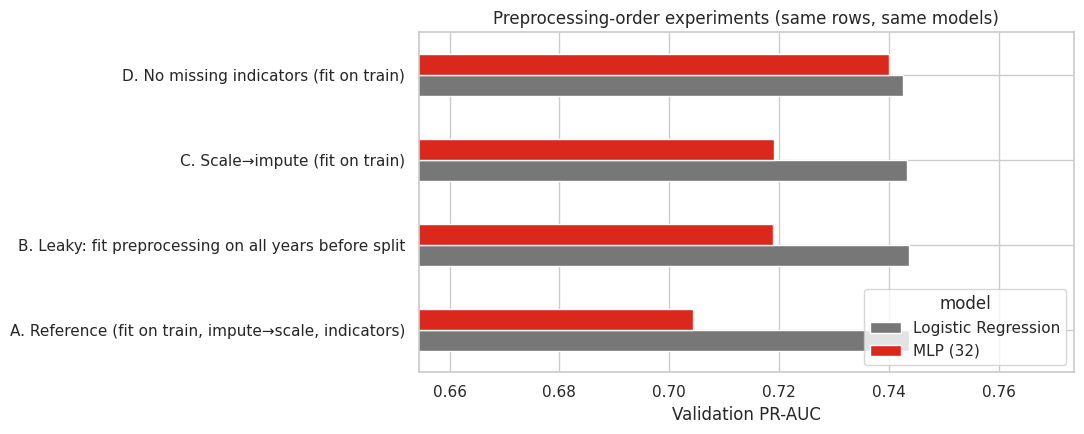

,mean validation PR-AUC (LR + MLP)
variant,
D. No missing indicators (fit on train),0.7413
C. Scale→impute (fit on train),0.7312
"A. Reference (fit on train, impute→scale, indicators)",0.7240


**Preprocessing decision (made on validation, as the brief requires):** **D. No missing indicators (fit on train)** has the highest mean validation PR-AUC across the two test models (0.7413, vs 0.7240 for the reference A). Every model from Step 6 onward therefore uses it. Why it is reasonable: dropping the indicators removes 18 columns that mostly encode *era* (most missing values are pre-1994 rows without qualifying data). The neural network otherwise learns era-specific missingness patterns that do not help on the 2020–2021 validation seasons, where qualifying data is complete. Missing values are still median-imputed, and `quali_format` still tells the model which era a row comes from. Variant B is excluded however it scores: it shifts the learned statistics by the amounts shown in 32b, which means information from the validation and test seasons (2020–2024) enters training, so any gain it shows is leakage, not real skill.

In [40]:
experiment_results = pd.DataFrame(experiment_rows)
display(experiment_results.round(4))
pivot = experiment_results.pivot(index="variant", columns="model", values="val_PR-AUC")
ax = pivot.plot(kind="barh", figsize=(11, 4.5), color=["#777777", "#da291c"])
ax.set(xlabel="Validation PR-AUC", ylabel="", title="Preprocessing-order experiments (same rows, same models)",
       xlim=(max(0, pivot.min().min() - 0.05), min(1, pivot.max().max() + 0.03)))
plt.tight_layout(); plt.show()

VARIANT_SETTINGS = {VARIANT_A: dict(order="impute_then_scale", add_indicator=True),
                    VARIANT_C: dict(order="scale_then_impute", add_indicator=True),
                    VARIANT_D: dict(order="impute_then_scale", add_indicator=False)}
eligible_variants = experiment_results[experiment_results.variant != VARIANT_B]   # B leaks, never eligible
variant_means = eligible_variants.groupby("variant")["val_PR-AUC"].mean().sort_values(ascending=False)
display(variant_means.rename("mean validation PR-AUC (LR + MLP)").to_frame().round(4))
CHOSEN_VARIANT = variant_means.index[0]
PREPROCESS_CHOICE = VARIANT_SETTINGS[CHOSEN_VARIANT]

def make_model_preprocessor(numeric, categorical):
    """Preprocessing used by every model from Step 6 on: the variant chosen on validation in 32e."""
    return make_preprocessor(numeric, categorical, **PREPROCESS_CHOICE)

why = {
    VARIANT_A: "imputing before scaling gives exactly centred features, and the indicators keep the information that a value was missing.",
    VARIANT_C: "it scored best here, although scaling before imputing leaves imputed features off-centre (32c).",
    VARIANT_D: ("dropping the indicators removes 18 columns that mostly encode *era* (most missing values are pre-1994 rows "
                "without qualifying data). The neural network otherwise learns era-specific missingness patterns that do not "
                "help on the 2020–2021 validation seasons, where qualifying data is complete. Missing values are still "
                "median-imputed, and `quali_format` still tells the model which era a row comes from."),
}[CHOSEN_VARIANT]
display(Markdown(f"""**Preprocessing decision (made on validation, as the brief requires):** **{CHOSEN_VARIANT}** has the highest mean validation PR-AUC across the two test models ({variant_means.iloc[0]:.4f}, vs {variant_means.get(VARIANT_A, float('nan')):.4f} for the reference A). Every model from Step 6 onward therefore uses it. Why it is reasonable: {why} Variant B is excluded however it scores: it shifts the learned statistics by the amounts shown in 32b, which means information from the validation and test seasons (2020–2024) enters training, so any gain it shows is leakage, not real skill."""))

## Step 6 — Train and compare models

### 33. Metrics, threshold policy, and the baseline

**The metrics required by the brief (Section 4)** are ROC-AUC, PR-AUC, and F1. The deliverables ask for "all five metrics", so we add Precision and Recall, the two parts of F1. All five are **computed for every model on the training, validation, and unseen test sets**, as the brief requires:

| Metric | Role | Why |
|---|---|---|
| **PR-AUC (average precision)** | **Primary** | Podiums are rare (about 13.5% of rows). As the brief says, PR-AUC is more informative than ROC-AUC when the positive class is rare: it scores how well true podium finishers are ranked above everyone else, and the many easy non-podium rows cannot inflate it. |
| **ROC-AUC** | **Secondary** | Overall separation of the two classes, independent of the threshold. It is easy to compare across splits, but optimistic when classes are imbalanced. |
| **F1** | Operating point | Balances false positives against false negatives at the chosen threshold. |
| **Precision** | Operating point | Of the predicted podiums, the share that were real. |
| **Recall** | Operating point | Of the real podiums, the share the model caught. |

**Threshold policy:** As the brief requires, thresholds are chosen using validation data only (maximising F1), then applied unchanged to the test set. The test set is never used for any choice.

**Baseline (the checklist requires a statistical ML model or a shallow FFNN as the baseline):** a **Logistic Regression with default settings** (C = 1, no class weighting, no tuning) on the full feature set and the Step 5 preprocessing. It is the simplest reasonable statistical model, and every tuned model in Section 34 must beat it to justify its extra complexity.

**Two extra reference points** (kept for context, not as the baseline): the *class prior*, which always predicts the training podium rate, so its PR-AUC equals the base rate; and the *grid-slot podium rate*, the smoothed training podium rate of each starting slot, which shows how much a model adds beyond the grid alone.

**Supplementary (not among the five):** Brier score for probability calibration, and the race-level top-3 hit rate — take the three highest probabilities in each race and record how many finished on the podium.

In [41]:
import time
FIVE_METRICS = ["ROC-AUC", "PR-AUC", "F1", "Precision", "Recall"]
BASELINE_NAME = "Baseline: Logistic Regression (default)"

def best_f1_threshold(y_true, proba):
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    if len(thresholds) == 0:
        return 0.5
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    return float(thresholds[int(np.nanargmax(f1))])

def five_metrics(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, proba), "PR-AUC": average_precision_score(y_true, proba),
            "F1": f1_score(y_true, pred, zero_division=0), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0)}

def race_top3_hit_rate(meta, proba):
    d = meta[["raceId", "podium"]].copy()
    d["p"] = proba
    d["rank"] = d.groupby("raceId").p.rank(ascending=False, method="first")
    return float(d.loc[d["rank"] <= 3, "podium"].mean())

class GridRateBaseline(ClassifierMixin, BaseEstimator):
    """Smoothed training podium rate per starting slot (slots above max_slot are pooled)."""
    def __init__(self, max_slot=20, alpha=5.0):
        self.max_slot = max_slot
        self.alpha = alpha
    def _slots(self, X):
        return np.clip(np.asarray(X["start_position"], dtype=float), 1, self.max_slot)
    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        self.prior_ = y.mean()
        stats_ = pd.DataFrame({"slot": self._slots(X), "y": y}).groupby("slot").y.agg(["sum", "count"])
        self.rates_ = ((stats_["sum"] + self.alpha * self.prior_) / (stats_["count"] + self.alpha)).to_dict()
        self.classes_ = np.array([0, 1])
        return self
    def predict_proba(self, X):
        p = np.array([self.rates_.get(s, self.prior_) for s in np.nan_to_num(self._slots(X), nan=-1.0)])
        return np.column_stack([1 - p, p])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

final_models = {}
def register(name, fitted, kind, params=None):
    """Store train/validation/test probabilities; the threshold is chosen on validation only."""
    p_train, p_val, p_test = (fitted.predict_proba(X)[:, 1] for X in (X_train, X_val, X_test))
    final_models[name] = {"model": fitted, "kind": kind, "params": params or {}, "p_train": p_train,
                          "p_val": p_val, "p_test": p_test, "threshold": best_f1_threshold(y_val, p_val)}

baseline_pipe = Pipeline([("prep", make_model_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES)),
                          ("model", LogisticRegression(max_iter=3000))]).fit(X_train, y_train)
register(BASELINE_NAME, baseline_pipe, "baseline")
register("Reference: class prior", DummyClassifier(strategy="prior").fit(X_train, y_train), "reference")
grid_baseline = GridRateBaseline().fit(X_train, y_train)
register("Reference: grid-slot podium rate", grid_baseline, "reference")
print("Grid-slot reference: learned podium probability by starting slot (training seasons)")
display(pd.Series(grid_baseline.rates_, name="p_podium").rename_axis("start slot").to_frame().T.round(3))
display(pd.DataFrame([{"model": name, "split": split, **five_metrics(y, m[key], m["threshold"])}
                      for name, m in final_models.items()
                      for split, y, key in [("train", y_train, "p_train"), ("validation", y_val, "p_val")]]).round(3))

Grid-slot reference: learned podium probability by starting slot (training seasons)


start slot,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0
p_podium,0.626,0.54,0.459,0.341,0.254,0.191,0.131,0.107,0.088,0.059,0.041,0.037,0.031,0.032,0.014,0.016,0.01,0.008,0.003,0.006


,model,split,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Baseline: Logistic Regression (default),train,0.901,0.573,0.550,0.582,0.521
1,Baseline: Logistic Regression (default),validation,0.930,0.743,0.704,0.707,0.701
2,Reference: class prior,train,0.500,0.134,0.236,0.134,1.000
3,Reference: class prior,validation,0.500,0.150,0.261,0.150,1.000
4,Reference: grid-slot podium rate,train,0.882,0.496,0.543,0.544,0.542
5,Reference: grid-slot podium rate,validation,0.909,0.638,0.692,0.692,0.692


### 34. Modeling attempts — one cell per model family

The brief requires **at least two different statistical ML models and a shallow neural network, trained on the same modeling table (same rows, same feature set)**. The checklist asks for at least three distinct modeling attempts, each in its own notebook cell, with how the model works and its limitations. Every family below uses the same training rows, the same `ALL_FEATURES`, and the same train-fitted preprocessing pipeline from Step 5.

**Tuning procedure (identical for all families):** each hyperparameter configuration is fitted on the training seasons and scored on validation. The configuration with the best **validation PR-AUC** is kept. Every attempted configuration is logged and shown, along with its difference from the baseline. No model is refitted on train + validation, so each validation-chosen threshold belongs to exactly the model it was tuned for.

In [42]:
tuning_rows, best_by_family = [], {}
baseline_val_pr = average_precision_score(y_val, final_models[BASELINE_NAME]["p_val"])

def tune_family(family, estimator, grid):
    """Fit every configuration on train, score on validation, keep the best by validation PR-AUC."""
    family_rows = []
    for params in ParameterGrid(grid):
        start = time.perf_counter()
        pipe = Pipeline([("prep", make_model_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES)),
                         ("model", clone(estimator).set_params(**params))]).fit(X_train, y_train)
        p_train, p_val = pipe.predict_proba(X_train)[:, 1], pipe.predict_proba(X_val)[:, 1]
        row = {"family": family, "params": params,
               "train_PR-AUC": average_precision_score(y_train, p_train),
               "val_PR-AUC": average_precision_score(y_val, p_val), "val_ROC-AUC": roc_auc_score(y_val, p_val),
               "val_Brier": brier_score_loss(y_val, p_val), "fit_seconds": time.perf_counter() - start}
        family_rows.append(row)
        if family not in best_by_family or row["val_PR-AUC"] > best_by_family[family]["val_PR-AUC"]:
            best_by_family[family] = {**row, "pipe": pipe}
    tuning_rows.extend(family_rows)
    best = best_by_family[family]
    register(family, best["pipe"], "model", best["params"])
    log = pd.DataFrame(family_rows).assign(params=lambda d: d.params.astype(str)).sort_values("val_PR-AUC", ascending=False)
    log["val_PR-AUC_vs_baseline"] = log["val_PR-AUC"] - baseline_val_pr
    print(f"{family}: {len(log)} configurations tried; selected {best['params']}")
    display(log.round(4))
    m = final_models[family]
    display(pd.DataFrame([{"split": split, **five_metrics(y, m[key], m["threshold"])}
                          for split, y, key in [("train", y_train, "p_train"), ("validation", y_val, "p_val")]]).round(3))
    return best["pipe"]

#### 34a. Attempt 1 — Logistic Regression (statistical ML model)

**How it works:** it learns one weight per input (scaled features, missing indicators, one-hot columns) and passes the weighted sum through a sigmoid to produce a podium probability. Training maximises the likelihood of the observed podiums with L2 regularisation; `C` controls its strength, where a smaller C means stronger shrinkage. `class_weight="balanced"` up-weights the rare podium class.

**Limitations:** the decision boundary is linear in the inputs. It cannot model interactions, such as front-row starts mattering more for a strong team, unless they are engineered by hand. It also assumes a monotone, roughly linear effect of each scaled feature on the log-odds.

**Grid:** `C` ∈ {0.01, 0.1, 1, 10} × class weight ∈ {none, balanced}.

In [43]:
lr_pipe = tune_family("Logistic Regression", LogisticRegression(max_iter=3000),
            {"C": [0.01, 0.1, 1.0, 10.0], "class_weight": [None, "balanced"]})

Logistic Regression: 8 configurations tried; selected {'C': 10.0, 'class_weight': None}


,family,params,train_PR-AUC,val_PR-AUC,val_ROC-AUC,val_Brier,fit_seconds,val_PR-AUC_vs_baseline
6,Logistic Regression,"{'C': 10.0, 'class_weight': None}",0.5727,0.7428,0.9301,0.0666,0.4647,0.0002
4,Logistic Regression,"{'C': 1.0, 'class_weight': None}",0.5727,0.7426,0.9301,0.0666,0.5090,0.0000
7,Logistic Regression,"{'C': 10.0, 'class_weight': 'balanced'}",0.5653,0.7414,0.9295,0.1079,0.4873,-0.0012
5,Logistic Regression,"{'C': 1.0, 'class_weight': 'balanced'}",0.5653,0.7413,0.9295,0.1079,0.4269,-0.0013
2,Logistic Regression,"{'C': 0.1, 'class_weight': None}",0.5728,0.7407,0.9301,0.0666,0.7708,-0.0019
3,Logistic Regression,"{'C': 0.1, 'class_weight': 'balanced'}",0.5653,0.7393,0.9295,0.1080,0.6344,-0.0033
0,Logistic Regression,"{'C': 0.01, 'class_weight': None}",0.5720,0.7359,0.9294,0.0668,0.5011,-0.0067
1,Logistic Regression,"{'C': 0.01, 'class_weight': 'balanced'}",0.5658,0.7343,0.9287,0.1089,0.5709,-0.0083


,split,ROC-AUC,PR-AUC,F1,Precision,Recall
0,train,0.901,0.573,0.550,0.582,0.521
1,validation,0.930,0.743,0.704,0.707,0.701


#### 34b. Attempt 2 — Random Forest (statistical ML model)

**How it works:** it trains many decision trees, each on a bootstrap sample of the training rows and a random subset of features at each split, and averages their predicted probabilities. Trees capture non-linear effects and interactions automatically, and averaging reduces variance.

**Limitations:** probabilities are often poorly calibrated. Deep trees can memorise the training seasons (watch the train vs validation gap). Trees cannot extrapolate beyond values seen in training, and the model is harder to interpret than a linear one.

**Grid:** max depth ∈ {6, 10, unlimited} × min samples per leaf ∈ {5, 20} × class weight ∈ {none, balanced subsample}, with 300 trees.

In [44]:
rf_pipe = tune_family("Random Forest", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
            {"max_depth": [6, 10, None], "min_samples_leaf": [5, 20], "class_weight": [None, "balanced_subsample"]})

Random Forest: 12 configurations tried; selected {'class_weight': 'balanced_subsample', 'max_depth': 10, 'min_samples_leaf': 20}


,family,params,train_PR-AUC,val_PR-AUC,val_ROC-AUC,val_Brier,fit_seconds,val_PR-AUC_vs_baseline
9,Random Forest,"{'class_weight': 'balanced_subsample', 'max_de...",0.6751,0.7376,0.9326,0.0931,5.6875,-0.0050
11,Random Forest,"{'class_weight': 'balanced_subsample', 'max_de...",0.7023,0.7365,0.9328,0.0909,6.1744,-0.0061
1,Random Forest,"{'class_weight': None, 'max_depth': 6, 'min_sa...",0.6203,0.7343,0.9312,0.0666,3.3774,-0.0083
5,Random Forest,"{'class_weight': None, 'max_depth': None, 'min...",0.7053,0.7341,0.9321,0.0661,5.4380,-0.0085
3,Random Forest,"{'class_weight': None, 'max_depth': 10, 'min_s...",0.6858,0.7335,0.9326,0.0657,4.6671,-0.0091
7,Random Forest,"{'class_weight': 'balanced_subsample', 'max_de...",0.6077,0.7330,0.9306,0.1100,4.5864,-0.0096
0,Random Forest,"{'class_weight': None, 'max_depth': 6, 'min_sa...",0.6285,0.7317,0.9308,0.0670,3.4286,-0.0109
10,Random Forest,"{'class_weight': 'balanced_subsample', 'max_de...",0.9044,0.7297,0.9307,0.0722,7.0508,-0.0129
6,Random Forest,"{'class_weight': 'balanced_subsample', 'max_de...",0.6122,0.7265,0.9293,0.1084,4.5954,-0.0161
4,Random Forest,"{'class_weight': None, 'max_depth': None, 'min...",0.9087,0.7261,0.9291,0.0668,6.3932,-0.0165


,split,ROC-AUC,PR-AUC,F1,Precision,Recall
0,train,0.934,0.675,0.636,0.574,0.713
1,validation,0.933,0.738,0.703,0.697,0.709


#### 34c. Attempt 3 — Histogram Gradient Boosting (statistical ML model)

**How it works:** it builds shallow trees one after another. Each new tree corrects the errors (the log-loss gradient) of the trees before it, and the learning rate scales each step. Feature values are binned into histograms, which makes training fast.

**Limitations:** it is sensitive to the learning rate, tree size, and number of iterations, and overfits if they are too aggressive. Like the forest, it is less interpretable than a linear model and cannot extrapolate.

**Grid:** learning rate ∈ {0.03, 0.1} × leaves ∈ {15, 31} × L2 regularisation ∈ {0, 1} × min samples per leaf ∈ {20, 50}, with 300 iterations.

In [45]:
hgb_pipe = tune_family("Hist Gradient Boosting", HistGradientBoostingClassifier(max_iter=300, early_stopping=False, random_state=SEED),
            {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [15, 31], "l2_regularization": [0.0, 1.0],
             "min_samples_leaf": [20, 50]})

Hist Gradient Boosting: 16 configurations tried; selected {'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}


,family,params,train_PR-AUC,val_PR-AUC,val_ROC-AUC,val_Brier,fit_seconds,val_PR-AUC_vs_baseline
2,Hist Gradient Boosting,"{'l2_regularization': 0.0, 'learning_rate': 0....",0.7649,0.7450,0.9319,0.0664,2.3242,0.0024
10,Hist Gradient Boosting,"{'l2_regularization': 1.0, 'learning_rate': 0....",0.7486,0.7397,0.9325,0.0666,2.3779,-0.0030
12,Hist Gradient Boosting,"{'l2_regularization': 1.0, 'learning_rate': 0....",0.8100,0.7355,0.9284,0.0685,1.5525,-0.0072
1,Hist Gradient Boosting,"{'l2_regularization': 0.0, 'learning_rate': 0....",0.6658,0.7350,0.9309,0.0670,1.7379,-0.0077
8,Hist Gradient Boosting,"{'l2_regularization': 1.0, 'learning_rate': 0....",0.6715,0.7348,0.9323,0.0666,1.7248,-0.0078
9,Hist Gradient Boosting,"{'l2_regularization': 1.0, 'learning_rate': 0....",0.6645,0.7343,0.9315,0.0671,1.6946,-0.0083
6,Hist Gradient Boosting,"{'l2_regularization': 0.0, 'learning_rate': 0....",0.9657,0.7327,0.9274,0.0708,2.2376,-0.0100
11,Hist Gradient Boosting,"{'l2_regularization': 1.0, 'learning_rate': 0....",0.7361,0.7310,0.9321,0.0671,2.4122,-0.0117
3,Hist Gradient Boosting,"{'l2_regularization': 0.0, 'learning_rate': 0....",0.7452,0.7299,0.9317,0.0670,2.3355,-0.0127
0,Hist Gradient Boosting,"{'l2_regularization': 0.0, 'learning_rate': 0....",0.6734,0.7289,0.9312,0.0671,1.7029,-0.0137


,split,ROC-AUC,PR-AUC,F1,Precision,Recall
0,train,0.958,0.765,0.686,0.557,0.892
1,validation,0.932,0.745,0.718,0.655,0.795


#### 34d. Attempt 4 — Shallow neural network (feed-forward MLP, 1–2 hidden layers)

**How it works:** a feed-forward network built with scikit-learn's `MLPClassifier`, a standard library as the brief allows. Inputs pass through one or two hidden layers of ReLU units, then a sigmoid output gives the podium probability. Weights are learned with the Adam optimiser by minimising log-loss. `alpha` is the L2 weight penalty. Early stopping holds out 15% of the **training** rows and stops when their score stops improving, so the validation seasons are not used during training.

**Limitations:** results depend on scaling (handled in Step 5), on random initialisation (fixed seed), and on hyperparameters. It is a black box that needs SHAP or LIME to explain, and with about 20k rows a larger network would overfit easily.

**Grid:** hidden layers ∈ {(16), (32), (64), (32, 16)} × `alpha` ∈ {1e-4, 1e-3, 1e-2}. The training curves of the selected network are plotted below, as the checklist asks for performance during training.

Shallow Neural Network (MLP): 12 configurations tried; selected {'alpha': 0.001, 'hidden_layer_sizes': (16,)}


,family,params,train_PR-AUC,val_PR-AUC,val_ROC-AUC,val_Brier,fit_seconds,val_PR-AUC_vs_baseline
4,Shallow Neural Network (MLP),"{'alpha': 0.001, 'hidden_layer_sizes': (16,)}",0.5871,0.7368,0.9276,0.0678,2.4206,-0.0058
1,Shallow Neural Network (MLP),"{'alpha': 0.0001, 'hidden_layer_sizes': (32,)}",0.6046,0.7368,0.9301,0.0675,3.6479,-0.0059
11,Shallow Neural Network (MLP),"{'alpha': 0.01, 'hidden_layer_sizes': (32, 16)}",0.6059,0.7366,0.9302,0.0675,4.4627,-0.0060
0,Shallow Neural Network (MLP),"{'alpha': 0.0001, 'hidden_layer_sizes': (16,)}",0.5868,0.7344,0.9274,0.0677,2.5117,-0.0083
3,Shallow Neural Network (MLP),"{'alpha': 0.0001, 'hidden_layer_sizes': (32, 16)}",0.6071,0.7326,0.9297,0.0676,4.5490,-0.0100
5,Shallow Neural Network (MLP),"{'alpha': 0.001, 'hidden_layer_sizes': (32,)}",0.6133,0.7323,0.9307,0.0675,4.8004,-0.0104
8,Shallow Neural Network (MLP),"{'alpha': 0.01, 'hidden_layer_sizes': (16,)}",0.5919,0.7322,0.9287,0.0673,3.3966,-0.0104
9,Shallow Neural Network (MLP),"{'alpha': 0.01, 'hidden_layer_sizes': (32,)}",0.6038,0.7314,0.9300,0.0673,3.6997,-0.0112
10,Shallow Neural Network (MLP),"{'alpha': 0.01, 'hidden_layer_sizes': (64,)}",0.5552,0.7296,0.9149,0.0688,2.1193,-0.0130
2,Shallow Neural Network (MLP),"{'alpha': 0.0001, 'hidden_layer_sizes': (64,)}",0.5552,0.7296,0.9148,0.0688,2.1340,-0.0131


,split,ROC-AUC,PR-AUC,F1,Precision,Recall
0,train,0.904,0.587,0.574,0.559,0.591
1,validation,0.928,0.737,0.701,0.711,0.692


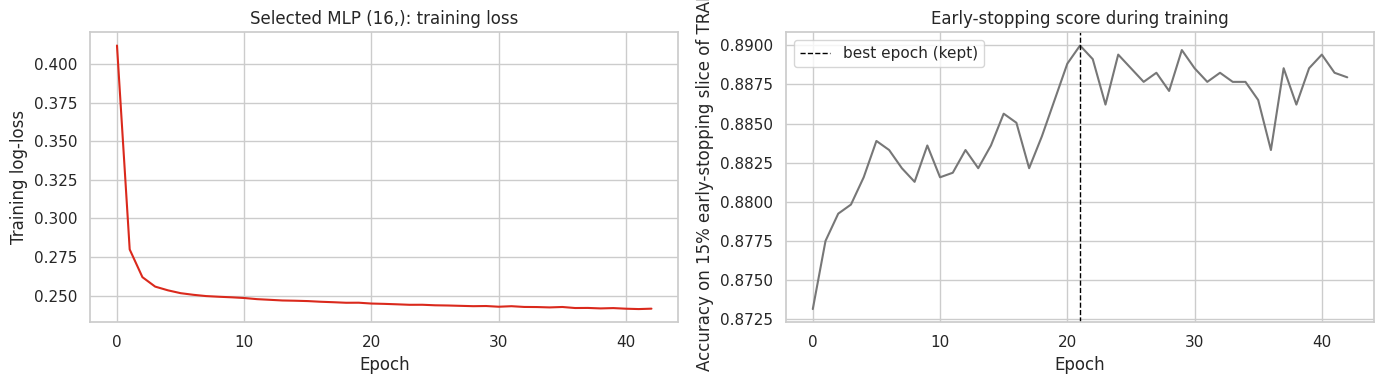

In [46]:
mlp_pipe = tune_family("Shallow Neural Network (MLP)",
                       MLPClassifier(max_iter=600, early_stopping=True, validation_fraction=0.15,
                                     n_iter_no_change=20, random_state=SEED),
                       {"hidden_layer_sizes": [(16,), (32,), (64,), (32, 16)], "alpha": [1e-4, 1e-3, 1e-2]})
mlp = mlp_pipe.named_steps["model"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(mlp.loss_curve_, color="#da291c")
axes[0].set(xlabel="Epoch", ylabel="Training log-loss", title=f"Selected MLP {mlp.hidden_layer_sizes}: training loss")
axes[1].plot(mlp.validation_scores_, color="#777777")
axes[1].axvline(int(np.argmax(mlp.validation_scores_)), color="black", linestyle="--", linewidth=1, label="best epoch (kept)")
axes[1].set(xlabel="Epoch", ylabel="Accuracy on 15% early-stopping slice of TRAIN",
            title="Early-stopping score during training"); axes[1].legend()
plt.tight_layout(); plt.show()

#### 34e. All modeling attempts compared

,family,selected_params,train_PR-AUC,val_PR-AUC,val_PR-AUC_vs_baseline
0,Logistic Regression,"{'C': 10.0, 'class_weight': None}",0.5727,0.7428,0.0002
1,Random Forest,"{'class_weight': 'balanced_subsample', 'max_de...",0.6751,0.7376,-0.0050
2,Hist Gradient Boosting,"{'l2_regularization': 0.0, 'learning_rate': 0....",0.7649,0.7450,0.0024
3,Shallow Neural Network (MLP),"{'alpha': 0.001, 'hidden_layer_sizes': (16,)}",0.5871,0.7368,-0.0058


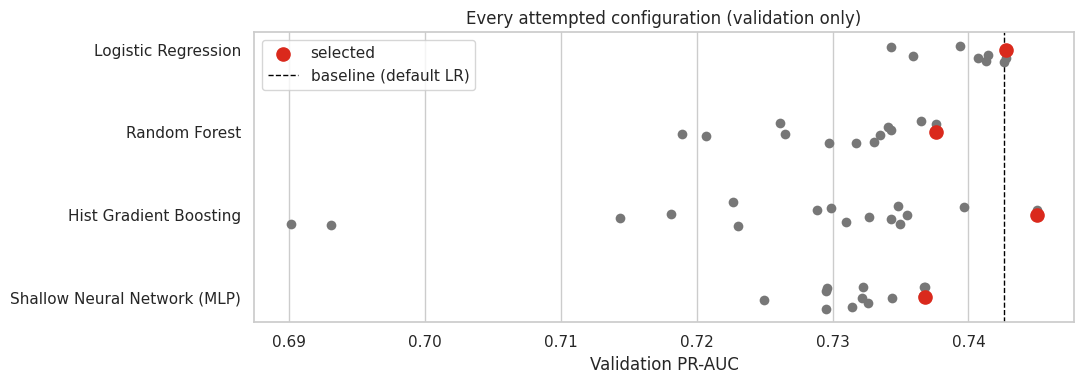

In [47]:
tuning_log = pd.DataFrame(tuning_rows).assign(params=lambda d: d.params.astype(str))
tuning_log["rank_in_family"] = tuning_log.groupby("family")["val_PR-AUC"].rank(ascending=False, method="first").astype(int)
display(pd.DataFrame([{"family": f, "selected_params": str(b["params"]), "train_PR-AUC": b["train_PR-AUC"],
                       "val_PR-AUC": b["val_PR-AUC"], "val_PR-AUC_vs_baseline": b["val_PR-AUC"] - baseline_val_pr}
                      for f, b in best_by_family.items()]).round(4))
fig, ax = plt.subplots(figsize=(11, 4))
family_order = list(best_by_family)
sns.stripplot(data=tuning_log, x="val_PR-AUC", y="family", order=family_order, ax=ax, size=7, color="#777777", jitter=.15)
ax.scatter([best_by_family[f]["val_PR-AUC"] for f in family_order], np.arange(len(family_order)),
           color="#da291c", s=90, zorder=3, label="selected")
ax.axvline(baseline_val_pr, color="black", linestyle="--", linewidth=1, label="baseline (default LR)")
ax.set(xlabel="Validation PR-AUC", ylabel="", title="Every attempted configuration (validation only)")
ax.legend(); plt.tight_layout(); plt.show()

### 35. Model comparison table: train, validation, and unseen test

All choices — preprocessing, feature set, hyperparameters, and thresholds — are now fixed. The table reports all five metrics on **training, validation, and the unseen test seasons (2022–2024)**, as the brief requires. The selected final model is the family with the best **validation** PR-AUC; test results are reported, never used for choosing. A large train→validation gap signals overfitting. A large validation→test drop signals a shift from the 2022 regulation change, or a threshold that does not transfer.

In [48]:
comparison_rows = []
for name, m in final_models.items():
    for split_name, y_true, proba, meta in [("train", y_train, m["p_train"], train_df), ("validation", y_val, m["p_val"], val_df),
                                            ("test", y_test, m["p_test"], test_df)]:
        comparison_rows.append({"model": name, "kind": m["kind"], "split": split_name, "threshold": m["threshold"],
                                **five_metrics(y_true, proba, m["threshold"]),
                                "Brier (supp.)": brier_score_loss(y_true, proba),
                                "Race top-3 hit rate (supp.)": race_top3_hit_rate(meta, proba)})
model_comparison = pd.DataFrame(comparison_rows)
model_order = list(final_models)
five_wide = (model_comparison.pivot(index="model", columns="split", values=FIVE_METRICS)
             .reindex(model_order).swaplevel(axis=1).reindex(columns=["train", "validation", "test"], level=0))
print("Model comparison table — five metrics on train / validation / test (threshold chosen on validation):")
display(five_wide.round(3))
print("Supplementary metrics:")
display(model_comparison.pivot(index="model", columns="split", values=["Brier (supp.)", "Race top-3 hit rate (supp.)"]).reindex(model_order).round(3))

ml_only = model_comparison[(model_comparison.kind == "model") & (model_comparison.split == "validation")]
BEST_FAMILY = ml_only.sort_values("PR-AUC", ascending=False).model.iloc[0]
best_pipe = final_models[BEST_FAMILY]["model"]
best_threshold = final_models[BEST_FAMILY]["threshold"]
best_val = model_comparison.query("model == @BEST_FAMILY and split == 'validation'").iloc[0]
best_test = model_comparison.query("model == @BEST_FAMILY and split == 'test'").iloc[0]
best_train = model_comparison.query("model == @BEST_FAMILY and split == 'train'").iloc[0]
base_val = model_comparison.query("model == @BASELINE_NAME and split == 'validation'").iloc[0]
base_test = model_comparison.query("model == @BASELINE_NAME and split == 'test'").iloc[0]
grid_test = model_comparison.query("model == 'Reference: grid-slot podium rate' and split == 'test'").iloc[0]
display(Markdown(f"""**Selected model: {BEST_FAMILY}** (params `{final_models[BEST_FAMILY]['params']}`, threshold {best_threshold:.3f}, chosen on validation).

| | PR-AUC | ROC-AUC | F1 | Precision | Recall |
|---|---|---|---|---|---|
| Train 1950–2019 | {best_train['PR-AUC']:.3f} | {best_train['ROC-AUC']:.3f} | {best_train['F1']:.3f} | {best_train['Precision']:.3f} | {best_train['Recall']:.3f} |
| Validation 2020–2021 | {best_val['PR-AUC']:.3f} | {best_val['ROC-AUC']:.3f} | {best_val['F1']:.3f} | {best_val['Precision']:.3f} | {best_val['Recall']:.3f} |
| Test 2022–2024 | {best_test['PR-AUC']:.3f} | {best_test['ROC-AUC']:.3f} | {best_test['F1']:.3f} | {best_test['Precision']:.3f} | {best_test['Recall']:.3f} |
| Baseline (default LR), validation | {base_val['PR-AUC']:.3f} | {base_val['ROC-AUC']:.3f} | {base_val['F1']:.3f} | {base_val['Precision']:.3f} | {base_val['Recall']:.3f} |
| Baseline (default LR), test | {base_test['PR-AUC']:.3f} | {base_test['ROC-AUC']:.3f} | {base_test['F1']:.3f} | {base_test['Precision']:.3f} | {base_test['Recall']:.3f} |

**Against the baseline:** on validation, which is the split used for choosing, the selected model's PR-AUC differs from the default Logistic Regression baseline by **{best_val['PR-AUC'] - base_val['PR-AUC']:+.3f}**; on test the difference is {best_test['PR-AUC'] - base_test['PR-AUC']:+.3f}. If the gain is close to zero, the simpler baseline is just as good, and the report should say so. Against the grid-only reference, the test PR-AUC gain is {best_test['PR-AUC'] - grid_test['PR-AUC']:+.3f}, which shows what form, standings, qualifying pace, and context add beyond the starting slot. Train→validation PR-AUC gap: {best_train['PR-AUC'] - best_val['PR-AUC']:+.3f} (overfitting check). Validation→test change: {best_test['PR-AUC'] - best_val['PR-AUC']:+.3f}."""))

Model comparison table — five metrics on train / validation / test (threshold chosen on validation):


split                                     train                          \
                                        ROC-AUC PR-AUC     F1 Precision   
model                                                                     
Baseline: Logistic Regression (default)   0.901  0.573  0.550     0.582   
Reference: class prior                    0.500  0.134  0.236     0.134   
Reference: grid-slot podium rate          0.882  0.496  0.543     0.544   
Logistic Regression                       0.901  0.573  0.550     0.582   
Random Forest                             0.934  0.675  0.636     0.574   
Hist Gradient Boosting                    0.958  0.765  0.686     0.557   
Shallow Neural Network (MLP)              0.904  0.587  0.574     0.559   

split                                          validation                \
                                        Recall    ROC-AUC PR-AUC     F1   
model                                                                     
Baseline: Logistic Regression (default)  0.521      0.930  0.743  0.704   
Reference: class prior                   1.000      0.500  0.150  0.261   
Reference: grid-slot podium rate         0.542      0.909  0.638  0.692   
Logistic Regression                      0.521      0.930  0.743  0.704   
Random Forest                            0.713      0.933  0.738  0.703   
Hist Gradient Boosting                   0.892      0.932  0.745  0.718   
Shallow Neural Network (MLP)             0.591      0.928  0.737  0.701   

split                                                       test         \
                                        Precision Recall ROC-AUC PR-AUC   
model                                                                     
Baseline: Logistic Regression (default)     0.707  0.701   0.935  0.719   
Reference: class prior                      0.150  1.000   0.500  0.150   
Reference: grid-slot podium rate            0.692  0.692   0.913  0.647   
Logistic Regression                         0.707  0.701   0.935  0.719   
Random Forest                               0.697  0.709   0.939  0.711   
Hist Gradient Boosting                      0.655  0.795   0.933  0.700   
Shallow Neural Network (MLP)                0.711  0.692   0.934  0.707   

split                                                            
                                            F1 Precision Recall  
model                                                            
Baseline: Logistic Regression (default)  0.672     0.682  0.662  
Reference: class prior                   0.262     0.150  1.000  
Reference: grid-slot podium rate         0.649     0.650  0.647  
Logistic Regression                      0.672     0.682  0.662  
Random Forest                            0.682     0.636  0.735  
Hist Gradient Boosting                   0.654     0.574  0.760  
Shallow Neural Network (MLP)             0.673     0.660  0.686

Supplementary metrics:


Brier (supp.)                    \
split                                            test  train validation   
model                                                                     
Baseline: Logistic Regression (default)         0.069  0.078      0.067   
Reference: class prior                          0.128  0.116      0.128   
Reference: grid-slot podium rate                0.076  0.082      0.076   
Logistic Regression                             0.069  0.078      0.067   
Random Forest                                   0.100  0.105      0.093   
Hist Gradient Boosting                          0.072  0.058      0.066   
Shallow Neural Network (MLP)                    0.071  0.077      0.068   

                                        Race top-3 hit rate (supp.)         \
split                                                          test  train   
model                                                                        
Baseline: Logistic Regression (default)                       0.657  0.547   
Reference: class prior                                        0.137  0.223   
Reference: grid-slot podium rate                              0.652  0.545   
Logistic Regression                                           0.657  0.548   
Random Forest                                                 0.657  0.611   
Hist Gradient Boosting                                        0.637  0.689   
Shallow Neural Network (MLP)                                  0.632  0.557   

                                                    
split                                   validation  
model                                               
Baseline: Logistic Regression (default)      0.692  
Reference: class prior                       0.291  
Reference: grid-slot podium rate             0.692  
Logistic Regression                          0.701  
Random Forest                                0.692  
Hist Gradient Boosting                       0.692  
Shallow Neural Network (MLP)                 0.684

**Selected model: Hist Gradient Boosting** (params `{'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}`, threshold 0.240, chosen on validation).

| | PR-AUC | ROC-AUC | F1 | Precision | Recall |
|---|---|---|---|---|---|
| Train 1950–2019 | 0.765 | 0.958 | 0.686 | 0.557 | 0.892 |
| Validation 2020–2021 | 0.745 | 0.932 | 0.718 | 0.655 | 0.795 |
| Test 2022–2024 | 0.700 | 0.933 | 0.654 | 0.574 | 0.760 |
| Baseline (default LR), validation | 0.743 | 0.930 | 0.704 | 0.707 | 0.701 |
| Baseline (default LR), test | 0.719 | 0.935 | 0.672 | 0.682 | 0.662 |

**Against the baseline:** on validation, which is the split used for choosing, the selected model's PR-AUC differs from the default Logistic Regression baseline by **+0.002**; on test the difference is -0.019. If the gain is close to zero, the simpler baseline is just as good, and the report should say so. Against the grid-only reference, the test PR-AUC gain is +0.053, which shows what form, standings, qualifying pace, and context add beyond the starting slot. Train→validation PR-AUC gap: +0.020 (overfitting check). Validation→test change: -0.045.

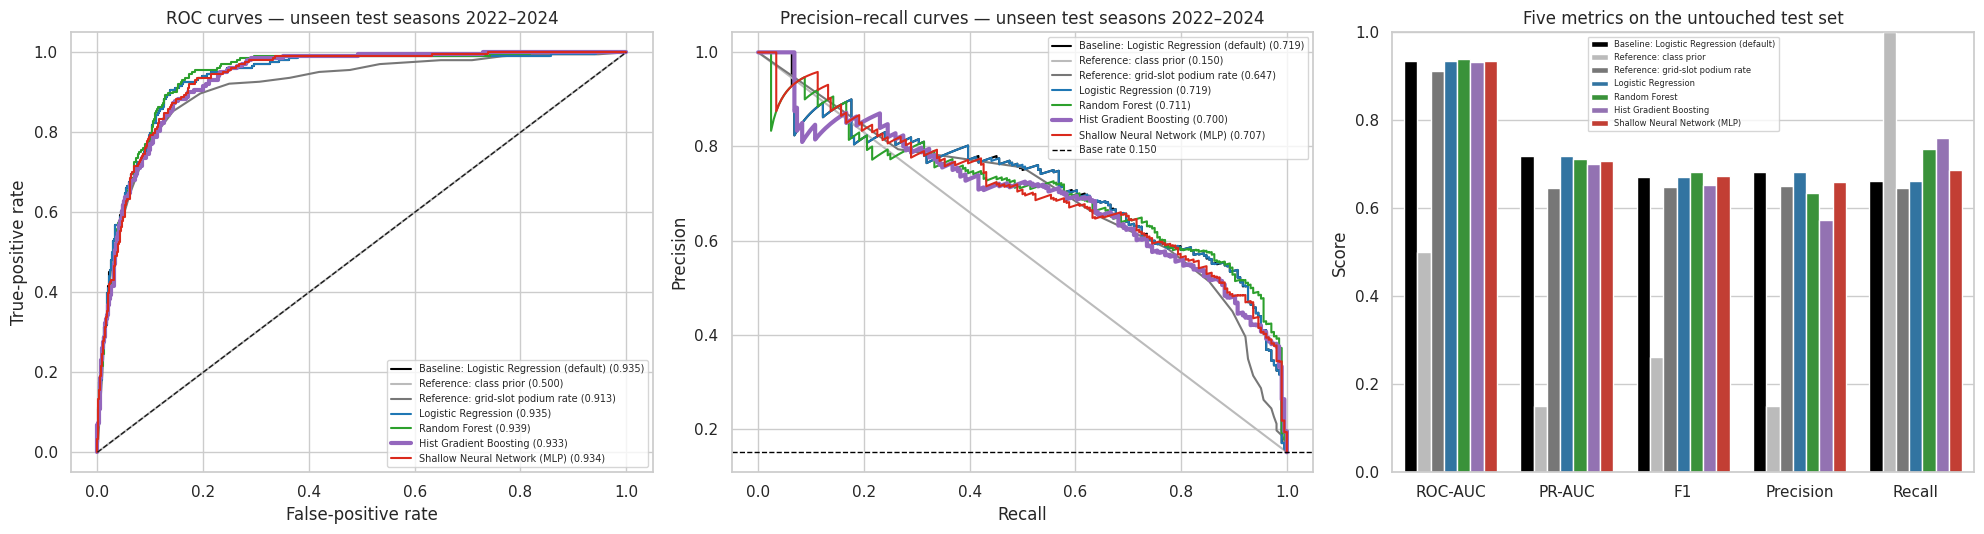

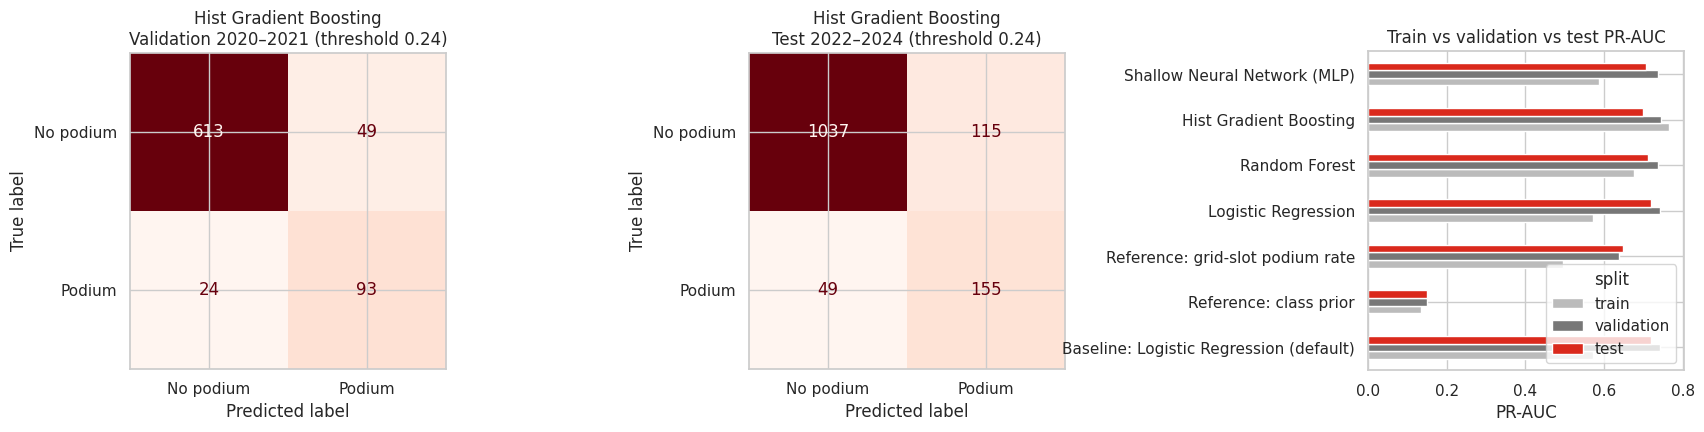

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
palette = dict(zip(model_order, ["#000000", "#bbbbbb", "#777777", "#1f77b4", "#2ca02c", "#9467bd", "#da291c"]))
for name in model_order:
    p = final_models[name]["p_test"]
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    width = 3 if name == BEST_FAMILY else 1.5
    axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, p):.3f})", color=palette[name], linewidth=width)
    axes[1].plot(rec, prec, label=f"{name} ({average_precision_score(y_test, p):.3f})", color=palette[name], linewidth=width)
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set(xlabel="False-positive rate", ylabel="True-positive rate", title="ROC curves — unseen test seasons 2022–2024")
axes[1].axhline(y_test.mean(), color="black", linestyle="--", linewidth=1, label=f"Base rate {y_test.mean():.3f}")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curves — unseen test seasons 2022–2024")
for ax in axes[:2]:
    ax.legend(fontsize=7, loc="lower right" if ax is axes[0] else "upper right")
test_long = model_comparison[model_comparison.split == "test"].melt(id_vars="model", value_vars=FIVE_METRICS, var_name="metric")
sns.barplot(data=test_long, x="metric", y="value", hue="model", hue_order=model_order, palette=palette, ax=axes[2])
axes[2].set(ylim=(0, 1), ylabel="Score", xlabel="", title="Five metrics on the untouched test set")
axes[2].legend(fontsize=6)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (split_name, y_true, proba) in zip(axes[:2], [("Validation 2020–2021", y_val, final_models[BEST_FAMILY]["p_val"]),
                                                      ("Test 2022–2024", y_test, final_models[BEST_FAMILY]["p_test"])]):
    ConfusionMatrixDisplay(confusion_matrix(y_true, (proba >= best_threshold).astype(int)),
                           display_labels=["No podium", "Podium"]).plot(ax=ax, cmap="Reds", colorbar=False)
    ax.set_title(f"{BEST_FAMILY}\n{split_name} (threshold {best_threshold:.2f})")
gap = model_comparison.pivot(index="model", columns="split", values="PR-AUC").reindex(model_order)[["train", "validation", "test"]]
gap.plot(kind="barh", ax=axes[2], color=["#bbbbbb", "#777777", "#da291c"])
axes[2].set(xlabel="PR-AUC", ylabel="", title="Train vs validation vs test PR-AUC")
plt.tight_layout(); plt.show()

#### Interpretation of the model results

- **Primary metric, PR-AUC:** podiums are only about 15% of rows in 2020–2024, so PR-AUC is the honest measure of ranking quality. The class-prior reference scores just 0.150 on test, while every real model scores 0.70–0.72.
- **Secondary metric, ROC-AUC:** every model is about 0.93 on validation and test, which confirms that the separation is strong and stable across splits.
- **Selected model: Histogram Gradient Boosting** (best validation PR-AUC, 0.745). It reaches test PR-AUC 0.700, ROC-AUC 0.933, and F1 0.654 at the validation-chosen threshold of 0.24.
- **Against the baseline:** the default Logistic Regression scores 0.743 on validation and **0.719** on test. The four tuned families are within about 0.01 of each other and of the baseline. **The simpler baseline is as good as the more complex models** on unseen seasons. Our conclusion is that well-engineered pre-race features matter more than the choice of model.
- **Against grid only:** every model beats the grid-slot reference (test PR-AUC 0.647) by about +0.05 to +0.07. That is the value added by qualifying pace, form, and standings.
- **Overfitting:** HGB's train PR-AUC (0.765) is only 0.02 above validation. Random Forest's selected setting is depth-limited (max depth 10) for the same reason; in the search, unlimited-depth forests reached train PR-AUC of about 0.90 but did worse on validation.
- **Validation → test drop** (0.745 → 0.700): the test seasons are a new technical era (2022 ground-effect rules), so some decline is expected.

## Step 7 — Ablations, sensitivity checks, and explanations

### 36. Feature-group ablations

The brief defines an ablation as removing one group of features at a time and re-training, to see how much performance drops, and asks for results for each group (standings, qualifying, grid, …). **Method:** Using the selected model family with its selected hyperparameters, we refit on training data (1) with all features, (2) **without each group in turn**, and (3) **with each group alone**. Every variant is scored on validation, because test results must not influence any decision. **Uncertainty:** validation has only 39 races, so small PR-AUC changes can be noise. (1) Models with randomness (forest, neural network) are trained with three seeds and their probabilities averaged; a deterministic model gives the same result for every seed. (2) Each change is given a **95% paired bootstrap interval**: whole validation races are resampled 1,000 times, and the full and reduced models are scored on the same resample. A change counts as real only if its interval excludes zero. A large PR-AUC drop when a group is removed means the model depends on information found only in that group. A small drop means the group is redundant given the others, even if it is predictive on its own.

,variant,n_features,val_PR-AUC,val_ROC-AUC,PR-AUC_seed_std,delta_PR-AUC_vs_all,delta_CI95_low,delta_CI95_high,change_is_real_95
0,All features,28,0.7450,0.9319,0.0,0.0000,0.0000,0.0000,False
1,Without grid,24,0.7128,0.9221,0.0,-0.0322,-0.0696,0.0101,False
2,Without qualifying,24,0.7274,0.9261,0.0,-0.0176,-0.0466,0.0121,False
3,Without driver_form,22,0.7257,0.9315,0.0,-0.0193,-0.0384,0.0054,False
4,Without constructor_form,24,0.7423,0.9311,0.0,-0.0027,-0.0199,0.0146,False
5,Without standings,21,0.7021,0.9276,0.0,-0.0430,-0.0746,-0.0090,True
6,Without race_context,25,0.7372,0.9312,0.0,-0.0078,-0.0200,0.0082,False
7,Only grid,4,0.6543,0.9165,0.0,-0.0907,-0.1321,-0.0429,True
8,Only qualifying,4,0.6814,0.9281,0.0,-0.0636,-0.1152,-0.0090,True
9,Only driver_form,6,0.5847,0.8659,0.0,-0.1603,-0.2147,-0.0969,True


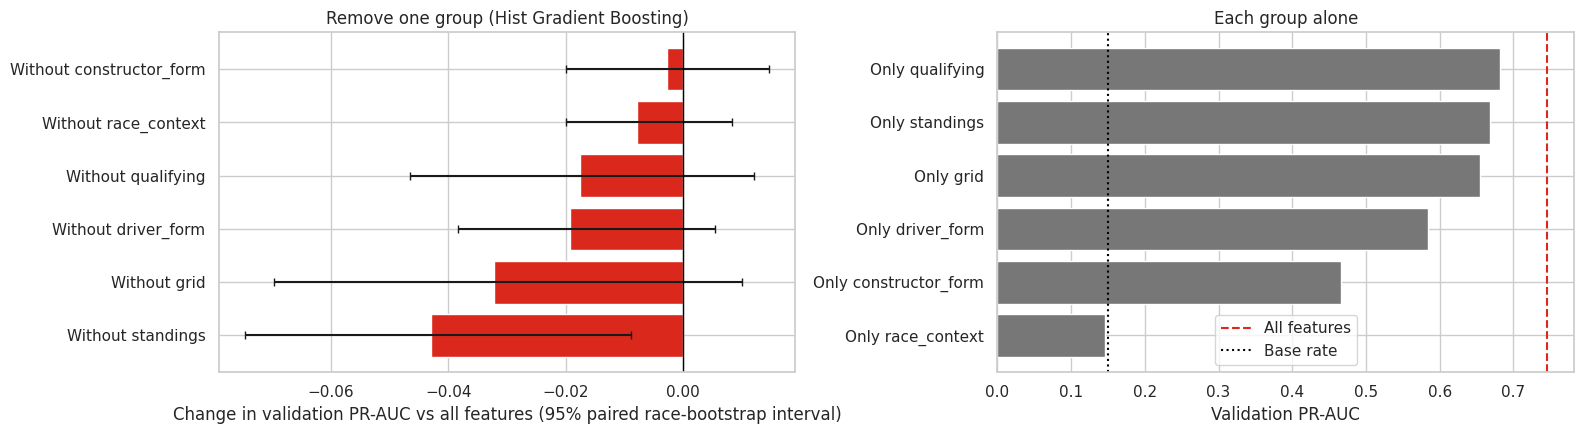

In [50]:
best_model_template = clone(best_pipe.named_steps["model"])

ABLATION_SEEDS = [SEED, SEED + 1, SEED + 2]

def fit_feature_subset(features, X_fit=None, y_fit=None, seed=SEED):
    X_fit = X_train if X_fit is None else X_fit
    y_fit = y_train if y_fit is None else y_fit
    numeric = [f for f in features if f not in CATEGORICAL_FEATURES]
    categorical = [f for f in features if f in CATEGORICAL_FEATURES]
    model = clone(best_model_template)
    if "random_state" in model.get_params():
        model.set_params(random_state=seed)
    pipe = Pipeline([("prep", make_model_preprocessor(numeric, categorical)), ("model", model)])
    return pipe.fit(X_fit[features], y_fit)

def score_feature_subset(features, X_fit=None, y_fit=None):
    """Validation probabilities averaged over ABLATION_SEEDS, plus summary scores."""
    probs = [fit_feature_subset(features, X_fit, y_fit, seed).predict_proba(X_val[features])[:, 1] for seed in ABLATION_SEEDS]
    p = np.mean(probs, axis=0)
    return p, {"val_PR-AUC": average_precision_score(y_val, p), "val_ROC-AUC": roc_auc_score(y_val, p),
               "PR-AUC_seed_std": float(np.std([average_precision_score(y_val, q) for q in probs]))}

val_race_rows = [np.flatnonzero(val_df.raceId.to_numpy() == r) for r in np.unique(val_df.raceId)]

def paired_bootstrap_delta(p_variant, p_reference, n_boot=1000, seed=SEED):
    """95% interval of PR-AUC(variant) - PR-AUC(reference), resampling whole validation races."""
    rng = np.random.default_rng(seed)
    deltas = []
    for _ in range(n_boot):
        idx = np.concatenate([val_race_rows[i] for i in rng.integers(0, len(val_race_rows), len(val_race_rows))])
        deltas.append(average_precision_score(y_val[idx], p_variant[idx]) - average_precision_score(y_val[idx], p_reference[idx]))
    return np.percentile(deltas, [2.5, 97.5])

ablation_variants = [("All features", ALL_FEATURES)]
ablation_variants += [(f"Without {g}", [f for f in ALL_FEATURES if f not in cols]) for g, cols in FEATURE_GROUPS.items()]
ablation_variants += [(f"Only {g}", cols) for g, cols in FEATURE_GROUPS.items()]
ablation_probs, ablation_rows = {}, []
for name, features in ablation_variants:
    ablation_probs[name], scores = score_feature_subset(features)
    ablation_rows.append({"variant": name, "n_features": len(features), **scores})
ablation = pd.DataFrame(ablation_rows)
full_pr = ablation.loc[ablation.variant == "All features", "val_PR-AUC"].iloc[0]
p_full = ablation_probs["All features"]
ablation["delta_PR-AUC_vs_all"] = ablation["val_PR-AUC"] - full_pr
intervals = [paired_bootstrap_delta(ablation_probs[v], p_full) if v != "All features" else (0.0, 0.0) for v in ablation.variant]
ablation["delta_CI95_low"], ablation["delta_CI95_high"] = zip(*intervals)
ablation["change_is_real_95"] = (ablation.delta_CI95_high < 0) | (ablation.delta_CI95_low > 0)
display(ablation.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
drop = ablation[ablation.variant.str.startswith("Without")].sort_values("delta_PR-AUC_vs_all")
axes[0].barh(drop.variant, drop["delta_PR-AUC_vs_all"], capsize=3, color="#da291c",
             xerr=[drop["delta_PR-AUC_vs_all"] - drop.delta_CI95_low, drop.delta_CI95_high - drop["delta_PR-AUC_vs_all"]])
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set(xlabel="Change in validation PR-AUC vs all features (95% paired race-bootstrap interval)", title=f"Remove one group ({BEST_FAMILY})")
only = ablation[ablation.variant.str.startswith("Only")].sort_values("val_PR-AUC")
axes[1].barh(only.variant, only["val_PR-AUC"], color="#777777")
axes[1].axvline(full_pr, color="#da291c", linestyle="--", label="All features")
axes[1].axvline(y_val.mean(), color="black", linestyle=":", label="Base rate")
axes[1].set(xlabel="Validation PR-AUC", title="Each group alone"); axes[1].legend()
plt.tight_layout(); plt.show()

### 37. Sensitivity checks (era sensitivity and grid-zero rows)

1. **Retained grid-zero rows:** the F1 guide says grid 0 means a pit-lane start but should be verified in EDA. Step 2 kept a small number of these records. We drop them from training and check whether validation performance changes.
2. **Restricting the training window:** the guide suggests imputing, falling back to grid, or restricting the training window to handle qualifying-coverage drift. The main model trains on 1950–2019 with imputation. Here we retrain on **1994–2019 only**, where qualifying data exists, and score the same validation seasons. This shows whether the older, partially imputed seasons help or hurt.

Both checks use the selected family and hyperparameters, the same seed averaging, the unchanged validation set, and the same paired race-bootstrap interval as the ablation.

In [51]:
reference_row = ablation[ablation.variant == "All features"].iloc[0]
sensitivity_rows = [{"check": "Reference: all training seasons 1950–2019", "train_rows": len(X_train),
                     "val_PR-AUC": reference_row["val_PR-AUC"], "PR-AUC_seed_std": reference_row["PR-AUC_seed_std"],
                     "val_ROC-AUC": reference_row["val_ROC-AUC"], "delta_CI95_low": 0.0, "delta_CI95_high": 0.0}]
keep = train_df.grid.ne(0).to_numpy()
modern = (train_df.year >= 1994).to_numpy()
for label, mask in [(f"Drop {int((~keep).sum())} grid-zero training rows", keep),
                    ("Train on 1994–2019 only (qualifying era)", modern)]:
    p, scores = score_feature_subset(ALL_FEATURES, X_train[mask], y_train[mask])
    low, high = paired_bootstrap_delta(p, p_full)
    sensitivity_rows.append({"check": label, "train_rows": int(mask.sum()), **scores, "delta_CI95_low": low, "delta_CI95_high": high})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity["delta_PR-AUC"] = sensitivity["val_PR-AUC"] - full_pr
sensitivity["change_is_real_95"] = (sensitivity.delta_CI95_high < 0) | (sensitivity.delta_CI95_low > 0)
print("Grid-zero rows in validation / test (kept):", int(val_df.grid.eq(0).sum()), "/", int(test_df.grid.eq(0).sum()))
display(sensitivity.round(4))

Grid-zero rows in validation / test (kept): 16 / 37


,check,train_rows,val_PR-AUC,PR-AUC_seed_std,val_ROC-AUC,delta_CI95_low,delta_CI95_high,delta_PR-AUC,change_is_real_95
0,Reference: all training seasons 1950–2019,22965,0.7450,0.0,0.9319,0.0000,0.0000,0.0000,False
1,Drop 34 grid-zero training rows,22931,0.7374,0.0,0.9297,-0.0193,0.0031,-0.0077,False
2,Train on 1994–2019 only (qualifying era),10152,0.7360,0.0,0.9311,-0.0441,0.0326,-0.0090,False


### 38. Global explanation 1 — permutation importance

**Method:** Starting from the fitted final pipeline, we shuffle one raw feature at a time in the **validation** set, ten times each, and measure the mean drop in PR-AUC. Because the preprocessing pipeline is included, each raw feature's importance includes its missing-value indicator. Correlated features share credit: shuffling start position alone understates the grid signal while qualifying position remains. We therefore also permute **whole feature groups together**.

**Caution:** importance describes what **this model relies on**. It is not the causal effect of a feature on podium chances.

,feature,group,mean_PR-AUC_drop,std
0,start_position,grid,0.1094,0.0295
1,best_quali_gap_pct,qualifying,0.0380,0.0182
2,driver_prev_starts,driver_form,0.0254,0.0126
3,driver_career_podium_rate,driver_form,0.0242,0.0115
4,driver_age,driver_form,0.0157,0.0057
5,start_position_pct,grid,0.0141,0.0128
6,driver_prior_wins,standings,0.0135,0.0074
7,driver_prior_points_share,standings,0.0113,0.0090
8,driver_last_season_position,standings,0.0081,0.0030
9,constructor_finish_rate_last10,constructor_form,0.0075,0.0058


,group,mean_PR-AUC_drop,std
0,grid,0.2552,0.0226
1,qualifying,0.0608,0.0315
4,standings,0.0517,0.0171
2,driver_form,0.0291,0.0164
3,constructor_form,0.0054,0.0030
5,race_context,-0.0001,0.0029


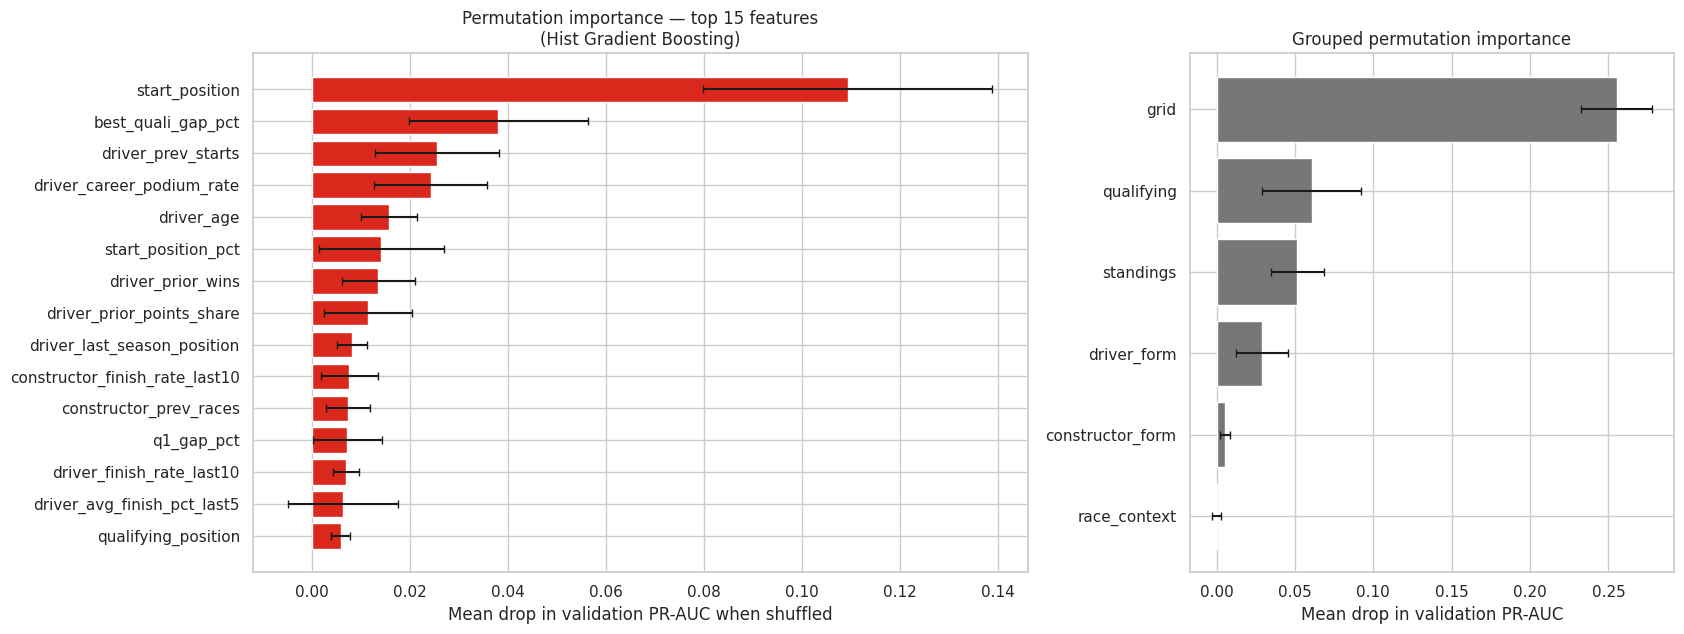

In [52]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(best_pipe, X_val, y_val, scoring="average_precision", n_repeats=10, random_state=SEED)
perm_table = (pd.DataFrame({"feature": ALL_FEATURES, "group": [FEATURE_TO_GROUP[f] for f in ALL_FEATURES],
                            "mean_PR-AUC_drop": perm.importances_mean, "std": perm.importances_std})
              .sort_values("mean_PR-AUC_drop", ascending=False).reset_index(drop=True))
display(perm_table.round(4))

def group_permutation_importance(pipe, X, y, groups, n_repeats=5, seed=SEED):
    rng = np.random.default_rng(seed)
    base = average_precision_score(y, pipe.predict_proba(X)[:, 1])
    rows = []
    for group, columns in groups.items():
        drops = []
        for _ in range(n_repeats):
            idx = rng.permutation(len(X))
            X_perm = X.copy()
            for column in columns:
                X_perm[column] = X[column].to_numpy()[idx]
            drops.append(base - average_precision_score(y, pipe.predict_proba(X_perm)[:, 1]))
        rows.append({"group": group, "mean_PR-AUC_drop": np.mean(drops), "std": np.std(drops)})
    return pd.DataFrame(rows).sort_values("mean_PR-AUC_drop", ascending=False)

group_perm = group_permutation_importance(best_pipe, X_val, y_val, FEATURE_GROUPS)
display(group_perm.round(4))

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.6, 1]})
top = perm_table.head(15).iloc[::-1]
axes[0].barh(top.feature, top["mean_PR-AUC_drop"], xerr=top["std"], color="#da291c", capsize=3)
axes[0].set(xlabel="Mean drop in validation PR-AUC when shuffled", title=f"Permutation importance — top 15 features\n({BEST_FAMILY})")
axes[1].barh(group_perm.group.iloc[::-1], group_perm["mean_PR-AUC_drop"].iloc[::-1], xerr=group_perm["std"].iloc[::-1], color="#777777", capsize=3)
axes[1].set(xlabel="Mean drop in validation PR-AUC", title="Grouped permutation importance")
plt.tight_layout(); plt.show()

### 39. Global explanation 2 — SHAP

**Method:** SHAP divides each prediction into additive contributions from the transformed model inputs: scaled features, missing indicators, and one-hot columns. We explain a random sample of **test** rows; using test rows here does not influence any choice, because the model is already fixed. The **reference (background) population** for SHAP and LIME is the training seasons 2006–2019, which used the same knockout qualifying format as the explained 2022–2024 rows. With all 1950–2019 rows as the reference, the first run attributed much of each prediction to *this row has qualifying data* — an era difference, not a driver-level reason. Tree models use `TreeExplainer`, Logistic Regression uses `LinearExplainer`, and the MLP uses the model-agnostic permutation explainer with a training background sample. The output scale is shown in each title (probability or log-odds).

- **Beeswarm plot:** each dot is one driver–race. Its position shows how much the feature pushed the prediction up or down, and its colour shows the feature value (red = high).
- **Bar plot:** mean |SHAP| gives a global importance ranking.

As with permutation importance, these values explain the **model's behaviour**, not causal effects.

shap version: 0.52.0
SHAP/LIME reference population: 5766 training rows from 2006–2019
TreeExplainer (log-odds): explained 300 test rows x 31 inputs in 0.9s


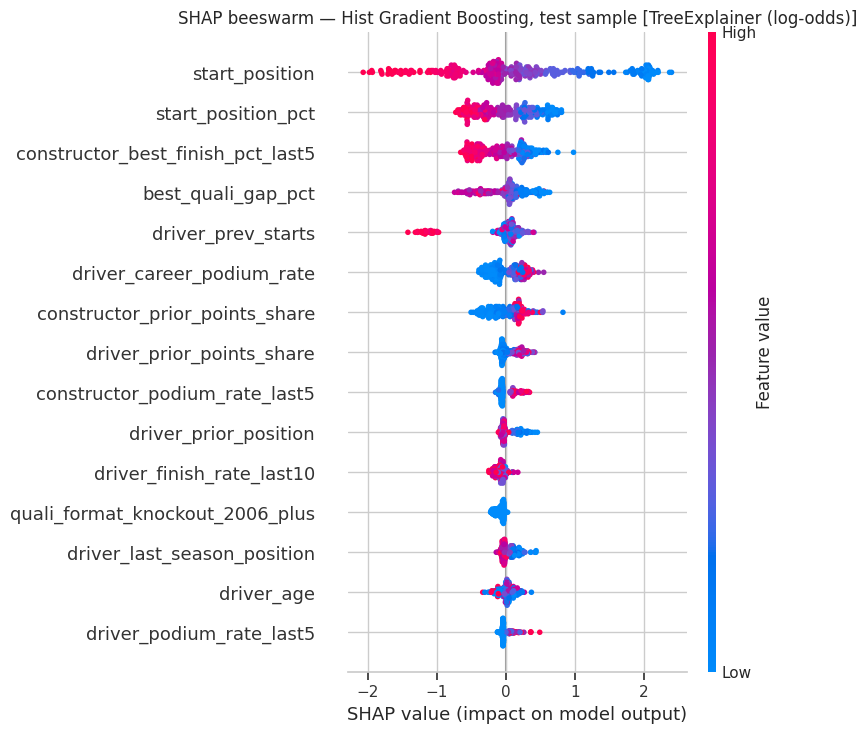

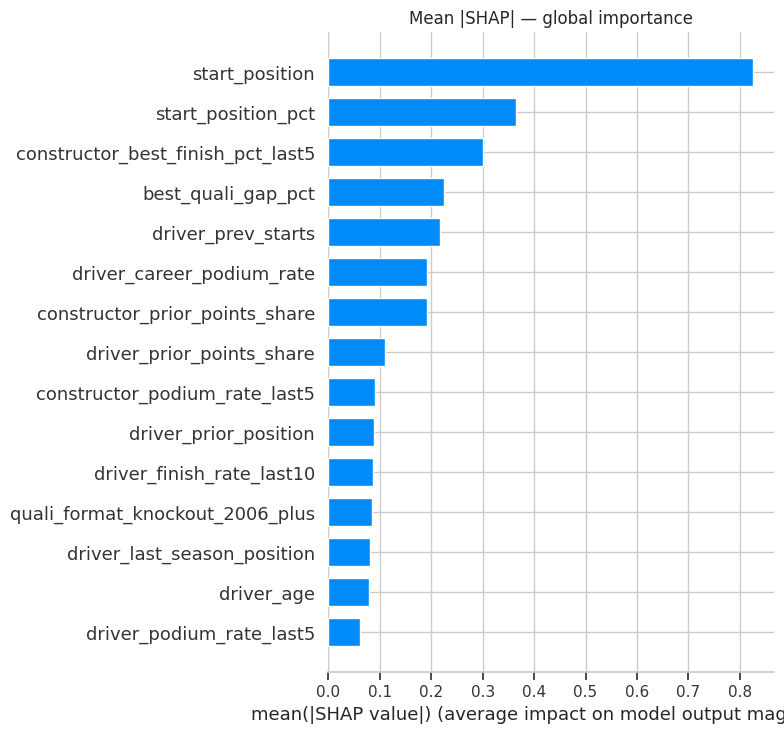

,input,mean_abs_shap
0,start_position,0.8252
1,start_position_pct,0.3648
2,constructor_best_finish_pct_last5,0.3009
3,best_quali_gap_pct,0.2250
4,driver_prev_starts,0.2173
5,driver_career_podium_rate,0.1926
6,constructor_prior_points_share,0.1921
7,driver_prior_points_share,0.1097
8,constructor_podium_rate_last5,0.0908
9,driver_prior_position,0.0879


In [53]:
import importlib, subprocess, sys

def ensure_package(module, pip_name=None):
    """Import a package; if missing, try pip (requires Kaggle Settings → Internet: On)."""
    try:
        return importlib.import_module(module)
    except ImportError:
        print(f"{module} not found; trying 'pip install {pip_name or module}' (needs Kaggle Internet ON)...")
        try:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module], check=True, timeout=600)
            return importlib.import_module(module)
        except Exception as exc:
            print(f"Could not install {module}: {exc}")
            return None

shap = ensure_package("shap")
HAS_SHAP = shap is not None
print("shap version:", shap.__version__ if HAS_SHAP else "unavailable (occlusion fallback used)")

best_prep = best_pipe.named_steps["prep"]
best_est = best_pipe.named_steps["model"]
shap_names = [str(n) for n in best_prep.get_feature_names_out()]
explain_raw = X_test.sample(n=min(300, len(X_test)), random_state=SEED)
explain_matrix = best_prep.transform(explain_raw)
EXPLAIN_REFERENCE_FROM = 2006   # knockout-qualifying era, the same format as the explained 2022–2024 rows
reference_raw = X_train[(train_df.year >= EXPLAIN_REFERENCE_FROM).to_numpy()]
background = best_prep.transform(reference_raw.sample(n=min(100, len(reference_raw)), random_state=SEED))
print(f"SHAP/LIME reference population: {len(reference_raw)} training rows from {EXPLAIN_REFERENCE_FROM}–{TRAIN_END_YEAR}")
explain_df = pd.DataFrame(explain_matrix, columns=shap_names, index=explain_raw.index)

def compute_shap(estimator):
    if isinstance(estimator, (RandomForestClassifier, HistGradientBoostingClassifier)):
        try:
            explainer = shap.TreeExplainer(estimator)
            values = explainer.shap_values(explain_matrix, check_additivity=False)
            if isinstance(values, list):
                values = values[1]
            values = np.asarray(values)
            if values.ndim == 3:
                values = values[:, :, 1]
            base = np.ravel(explainer.expected_value)[-1]
            scale = "probability" if isinstance(estimator, RandomForestClassifier) else "log-odds"
            return values, float(base), f"TreeExplainer ({scale})"
        except Exception as exc:
            print("TreeExplainer failed, falling back to permutation explainer:", exc)
    if isinstance(estimator, LogisticRegression):
        explainer = shap.LinearExplainer(estimator, background)
        return np.asarray(explainer.shap_values(explain_matrix)), float(np.ravel(explainer.expected_value)[-1]), "LinearExplainer (log-odds)"
    predict_pos = lambda data: estimator.predict_proba(np.asarray(data))[:, 1]
    explainer = shap.Explainer(predict_pos, shap.maskers.Independent(background, max_samples=100),
                               algorithm="permutation", feature_names=shap_names)
    explanation = explainer(explain_matrix, max_evals=max(500, 2 * explain_matrix.shape[1] + 1))
    return np.asarray(explanation.values), float(np.mean(explanation.base_values)), "Permutation explainer (probability)"

if HAS_SHAP:
    start = time.perf_counter()
    shap_values, shap_base, shap_method = compute_shap(best_est)
    print(f"{shap_method}: explained {shap_values.shape[0]} test rows x {shap_values.shape[1]} inputs in {time.perf_counter() - start:.1f}s")
    shap.summary_plot(shap_values, explain_df, max_display=15, show=False)
    plt.title(f"SHAP beeswarm — {BEST_FAMILY}, test sample [{shap_method}]"); plt.tight_layout(); plt.show()
    shap.summary_plot(shap_values, explain_df, plot_type="bar", max_display=15, show=False)
    plt.title("Mean |SHAP| — global importance"); plt.tight_layout(); plt.show()
    shap_global = (pd.DataFrame({"input": shap_names, "mean_abs_shap": np.abs(shap_values).mean(axis=0)})
                   .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))
    display(shap_global.head(15).round(4))

### 40. Local explanations — individual predictions (SHAP and LIME)

We choose three informative rows from the explained test sample:
- the **most confident correct podium prediction** (true positive);
- a **missed podium** (an actual podium with the lowest predicted probability, i.e. a false negative);
- the **most confident false alarm** (false positive).

SHAP waterfall plots show how each input moved that row's prediction away from the average. **LIME** fits a simple local surrogate model around the first row, giving a second, independent local explanation. When the two methods agree, the explanation is more trustworthy. Again, these describe the model's reasoning for one row, not why the driver actually finished where they did.

,year,race_name,forename,surname,constructor_name,grid,qualifying_position,podium,case,predicted_probability
24030,2022,Dutch Grand Prix,Max,Verstappen,Red Bull,1,1.0,1,True positive (most confident),0.911
25040,2024,Las Vegas Grand Prix,Lewis,Hamilton,Mercedes,10,10.0,1,Missed podium (lowest probability),0.033
24668,2024,Australian Grand Prix,Max,Verstappen,Red Bull,1,1.0,0,False alarm (most confident non-podium),0.869


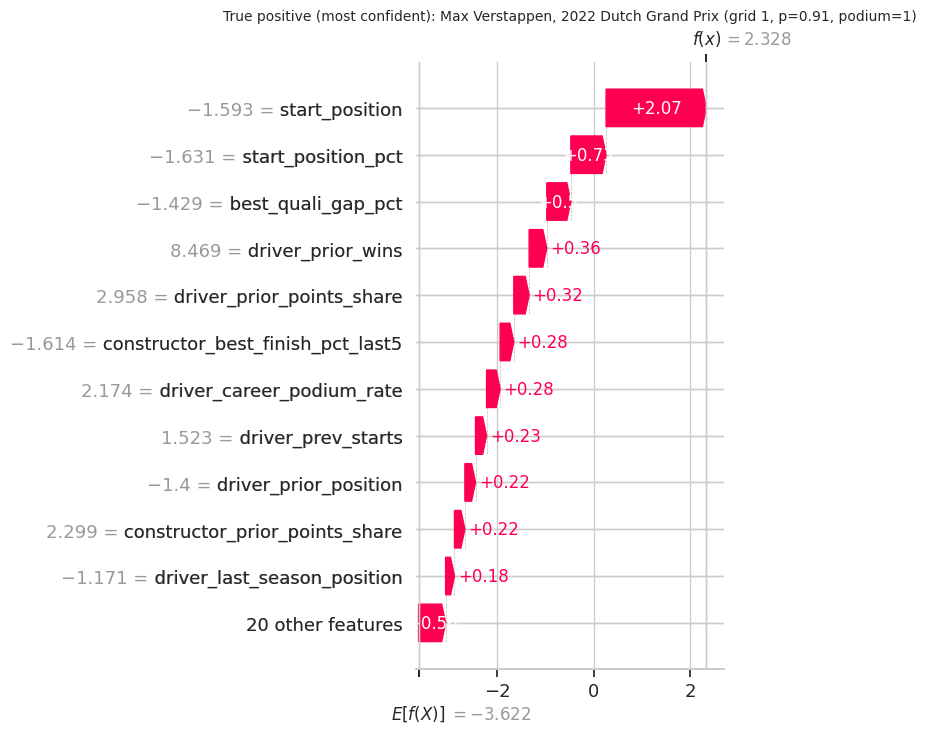

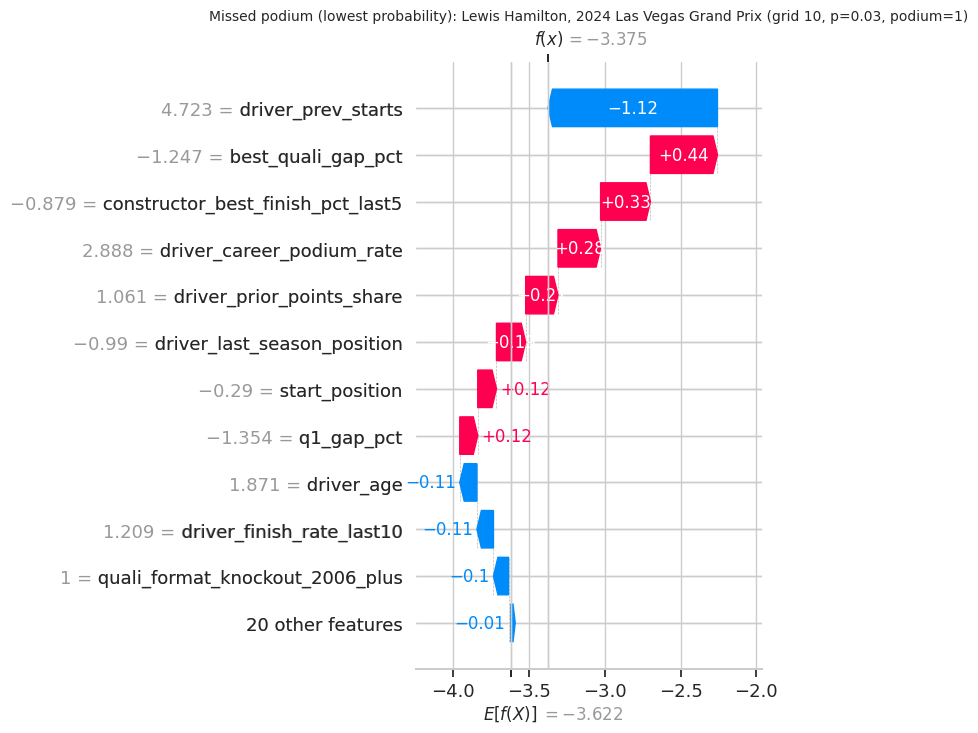

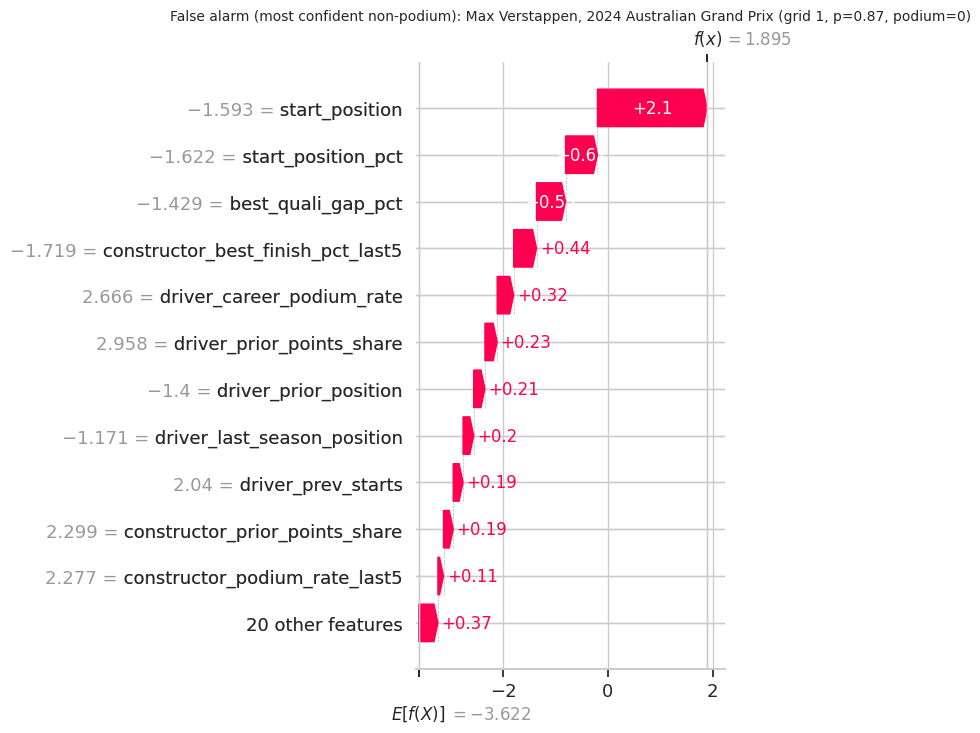

LIME local explanation for the true-positive case (weights toward 'podium'):


,condition (transformed scale),weight
0,start_position <= -0.87,0.1354
1,constructor_best_finish_pct_last5 <= -0.83,0.0579
2,start_position_pct <= -0.86,0.0532
3,best_quali_gap_pct <= -0.85,0.0381
4,driver_prior_points_share > 0.66,0.0268
5,driver_career_podium_rate > 0.52,0.0254
6,constructor_prior_points_share > 0.55,0.0214
7,driver_last_season_position <= -0.72,0.0197
8,grid_zero_flag <= -0.04,-0.0150
9,driver_prior_position <= -0.81,0.0133


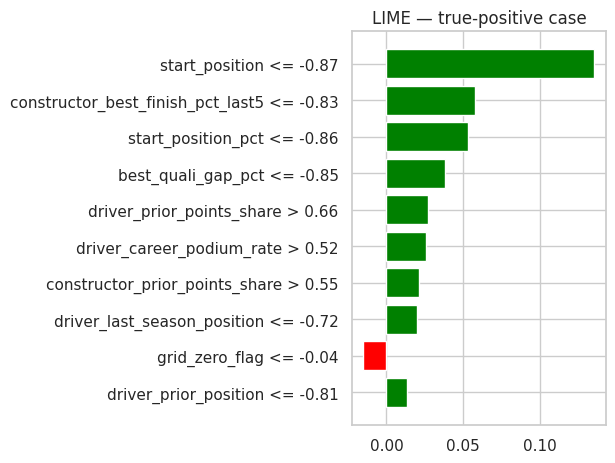

In [54]:
explain_proba = best_est.predict_proba(explain_matrix)[:, 1]
explain_y = test_df.loc[explain_raw.index, "podium"].to_numpy()
positions = np.arange(len(explain_raw))
cases = {}
if (explain_y == 1).any():
    cases["True positive (most confident)"] = positions[explain_y == 1][np.argmax(explain_proba[explain_y == 1])]
    cases["Missed podium (lowest probability)"] = positions[explain_y == 1][np.argmin(explain_proba[explain_y == 1])]
if (explain_y == 0).any():
    cases["False alarm (most confident non-podium)"] = positions[explain_y == 0][np.argmax(explain_proba[explain_y == 0])]
meta_cols = ["year", "race_name", "forename", "surname", "constructor_name", "grid", "qualifying_position", "podium"]
case_table = test_df.loc[explain_raw.index[list(cases.values())], meta_cols].assign(
    case=list(cases), predicted_probability=explain_proba[list(cases.values())].round(3))
display(case_table)

def occlusion_explanation(row_raw):
    """Fallback local explanation: change in probability when one raw feature is set to missing (imputed)."""
    base_p = best_pipe.predict_proba(row_raw)[0, 1]
    deltas = {}
    for f in ALL_FEATURES:
        probe = row_raw.copy()
        probe[f] = np.nan
        probe[CATEGORICAL_FEATURES] = probe[CATEGORICAL_FEATURES].astype(object)
        deltas[f] = base_p - best_pipe.predict_proba(probe)[0, 1]
    return pd.Series(deltas).sort_values(key=np.abs, ascending=False)

for case, pos in cases.items():
    who = test_df.loc[explain_raw.index[pos]]
    title = f"{case}: {who.forename} {who.surname}, {who.year} {who.race_name} (grid {who.grid}, p={explain_proba[pos]:.2f}, podium={who.podium})"
    if HAS_SHAP:
        explanation = shap.Explanation(values=shap_values[pos], base_values=shap_base,
                                       data=explain_matrix[pos], feature_names=shap_names)
        shap.plots.waterfall(explanation, max_display=12, show=False)
        plt.title(title, fontsize=10); plt.tight_layout(); plt.show()
    else:
        contrib = occlusion_explanation(explain_raw.iloc[[pos]]).head(12)
        contrib.iloc[::-1].plot(kind="barh", figsize=(9, 5), color="#da291c", title=title)
        plt.xlabel("Probability change vs. feature imputed"); plt.tight_layout(); plt.show()

lime_module = ensure_package("lime.lime_tabular", "lime")
if lime_module is not None:
    LimeTabularExplainer = lime_module.LimeTabularExplainer
    lime_pos = cases.get("True positive (most confident)", 0)
    lime_explainer = LimeTabularExplainer(best_prep.transform(reference_raw), feature_names=shap_names,
                                          class_names=["no podium", "podium"], mode="classification",
                                          discretize_continuous=True, random_state=SEED)
    lime_exp = lime_explainer.explain_instance(explain_matrix[lime_pos], best_est.predict_proba, num_features=10)
    print("LIME local explanation for the true-positive case (weights toward 'podium'):")
    display(pd.DataFrame(lime_exp.as_list(), columns=["condition (transformed scale)", "weight"]).round(4))
    fig = lime_exp.as_pyplot_figure()
    plt.title("LIME — true-positive case"); plt.tight_layout(); plt.show()
else:
    print("LIME is unavailable: turn on Kaggle Settings → Internet and rerun. The SHAP waterfall plots above still give a local explanation.")

In [55]:
top_perm = perm_table.head(3)
top_group = group_perm.iloc[0]
strongest_drop = ablation[ablation.variant.str.startswith("Without")].sort_values("delta_PR-AUC_vs_all").iloc[0]
local_text = "see the SHAP/LIME plots above."
if HAS_SHAP and "True positive (most confident)" in cases:
    tp = cases["True positive (most confident)"]
    top_local = pd.Series(shap_values[tp], index=shap_names).sort_values(key=np.abs, ascending=False).head(3)
    local_text = ("for the most confident correct podium prediction, the inputs that pushed the prediction most were "
                  + ", ".join(f"`{n}` ({v:+.3f})" for n, v in top_local.items())
                  + " (positive = toward podium). The LIME weights for the same row can be compared in the table above.")
display(Markdown(f"""**Step 7 findings (auto-generated)**

- **Ablation:** removing **{strongest_drop.variant.replace('Without ', '')}** causes the largest validation PR-AUC change ({strongest_drop['delta_PR-AUC_vs_all']:+.3f}). Groups whose removal changes PR-AUC with a 95% paired race-bootstrap interval excluding zero: {", ".join(ablation.loc[ablation.variant.str.startswith("Without") & ablation.change_is_real_95, "variant"].str.replace("Without ", "")) or "none"}. For the other groups the change is within the sampling noise of the 39 validation races, meaning the group is largely redundant given the rest.
- **Permutation importance:** the top raw features are {", ".join(f"`{f}` ({d:.3f})" for f, d in zip(top_perm.feature, top_perm["mean_PR-AUC_drop"]))}. The most important group is **{top_group.group}** (PR-AUC drop {top_group['mean_PR-AUC_drop']:.3f}).
- **SHAP:** {"the top global inputs by mean |SHAP| are " + ", ".join(f"`{n}`" for n in shap_global.input.head(5)) if HAS_SHAP else "SHAP was unavailable; occlusion explanations were used instead"}.
- **Local explanation:** {local_text}
- **Sensitivity:** dropping grid-zero rows changes validation PR-AUC by {sensitivity.loc[1, 'delta_PR-AUC']:+.3f} (95% interval {sensitivity.loc[1, 'delta_CI95_low']:+.3f} to {sensitivity.loc[1, 'delta_CI95_high']:+.3f}); training only on 1994–2019 changes it by {sensitivity.loc[2, 'delta_PR-AUC']:+.3f} ({sensitivity.loc[2, 'delta_CI95_low']:+.3f} to {sensitivity.loc[2, 'delta_CI95_high']:+.3f}). An interval containing zero means the choice makes no detectable difference.
- These are statements about **model behaviour**. A feature that is important here is useful for prediction, but that does not mean changing it would cause a podium."""))

**Step 7 findings (auto-generated)**

- **Ablation:** removing **standings** causes the largest validation PR-AUC change (-0.043). Groups whose removal changes PR-AUC with a 95% paired race-bootstrap interval excluding zero: standings. For the other groups the change is within the sampling noise of the 39 validation races, meaning the group is largely redundant given the rest.
- **Permutation importance:** the top raw features are `start_position` (0.109), `best_quali_gap_pct` (0.038), `driver_prev_starts` (0.025). The most important group is **grid** (PR-AUC drop 0.255).
- **SHAP:** the top global inputs by mean |SHAP| are `start_position`, `start_position_pct`, `constructor_best_finish_pct_last5`, `best_quali_gap_pct`, `driver_prev_starts`.
- **Local explanation:** for the most confident correct podium prediction, the inputs that pushed the prediction most were `start_position` (+2.073), `start_position_pct` (+0.729), `best_quali_gap_pct` (+0.497) (positive = toward podium). The LIME weights for the same row can be compared in the table above.
- **Sensitivity:** dropping grid-zero rows changes validation PR-AUC by -0.008 (95% interval -0.019 to +0.003); training only on 1994–2019 changes it by -0.009 (-0.044 to +0.033). An interval containing zero means the choice makes no detectable difference.
- These are statements about **model behaviour**. A feature that is important here is useful for prediction, but that does not mean changing it would cause a podium.

#### Interpretation of the ablations and explanations

- **Ablation (validation, 95% race-bootstrap intervals):** removing **standings** is the only single-group removal with a clear loss (−0.043, interval −0.075 to −0.009). Removing grid (−0.032), driver form (−0.019), or qualifying (−0.018) costs less than the noise of 39 validation races, because the remaining groups carry overlapping information. For example, grid and qualifying position are 0.98 correlated. Used **alone**, every group is clearly worse than all features. The best single groups are qualifying (0.681), standings (0.668), and grid (0.654); race context alone is no better than the base rate.
- **Permutation importance:** shuffling the whole **grid** group costs 0.255 PR-AUC, followed by qualifying (0.061), standings (0.052), and driver form (0.029). The top single features are start position, best-session qualifying gap, and driver experience.
- **SHAP (global):** a lower start position, a smaller qualifying gap, a stronger recent team best finish, and a higher career podium rate all push the prediction towards a podium. **One limitation is visible:** a very high number of previous starts pushes the prediction *down*. In the training seasons, drivers with 300+ starts were late-career drivers who no longer reached podiums, but in 2022–2024 veterans such as Hamilton and Alonso still did. The model extrapolates a historical pattern.
- **Local SHAP and LIME (Verstappen, 2022 Dutch GP, p = 0.91):** both methods agree. Pole position, a strong team, the smallest qualifying gap, and a high championship points share drive the prediction. The missed podium (Hamilton from grid 10, 2024 Las Vegas, p = 0.03) and the false alarm (Verstappen from pole, 2024 Australia, retired with a brake failure, p = 0.87) show the limits of pre-race information.
- **These explanations are not causal.** A feature being important to the model is not proof that it causes podium finishes; it only means the model relies on it to make predictions.

## Step 8 — Inference function, exported artifacts, and final checks

### 41. Inference function

`predict_podium(records)` accepts **one dict, a list of dicts, or a DataFrame** of pre-race features, using the same names as `ALL_FEATURES`. It:
1. adds any missing feature columns as missing values, so partial inputs are allowed;
2. converts numeric fields (invalid strings become missing) and keeps the categorical field as text;
3. **re-derives** inputs that are fixed functions of other inputs, using the same rules as Step 4. `start_position_pct` = start position ÷ field size (if the field size is missing, it is first set to the training median, the same value the pipeline would impute, so the two inputs stay consistent); `grid_zero_flag` = 0 when a start position is given; `grid_penalty_places` = start position − qualifying position. A caller who supplies only the raw values therefore gets consistent derived features instead of imputed ones;
4. passes the rows through the **same fitted pipeline**, so any remaining missing values are imputed with the *training* medians exactly as in training;
5. returns the podium probability, the yes/no decision at the validation-chosen threshold, **which features were derived**, and **which were still missing and imputed**, so a user can tell how complete the input was.

Unknown fields trigger a warning and are ignored, which protects against typos. `record_from_table()` builds a complete input from the feature table for any `(raceId, driverId)`.

In [56]:
INFERENCE_ID_COLUMNS = ["raceId", "driverId", "year", "race_name", "forename", "surname", "constructor_name"]
TRAIN_FIELD_SIZE_MEDIAN = float(train_df.field_size.median())

def predict_podium(records, model=None, threshold=None):
    """Predict podium probability for one or more driver–race records known after qualifying."""
    model = best_pipe if model is None else model
    threshold = best_threshold if threshold is None else threshold
    frame = pd.DataFrame([records]) if isinstance(records, dict) else pd.DataFrame(records).copy()
    frame = frame.reset_index(drop=True)
    unknown = sorted(set(frame.columns) - set(ALL_FEATURES) - set(INFERENCE_ID_COLUMNS))
    if unknown:
        warnings.warn(f"Ignoring unknown fields: {unknown}")
    X = frame.reindex(columns=ALL_FEATURES)
    X[NUMERIC_FEATURES] = X[NUMERIC_FEATURES].apply(pd.to_numeric, errors="coerce").astype(float)
    derived = pd.DataFrame(False, index=X.index, columns=["field_size", "start_position_pct", "grid_zero_flag", "grid_penalty_places"])
    can = X.field_size.isna() & X.start_position.notna() & X.start_position_pct.isna()
    X.loc[can, "field_size"] = TRAIN_FIELD_SIZE_MEDIAN
    derived.loc[can, "field_size"] = True
    can = X.start_position_pct.isna() & X.start_position.notna() & X.field_size.gt(0)
    X.loc[can, "start_position_pct"] = X.start_position / X.field_size
    derived.loc[can, "start_position_pct"] = True
    can = X.grid_zero_flag.isna() & X.start_position.notna()
    X.loc[can, "grid_zero_flag"] = 0.0
    derived.loc[can, "grid_zero_flag"] = True
    can = X.grid_penalty_places.isna() & X.start_position.notna() & X.qualifying_position.notna() & X.grid_zero_flag.ne(1)
    X.loc[can, "grid_penalty_places"] = X.start_position - X.qualifying_position
    derived.loc[can, "grid_penalty_places"] = True
    for column in CATEGORICAL_FEATURES:
        X[column] = X[column].astype(object).where(X[column].notna(), np.nan)
    proba = model.predict_proba(X)[:, 1]
    assert np.all((proba >= 0) & (proba <= 1))
    missing = X.isna()
    out = frame.reindex(columns=[c for c in INFERENCE_ID_COLUMNS if c in frame.columns]).copy()
    out["podium_probability"] = proba.round(4)
    out["predicted_podium"] = proba >= threshold
    out["n_missing_features"] = missing.sum(axis=1).to_numpy()
    out["derived_features"] = [", ".join(row.index[row.to_numpy()]) for _, row in derived.iterrows()]
    out["missing_features"] = [", ".join(row.index[row.to_numpy()]) for _, row in missing.iterrows()]
    return out

def record_from_table(race_id, driver_id):
    row = feature_table[(feature_table.raceId == race_id) & (feature_table.driverId == driver_id)]
    assert len(row) == 1, "Unknown (raceId, driverId)"
    return row[INFERENCE_ID_COLUMNS + ALL_FEATURES].iloc[0].to_dict()

def predict_race(race_id):
    """Rank every eligible driver in one race by predicted podium probability, next to the actual result."""
    race_rows = feature_table[feature_table.raceId == race_id]
    ranked_race = predict_podium(race_rows[INFERENCE_ID_COLUMNS + ALL_FEATURES])
    ranked_race["grid"] = race_rows.grid.to_numpy()
    ranked_race["actual_podium"] = race_rows.podium.to_numpy().astype(bool)
    return ranked_race.sort_values("podium_probability", ascending=False).reset_index(drop=True)

print("Inference function ready. Threshold:", round(best_threshold, 4), "| model:", BEST_FAMILY)

Inference function ready. Threshold: 0.2397 | model: Hist Gradient Boosting


### 42. Demonstration: complete, partially missing, and minimal inputs

We use the **most recent race in the test split**. The demonstration covers:
1. a **complete** record for the pole-sitter, built from the feature table;
2. the **same record with qualifying pace, driver form, and standings removed**, as if a new data feed provided only the grid and team information;
3. a **minimal** record with only the starting position;
4. a **hand-written hypothetical** record, including an unknown field to show the warning;
5. a ranking of the **whole field** for that race next to the actual podium.

In [57]:
demo_race = test_df.sort_values("date").raceId.iloc[-1]
demo_rows = feature_table[feature_table.raceId == demo_race]
pole_driver = demo_rows.sort_values("start_position").driverId.iloc[0]
complete = record_from_table(demo_race, pole_driver)

partial = dict(complete)
for f in ["q1_gap_pct", "best_quali_gap_pct", "qualifying_position", "grid_penalty_places"] + FEATURE_GROUPS["driver_form"] + FEATURE_GROUPS["standings"]:
    partial.pop(f, None)
minimal = {"start_position": complete["start_position"]}
hypothetical = {"start_position": 4, "field_size": 20, "quali_format": "knockout_2006_plus", "q1_gap_pct": 0.35,
                "driver_podium_rate_last5": 0.4, "constructor_podium_rate_last5": 0.6, "is_home_race": 1,
                "pit_crew_mood": "excellent"}

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    demo = pd.concat([
        predict_podium(complete).assign(input_type="1. complete record"),
        predict_podium(partial).assign(input_type="2. qualifying, form, standings removed"),
        predict_podium(minimal).assign(input_type="3. start position only"),
        predict_podium(hypothetical).assign(input_type="4. hypothetical (with unknown field)"),
    ], ignore_index=True)
for w in caught:
    print("Warning raised as designed:", w.message)
display(demo[["input_type", "forename", "surname", "race_name", "podium_probability", "predicted_podium",
              "derived_features", "n_missing_features", "missing_features"]])
assert demo.podium_probability.between(0, 1).all()
assert demo.loc[0, "n_missing_features"] <= demo.loc[1, "n_missing_features"] <= demo.loc[2, "n_missing_features"]

race_view = predict_race(demo_race)
print(f"Full-field prediction for {demo_rows.year.iloc[0]} {demo_rows.race_name.iloc[0]}:")
display(race_view[["forename", "surname", "constructor_name", "grid", "podium_probability", "predicted_podium", "actual_podium"]].head(10))
print("Actual podium finishers in the model's top 3:", int(race_view.head(3).actual_podium.sum()), "of 3")

Warning raised as designed: Ignoring unknown fields: ['pit_crew_mood']


,input_type,forename,surname,race_name,podium_probability,predicted_podium,derived_features,n_missing_features,missing_features
0,1. complete record,Lando,Norris,Abu Dhabi Grand Prix,0.8311,True,,0,
1,"2. qualifying, form, standings removed",Lando,Norris,Abu Dhabi Grand Prix,0.3337,True,,17,"grid_penalty_places, qualifying_position, q1_g..."
2,3. start position only,NaN,NaN,NaN,0.4005,True,"field_size, start_position_pct, grid_zero_flag",24,"grid_penalty_places, qualifying_position, q1_g..."
3,4. hypothetical (with unknown field),NaN,NaN,NaN,0.1616,False,"start_position_pct, grid_zero_flag",19,"grid_penalty_places, qualifying_position, best..."


Full-field prediction for 2024 Abu Dhabi Grand Prix:


,forename,surname,constructor_name,grid,podium_probability,predicted_podium,actual_podium
0,Lando,Norris,McLaren,1,0.8311,True,True
1,Carlos,Sainz,Ferrari,3,0.6595,True,True
2,Oscar,Piastri,McLaren,2,0.6507,True,False
3,Max,Verstappen,Red Bull,4,0.5200,True,False
4,George,Russell,Mercedes,6,0.1463,False,False
5,Charles,Leclerc,Ferrari,19,0.1019,False,True
6,Pierre,Gasly,Alpine F1 Team,5,0.0574,False,False
7,Sergio,Pérez,Red Bull,10,0.0532,False,False
8,Nico,Hülkenberg,Haas F1 Team,7,0.0382,False,False
9,Valtteri,Bottas,Sauber,9,0.0185,False,False


Actual podium finishers in the model's top 3: 2 of 3


#### Interpretation of the inference demonstration

- **Complete record** (Norris, pole, 2024 Abu Dhabi): podium probability **0.83**. He finished on the podium.
- **Partially missing record** (the same driver without qualifying pace, form, or standings): the function still runs and returns **0.33**. The 17 missing features are imputed with *training medians*, which describe an average driver, so the prediction falls back towards the grid signal. The output lists every missing and derived field, so the user can see how complete the input was.
- **Start position only:** the field size is set to the training median, so the derived start-position share stays consistent. The probability is 0.40.
- For the whole race, the model's top three included 2 of the 3 actual podium finishers. Leclerc's podium from 19th on the grid was not predictable from pre-race information.

### 43. Export the validated modeling table and model artifacts

We write the deliverables to `/kaggle/working`, so they appear in the notebook's **Output** tab and can be added to the GitHub repository:
- `f1_driver_race_modeling_table.csv` — the validated one-row-per-eligible-driver–race table (all 25,100 rows, 1950–2024, with split labels and every feature);
- `f1_feature_dictionary.csv`, `f1_model_comparison.csv`, `f1_tuning_log.csv`, `f1_ablation.csv`, `f1_preprocessing_experiments.csv` — tables for the report;
- `f1_podium_model.joblib` — the fitted pipeline, threshold, and feature lists used by `predict_podium`.

In [58]:
import joblib
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
export_cols = pair + ["year", "round", "date", "race_name", "circuit_name", "forename", "surname", "constructor_name",
                      "grid", "split", "podium"] + ALL_FEATURES
model_df[export_cols].to_csv(OUTPUT_DIR / "f1_driver_race_modeling_table.csv", index=False)
feature_dictionary.to_csv(OUTPUT_DIR / "f1_feature_dictionary.csv", index=False)
model_comparison.to_csv(OUTPUT_DIR / "f1_model_comparison.csv", index=False)
tuning_log.to_csv(OUTPUT_DIR / "f1_tuning_log.csv", index=False)
ablation.to_csv(OUTPUT_DIR / "f1_ablation.csv", index=False)
experiment_results.to_csv(OUTPUT_DIR / "f1_preprocessing_experiments.csv", index=False)
joblib.dump({"pipeline": best_pipe, "threshold": best_threshold, "model_family": BEST_FAMILY,
             "numeric_features": NUMERIC_FEATURES, "categorical_features": CATEGORICAL_FEATURES},
            OUTPUT_DIR / "f1_podium_model.joblib")
reloaded = joblib.load(OUTPUT_DIR / "f1_podium_model.joblib")
assert np.allclose(reloaded["pipeline"].predict_proba(X_test)[:, 1], final_models[BEST_FAMILY]["p_test"])
display(pd.DataFrame([(p.name, round(p.stat().st_size / 1e6, 3)) for p in sorted(OUTPUT_DIR.glob("f1_*"))],
                     columns=["file", "size_mb"]))

,file,size_mb
0,f1_ablation.csv,0.002
1,f1_driver_race_modeling_table.csv,8.107
2,f1_feature_dictionary.csv,0.002
3,f1_model_comparison.csv,0.004
4,f1_podium_model.joblib,1.124
5,f1_preprocessing_experiments.csv,0.001
6,f1_tuning_log.csv,0.009


### 44. Final Run All integrity checks

In [59]:
assert len(tables) == 14 and len(analysis_table) == 25_100
assert feature_table.groupby(pair).size().max() == 1
assert set(model_df.split) == {"train", "validation", "test"}
assert train_df.year.max() == 2019 and set(val_df.year) == {2020, 2021} and test_df.year.min() == 2022
assert not POST_RACE_FIELDS & set(ALL_FEATURES)
assert all(m["threshold"] is not None for m in final_models.values())
assert {BASELINE_NAME, "Logistic Regression", "Random Forest", "Hist Gradient Boosting", "Shallow Neural Network (MLP)"} <= set(final_models)
assert set(model_comparison.split) == {"train", "validation", "test"}
assert len(experiment_results.variant.unique()) >= 2
print("All checks passed.")
display(pd.DataFrame(join_checks, columns=["join", "rows_before", "rows_after"]).tail(12))
deliverables = pd.DataFrame([
    ("Run-all notebook", "This notebook (Steps 1–8)"),
    ("Validated modeling table", "Sections 27–28; exported CSV in Section 43"),
    ("Three data-engineering answers", "Sections 15–23"),
    ("Baseline (statistical ML model: default Logistic Regression)", "Section 33"),
    ("≥2 statistical ML models + shallow NN, one cell each, how they work + limitations", "Section 34"),
    ("Five metrics on train, validation and unseen test; primary/secondary metric justified", "Sections 33 and 35"),
    ("Split justified (guide: train ≤ 2019, validation 2020–2021, test ≥ 2022)", "Section 30"),
    ("≥2 preprocessing-order experiments, one cell each", "Section 32"),
    ("Feature-group ablations", "Section 36"),
    ("Global explanations (permutation + SHAP)", "Sections 38–39"),
    ("Local explanations (SHAP waterfall + LIME)", "Section 40"),
    ("Inference on complete and partial inputs", "Sections 41–42"),
], columns=["deliverable", "where"])
display(deliverables)

All checks passed.


,join,rows_before,rows_after
0,races,25100,25100
1,drivers,25100,25100
2,constructors,25100,25100
3,qualifying,25100,25100
4,circuits (Step 3),25100,25100
5,field size,25100,25100
6,driver/constructor form,25100,25100
7,prior driver standings,25100,25100
8,prior constructor standings,25100,25100
9,driver last-season position,25100,25100


,deliverable,where
0,Run-all notebook,This notebook (Steps 1–8)
1,Validated modeling table,Sections 27–28; exported CSV in Section 43
2,Three data-engineering answers,Sections 15–23
3,Baseline (statistical ML model: default Logist...,Section 33
4,"≥2 statistical ML models + shallow NN, one cel...",Section 34
5,"Five metrics on train, validation and unseen t...",Sections 33 and 35
6,"Split justified (guide: train ≤ 2019, validati...",Section 30
7,"≥2 preprocessing-order experiments, one cell each",Section 32
8,Feature-group ablations,Section 36
9,Global explanations (permutation + SHAP),Sections 38–39


### 45. Conclusions and known limitations

**Conclusions**
1. A validated, leakage-safe modeling table was built at the required grain: 25,100 eligible driver–races with a unique `(raceId, driverId)`. Duplicates (shared drives), sentinels, typing, and key integrity are all documented in Steps 1–2.
2. The three data-engineering questions are answered with multi-hop joins, explicit definitions, counts with intervals, and figures (Sections 15–23).
3. Using only pre-race information, podium prediction reaches a test PR-AUC of about 0.70–0.72 and a ROC-AUC of about 0.93. Starting grid, qualifying pace, standings, and form carry the signal; the plain Logistic Regression baseline is as good as the tuned models.

**Known limitations**
- **Historical qualifying-coverage drift:** there is no qualifying data before 1994, so 64% of training rows have qualifying features imputed. Training only on 1994–2019 changes validation PR-AUC by −0.009 (interval −0.044 to +0.033), so the imputation does not hurt, but the older rows also add little.
- **Era sensitivity:** regulation changes (2014, 2022), larger fields, and lower reliability in early decades change base rates. The test seasons are a new era, and validation and test are small (2 and 3 seasons), so their metrics carry sampling noise.
- **Extrapolation:** as SHAP shows, patterns learned from history (such as long careers meaning decline) may not hold for current drivers.
- **Identity drift:** constructor renames reset team-form history (each name is a separate `constructorId`), and shared drives in early seasons make the constructor assignment approximate.
- **Retained grid-zero rows** (pit-lane starts) are kept. Removing them makes no detectable difference.
- **Explanations describe model behaviour, not causes.**